In [2]:
%pip install torch torchvision torchaudio
%pip install opencv-python
%pip install pandas numpy matplotlib seaborn scikit-learn scipy
%pip install pillow tqdm
%pip install ultralytics
%pip install streamlit plotly

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.



In [3]:
import os
import sys
import json
import math
import random
import warnings
import xml.etree.ElementTree as ET

from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from PIL import Image
from tqdm.notebook import tqdm

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

All libraries imported successfully.


In [4]:
print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / (1024 ** 3),
            2
        ),
        "GB"
    )
else:
    print("CUDA is not available. The model will use CPU.")

Python version: 3.10.20 | packaged by Anaconda, Inc. | (main, Mar 11 2026, 17:42:35) [MSC v.1942 64 bit (AMD64)]
PyTorch version: 2.5.1+cu121
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
GPU Memory: 4.0 GB


In [5]:
PROJECT_DIR = Path(
    r"D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety"
)

DATASET_DIR = PROJECT_DIR / "JAAD_dataset"

VIDEO_DIR = DATASET_DIR / "JAAD_clips"
ANNOTATION_DIR = DATASET_DIR / "annotations"
ATTRIBUTE_DIR = DATASET_DIR / "annotations_attributes"
APPEARANCE_DIR = DATASET_DIR / "annotations_appearance"
TRAFFIC_DIR = DATASET_DIR / "annotations_traffic"
VEHICLE_DIR = DATASET_DIR / "annotations_vehicle"
SPLIT_DIR = DATASET_DIR / "split_ids"

MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "outputs"

MODEL_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("Project:", PROJECT_DIR)
print("Dataset:", DATASET_DIR)
print("Videos:", VIDEO_DIR)
print("Annotations:", ANNOTATION_DIR)
print("Attributes:", ATTRIBUTE_DIR)
print("Appearance:", APPEARANCE_DIR)
print("Traffic:", TRAFFIC_DIR)
print("Vehicle:", VEHICLE_DIR)
print("Splits:", SPLIT_DIR)

Project: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety
Dataset: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset
Videos: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\JAAD_clips
Annotations: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations
Attributes: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations_attributes
Appearance: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations_appearance
Traffic: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations_traffic
Vehic

In [6]:
paths_to_check = {
    "Dataset": DATASET_DIR,
    "Videos": VIDEO_DIR,
    "Annotations": ANNOTATION_DIR,
    "Attributes": ATTRIBUTE_DIR,
    "Appearance": APPEARANCE_DIR,
    "Traffic": TRAFFIC_DIR,
    "Vehicle": VEHICLE_DIR,
    "Splits": SPLIT_DIR
}

for name, path in paths_to_check.items():
    status = "FOUND" if path.exists() else "NOT FOUND"
    print(f"{name:<15}: {status}")

Dataset        : FOUND
Videos         : FOUND
Annotations    : FOUND
Attributes     : FOUND
Appearance     : FOUND
Traffic        : FOUND
Vehicle        : FOUND
Splits         : FOUND


In [7]:
video_files = sorted(VIDEO_DIR.glob("*.mp4"))

print("Total videos:", len(video_files))

print("\nFirst 5 videos:")
for video in video_files[:5]:
    print(video.name)

print("\nLast 5 videos:")
for video in video_files[-5:]:
    print(video.name)

Total videos: 346

First 5 videos:
video_0001.mp4
video_0002.mp4
video_0003.mp4
video_0004.mp4
video_0005.mp4

Last 5 videos:
video_0342.mp4
video_0343.mp4
video_0344.mp4
video_0345.mp4
video_0346.mp4


In [8]:
xml_files = sorted(ANNOTATION_DIR.glob("*.xml"))

print("Total main annotation files:", len(xml_files))

print("\nFirst 5:")
for xml in xml_files[:5]:
    print(xml.name)

print("\nLast 5:")
for xml in xml_files[-5:]:
    print(xml.name)

Total main annotation files: 346

First 5:
video_0001.xml
video_0002.xml
video_0003.xml
video_0004.xml
video_0005.xml

Last 5:
video_0342.xml
video_0343.xml
video_0344.xml
video_0345.xml
video_0346.xml


In [9]:
traffic_files = sorted(TRAFFIC_DIR.glob("*.xml"))

print("Total traffic annotation files:", len(traffic_files))

print("\nFirst 5:")
for xml in traffic_files[:5]:
    print(xml.name)

print("\nLast 5:")
for xml in traffic_files[-5:]:
    print(xml.name)

Total traffic annotation files: 346

First 5:
video_0001_traffic.xml
video_0002_traffic.xml
video_0003_traffic.xml
video_0004_traffic.xml
video_0005_traffic.xml

Last 5:
video_0342_traffic.xml
video_0343_traffic.xml
video_0344_traffic.xml
video_0345_traffic.xml
video_0346_traffic.xml


In [10]:
video_ids = {video.stem for video in video_files}
annotation_ids = {xml.stem for xml in xml_files}

missing_annotations = sorted(video_ids - annotation_ids)
missing_videos = sorted(annotation_ids - video_ids)

print("Number of videos:", len(video_ids))
print("Number of annotations:", len(annotation_ids))

print("\nVideos without annotations:")
print(missing_annotations)

print("\nAnnotations without videos:")
print(missing_videos)

Number of videos: 346
Number of annotations: 346

Videos without annotations:
[]

Annotations without videos:
[]


In [11]:
test_video = VIDEO_DIR / "video_0346.mp4"
test_annotation = ANNOTATION_DIR / "video_0346.xml"
test_traffic = TRAFFIC_DIR / "video_0346_traffic.xml"

print("Video exists:", test_video.exists())
print("Main annotation exists:", test_annotation.exists())
print("Traffic annotation exists:", test_traffic.exists())

print("\nVideo:")
print(test_video)

print("\nMain annotation:")
print(test_annotation)

print("\nTraffic annotation:")
print(test_traffic)

Video exists: True
Main annotation exists: True
Traffic annotation exists: True

Video:
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\JAAD_clips\video_0346.mp4

Main annotation:
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations\video_0346.xml

Traffic annotation:
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations_traffic\video_0346_traffic.xml


Analyze every video (official project start)

In [12]:
video_metadata = []

for video_path in tqdm(video_files):

    cap = cv2.VideoCapture(str(video_path))

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    duration = frame_count / fps if fps > 0 else 0

    cap.release()

    video_metadata.append({
        "video_id": video_path.stem,
        "filename": video_path.name,
        "frames": frame_count,
        "fps": fps,
        "width": width,
        "height": height,
        "duration_seconds": duration,
        "size_mb": video_path.stat().st_size / (1024 ** 2)
    })

video_df = pd.DataFrame(video_metadata)

video_df.head()

  0%|          | 0/346 [00:00<?, ?it/s]

,video_id,filename,frames,fps,width,height,duration_seconds,size_mb
0,video_0001,video_0001.mp4,600,29.97003,1920,1080,20.020,6.606987
1,video_0002,video_0002.mp4,210,29.97003,1920,1080,7.007,5.148518
2,video_0003,video_0003.mp4,210,29.97003,1920,1080,7.007,4.270424
3,video_0004,video_0004.mp4,180,29.97003,1920,1080,6.006,3.857569
4,video_0005,video_0005.mp4,240,29.97003,1920,1080,8.008,4.986360


In [13]:
print("=" * 55)
print("JAAD DATASET VIDEO SUMMARY")
print("=" * 55)

print("Number of videos:", len(video_df))

print(
    "Total frames:",
    f"{video_df['frames'].sum():,}"
)

print(
    "Total duration:",
    round(video_df["duration_seconds"].sum() / 60, 2),
    "minutes"
)

print(
    "Total video size:",
    round(video_df["size_mb"].sum() / 1024, 2),
    "GB"
)

print(
    "Average FPS:",
    round(video_df["fps"].mean(), 2)
)

print(
    "Average duration:",
    round(video_df["duration_seconds"].mean(), 2),
    "seconds"
)

print(
    "Average resolution:",
    f"{round(video_df['width'].mean())} x {round(video_df['height'].mean())}"
)

JAAD DATASET VIDEO SUMMARY
Number of videos: 346
Total frames: 82,032
Total duration: 44.85 minutes
Total video size: 2.87 GB
Average FPS: 30.69
Average duration: 7.78 seconds
Average resolution: 1902 x 1070


In [14]:
video_df.to_csv(
    OUTPUT_DIR / "video_metadata.csv",
    index=False
)

print("Saved:", OUTPUT_DIR / "video_metadata.csv")

Saved: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\outputs\video_metadata.csv


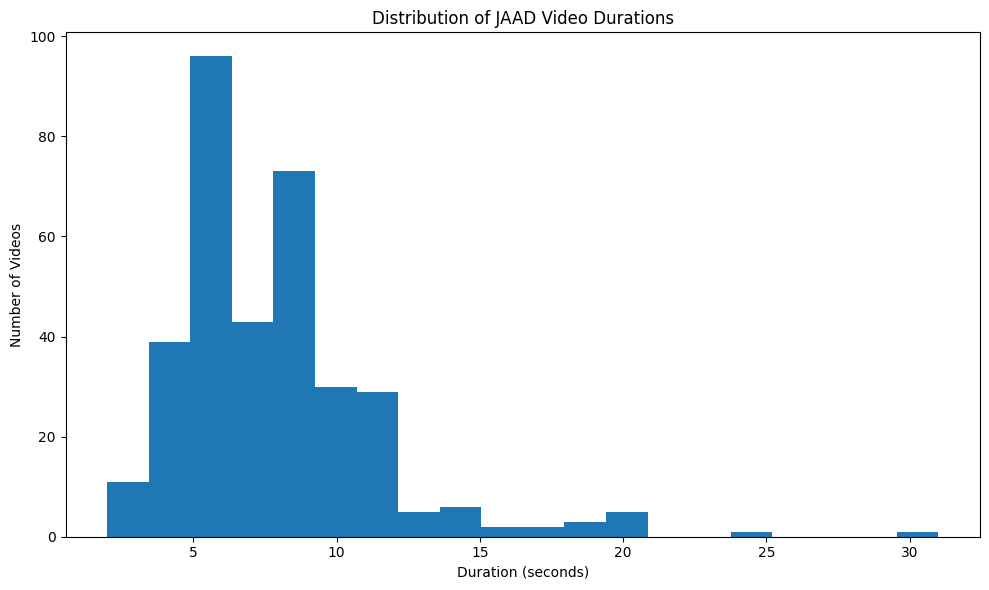

In [15]:
plt.figure(figsize=(10, 6))

plt.hist(
    video_df["duration_seconds"],
    bins=20
)

plt.title("Distribution of JAAD Video Durations")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Videos")

plt.tight_layout()
plt.show()

In [16]:
resolution_counts = (
    video_df
    .groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

print(resolution_counts)

width  height
1920   1080      336
1280   720        10
dtype: int64


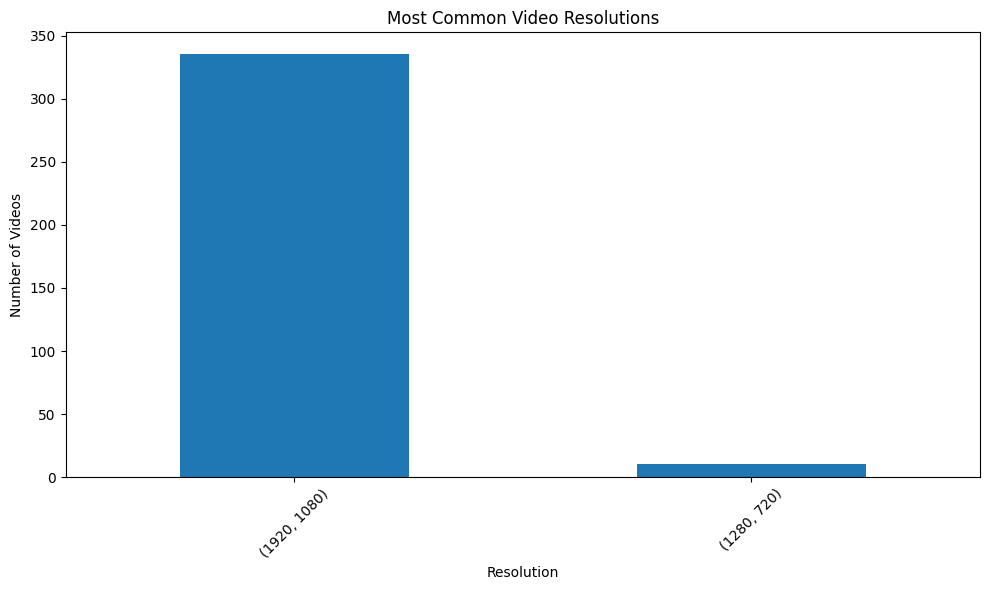

In [17]:
plt.figure(figsize=(10, 6))

resolution_counts.head(10).plot(kind="bar")

plt.title("Most Common Video Resolutions")
plt.xlabel("Resolution")
plt.ylabel("Number of Videos")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

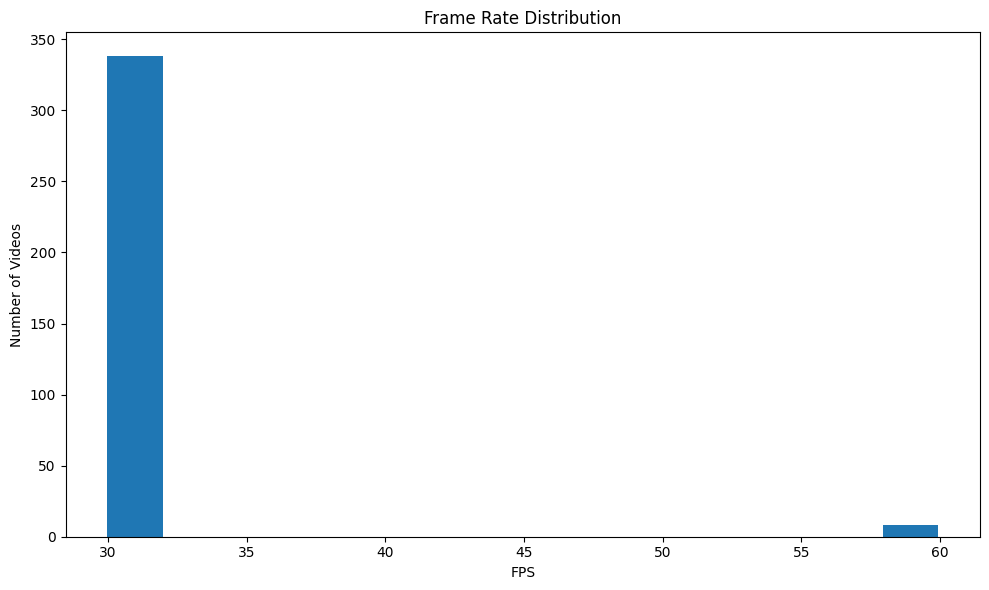

In [18]:
plt.figure(figsize=(10, 6))

plt.hist(
    video_df["fps"],
    bins=15
)

plt.title("Frame Rate Distribution")
plt.xlabel("FPS")
plt.ylabel("Number of Videos")

plt.tight_layout()
plt.show()

In [19]:
tree = ET.parse(test_annotation)
root = tree.getroot()

print("Annotation file:", test_annotation.name)
print("Root element:", root.tag)

print("\nTop-level elements:")

for child in root:
    print(child.tag, child.attrib)

Annotation file: video_0346.xml
Root element: annotations

Top-level elements:
version {}
meta {}
track {'label': 'pedestrian'}


In [20]:
tracks = root.findall(".//track")

print("Number of tracks:", len(tracks))

if len(tracks) > 0:

    first_track = tracks[0]

    print("\nFirst track attributes:")
    print(first_track.attrib)

    print("\nFirst 10 child elements:")

    for element in list(first_track)[:10]:
        print(element.tag, element.attrib)

Number of tracks: 1

First track attributes:
{'label': 'pedestrian'}

First 10 child elements:
box {'frame': '87', 'keyframe': '1', 'occluded': '0', 'outside': '0', 'xbr': '866.0', 'xtl': '846.0', 'ybr': '756.0', 'ytl': '718.0'}
box {'frame': '88', 'keyframe': '1', 'occluded': '0', 'outside': '0', 'xbr': '870.0', 'xtl': '850.0', 'ybr': '756.0', 'ytl': '718.0'}
box {'frame': '89', 'keyframe': '1', 'occluded': '0', 'outside': '0', 'xbr': '872.0', 'xtl': '852.0', 'ybr': '758.0', 'ytl': '720.0'}
box {'frame': '90', 'keyframe': '1', 'occluded': '0', 'outside': '0', 'xbr': '874.0', 'xtl': '854.0', 'ybr': '754.0', 'ytl': '716.0'}
box {'frame': '91', 'keyframe': '1', 'occluded': '0', 'outside': '0', 'xbr': '866.0', 'xtl': '846.0', 'ybr': '756.0', 'ytl': '718.0'}
box {'frame': '92', 'keyframe': '1', 'occluded': '0', 'outside': '0', 'xbr': '866.0', 'xtl': '846.0', 'ybr': '750.0', 'ytl': '712.0'}
box {'frame': '93', 'keyframe': '1', 'occluded': '0', 'outside': '0', 'xbr': '866.0', 'xtl': '846.0',

In [21]:
def inspect_xml_structure(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()

    print("=" * 70)
    print("FILE:", xml_path.name)
    print("ROOT:", root.tag)
    print("=" * 70)

    tags = Counter()

    for element in root.iter():
        tags[element.tag] += 1

    print("\nAll XML tags:")
    for tag, count in tags.most_common():
        print(f"{tag:<30} {count}")

    print("\nRoot attributes:")
    print(root.attrib)

    print("\nDirect children:")
    for child in root:
        print(
            f"Tag: {child.tag:<25} "
            f"Attributes: {child.attrib}"
        )

inspect_xml_structure(test_annotation)

FILE: video_0346.xml
ROOT: annotations

All XML tags:
attribute                      1392
box                            153
name                           4
label                          3
attributes                     3
id                             2
annotations                    1
version                        1
meta                           1
task                           1
size                           1
mode                           1
overlap                        1
bugtracker                     1
flipped                        1
created                        1
updated                        1
source                         1
labels                         1
segments                       1
segment                        1
start                          1
stop                           1
url                            1
owner                          1
username                       1
email                          1
original_size                  1
width            

In [22]:
tracks = root.findall("track")

print("Number of pedestrian tracks:", len(tracks))

for i, track in enumerate(tracks):

    print("\n" + "=" * 70)
    print("TRACK", i + 1)
    print("=" * 70)

    print("Track attributes:")
    print(track.attrib)

    boxes = track.findall("box")

    print("Number of boxes:", len(boxes))

    if boxes:

        print("\nFirst box:")
        print(boxes[0].attrib)

        print("\nAttributes inside first box:")

        for child in boxes[0]:
            print(child.tag, child.attrib)

Number of pedestrian tracks: 1

TRACK 1
Track attributes:
{'label': 'pedestrian'}
Number of boxes: 153

First box:
{'frame': '87', 'keyframe': '1', 'occluded': '0', 'outside': '0', 'xbr': '866.0', 'xtl': '846.0', 'ybr': '756.0', 'ytl': '718.0'}

Attributes inside first box:
attribute {'name': 'id'}
attribute {'name': 'old_id'}
attribute {'name': 'look'}
attribute {'name': 'reaction'}
attribute {'name': 'action'}
attribute {'name': 'cross'}
attribute {'name': 'hand_gesture'}
attribute {'name': 'occlusion'}
attribute {'name': 'nod'}


In [23]:
track_summary = []

for track_id, track in enumerate(tracks):

    boxes = track.findall("box")

    frames = []

    for box in boxes:

        if "frame" in box.attrib:
            frames.append(int(box.attrib["frame"]))

    track_summary.append({
        "track_index": track_id,
        "label": track.attrib.get("label"),
        "track_id": track.attrib.get("id"),
        "num_boxes": len(boxes),
        "start_frame": min(frames) if frames else None,
        "end_frame": max(frames) if frames else None,
        "track_length": len(frames)
    })

track_df = pd.DataFrame(track_summary)

track_df

,track_index,label,track_id,num_boxes,start_frame,end_frame,track_length
0,0,pedestrian,None,153,87,239,153


In [24]:
def parse_pedestrian_xml(xml_path):

    tree = ET.parse(xml_path)
    root = tree.getroot()

    records = []

    tracks = root.findall("track")

    for track in tracks:

        track_id = track.attrib.get("id")
        label = track.attrib.get("label")

        if label != "pedestrian":
            continue

        for box in track.findall("box"):

            frame = int(box.attrib.get("frame", -1))

            xtl = float(box.attrib.get("xtl", 0))
            ytl = float(box.attrib.get("ytl", 0))
            xbr = float(box.attrib.get("xbr", 0))
            ybr = float(box.attrib.get("ybr", 0))

            width = xbr - xtl
            height = ybr - ytl

            center_x = (xtl + xbr) / 2
            center_y = (ytl + ybr) / 2

            record = {
                "frame": frame,
                "track_id": track_id,
                "label": label,
                "xtl": xtl,
                "ytl": ytl,
                "xbr": xbr,
                "ybr": ybr,
                "width": width,
                "height": height,
                "center_x": center_x,
                "center_y": center_y
            }

            for child in box:

                if child.tag == "attribute":

                    attr_name = child.attrib.get("name")
                    attr_value = child.text

                    record[attr_name] = attr_value

            records.append(record)

    return pd.DataFrame(records)

In [25]:
def parse_pedestrian_xml(xml_path):

    tree = ET.parse(xml_path)
    root = tree.getroot()

    records = []

    for track_index, track in enumerate(root.findall("track")):

        label = track.attrib.get("label")

        if label != "pedestrian":
            continue

        for box in track.findall("box"):

            frame = int(box.attrib.get("frame", -1))

            xtl = float(box.attrib.get("xtl", 0))
            ytl = float(box.attrib.get("ytl", 0))
            xbr = float(box.attrib.get("xbr", 0))
            ybr = float(box.attrib.get("ybr", 0))

            width = xbr - xtl
            height = ybr - ytl

            center_x = (xtl + xbr) / 2
            center_y = (ytl + ybr) / 2

            record = {
                "track_index": track_index,
                "frame": frame,
                "xtl": xtl,
                "ytl": ytl,
                "xbr": xbr,
                "ybr": ybr,
                "width": width,
                "height": height,
                "center_x": center_x,
                "center_y": center_y,
                "keyframe": int(box.attrib.get("keyframe", 0)),
                "occluded": int(box.attrib.get("occluded", 0)),
                "outside": int(box.attrib.get("outside", 0))
            }

            for child in box.findall("attribute"):

                name = child.attrib.get("name")
                value = child.text.strip() if child.text else ""

                record[name] = value

            records.append(record)

    return pd.DataFrame(records)

In [26]:
pedestrian_df_0346 = parse_pedestrian_xml(test_annotation)

print("Number of records:", len(pedestrian_df_0346))

print("\nColumns:")
print(pedestrian_df_0346.columns.tolist())

print("\nFirst 10 rows:")
display(pedestrian_df_0346.head(10))

Number of records: 153

Columns:
['track_index', 'frame', 'xtl', 'ytl', 'xbr', 'ybr', 'width', 'height', 'center_x', 'center_y', 'keyframe', 'occluded', 'outside', 'id', 'old_id', 'look', 'reaction', 'action', 'cross', 'hand_gesture', 'occlusion', 'nod']

First 10 rows:


,track_index,frame,xtl,ytl,xbr,ybr,width,height,center_x,center_y,...,outside,id,old_id,look,reaction,action,cross,hand_gesture,occlusion,nod
0,0,87,846.0,718.0,866.0,756.0,20.0,38.0,856.0,737.0,...,0,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__
1,0,88,850.0,718.0,870.0,756.0,20.0,38.0,860.0,737.0,...,0,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__
2,0,89,852.0,720.0,872.0,758.0,20.0,38.0,862.0,739.0,...,0,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__
3,0,90,854.0,716.0,874.0,754.0,20.0,38.0,864.0,735.0,...,0,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__
4,0,91,846.0,718.0,866.0,756.0,20.0,38.0,856.0,737.0,...,0,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__
5,0,92,846.0,712.0,866.0,750.0,20.0,38.0,856.0,731.0,...,0,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__
6,0,93,846.0,712.0,866.0,750.0,20.0,38.0,856.0,731.0,...,0,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__
7,0,94,846.0,712.0,866.0,750.0,20.0,38.0,856.0,731.0,...,0,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__
8,0,95,844.0,707.0,859.0,745.0,15.0,38.0,851.5,726.0,...,0,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__
9,0,96,844.0,707.0,859.0,745.0,15.0,38.0,851.5,726.0,...,0,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__


In [27]:
behavior_columns = [
    "look",
    "reaction",
    "action",
    "cross",
    "hand_gesture",
    "occlusion",
    "nod"
]

for column in behavior_columns:

    print("\n" + "=" * 60)
    print(column.upper())
    print("=" * 60)

    display(
        pedestrian_df_0346[column]
        .value_counts(dropna=False)
    )


LOOK


look
not-looking    153
Name: count, dtype: int64


REACTION


reaction
__undefined__    153
Name: count, dtype: int64


ACTION


action
walking    153
Name: count, dtype: int64

... (4 outputs left out)


OCCLUSION


occlusion
none    153
Name: count, dtype: int64


NOD


nod
__undefined__    153
Name: count, dtype: int64

In [28]:
print("Unique pedestrian IDs:")

display(
    pedestrian_df_0346["id"].value_counts(dropna=False)
)

print("\nUnique old IDs:")

display(
    pedestrian_df_0346["old_id"].value_counts(dropna=False)
)

Unique pedestrian IDs:


id
0_346_2703b    153
Name: count, dtype: int64


Unique old IDs:


old_id
pedestrian    153
Name: count, dtype: int64

In [29]:
missing_values = pedestrian_df_0346.isnull().sum()

print("Missing values:")

display(
    missing_values[
        missing_values > 0
    ].sort_values(ascending=False)
)

Missing values:


Series([], dtype: int64)

In [30]:
undefined_counts = {}

for column in behavior_columns:

    if column in pedestrian_df_0346.columns:

        undefined_counts[column] = (
            pedestrian_df_0346[column]
            .astype(str)
            .str.contains("__undefined__", na=False)
            .sum()
        )

undefined_df = pd.DataFrame(
    list(undefined_counts.items()),
    columns=["attribute", "undefined_count"]
)

undefined_df["undefined_percentage"] = (
    undefined_df["undefined_count"]
    / len(pedestrian_df_0346)
    * 100
)

display(undefined_df)

,attribute,undefined_count,undefined_percentage
0,look,0,0.0
1,reaction,153,100.0
2,action,0,0.0
3,cross,0,0.0
4,hand_gesture,153,100.0
5,occlusion,0,0.0
6,nod,153,100.0


In [31]:
duplicate_count = pedestrian_df_0346.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


In [32]:
invalid_boxes = pedestrian_df_0346[
    (pedestrian_df_0346["width"] <= 0) |
    (pedestrian_df_0346["height"] <= 0) |
    (pedestrian_df_0346["xbr"] <= pedestrian_df_0346["xtl"]) |
    (pedestrian_df_0346["ybr"] <= pedestrian_df_0346["ytl"])
]

print("Invalid bounding boxes:", len(invalid_boxes))

if len(invalid_boxes) > 0:
    display(invalid_boxes.head())

Invalid bounding boxes: 0


In [33]:
pedestrian_df_0346_clean = pedestrian_df_0346.copy()

pedestrian_df_0346_clean = pedestrian_df_0346_clean[
    (pedestrian_df_0346_clean["width"] > 0) &
    (pedestrian_df_0346_clean["height"] > 0) &
    (pedestrian_df_0346_clean["xbr"] > pedestrian_df_0346_clean["xtl"]) &
    (pedestrian_df_0346_clean["ybr"] > pedestrian_df_0346_clean["ytl"])
]

pedestrian_df_0346_clean = (
    pedestrian_df_0346_clean
    .drop_duplicates()
    .sort_values("frame")
    .reset_index(drop=True)
)

print("Original records:", len(pedestrian_df_0346))
print("Clean records:", len(pedestrian_df_0346_clean))
print(
    "Removed records:",
    len(pedestrian_df_0346) -
    len(pedestrian_df_0346_clean)
)

Original records: 153
Clean records: 153
Removed records: 0


In [34]:
print("=" * 65)
print("JAAD VIDEO 0346 — DATASET SUMMARY")
print("=" * 65)

print("Annotated records:",
      len(pedestrian_df_0346_clean))

print("Unique pedestrians:",
      pedestrian_df_0346_clean["id"].nunique())

print("Unique frames:",
      pedestrian_df_0346_clean["frame"].nunique())

print("Frame range:",
      pedestrian_df_0346_clean["frame"].min(),
      "to",
      pedestrian_df_0346_clean["frame"].max())

print("Average bounding-box width:",
      round(pedestrian_df_0346_clean["width"].mean(), 2))

print("Average bounding-box height:",
      round(pedestrian_df_0346_clean["height"].mean(), 2))

print("Average center X:",
      round(pedestrian_df_0346_clean["center_x"].mean(), 2))

print("Average center Y:",
      round(pedestrian_df_0346_clean["center_y"].mean(), 2))

JAAD VIDEO 0346 — DATASET SUMMARY
Annotated records: 153
Unique pedestrians: 1
Unique frames: 153
Frame range: 87 to 239
Average bounding-box width: 39.75
Average bounding-box height: 88.86
Average center X: 892.65
Average center Y: 743.68


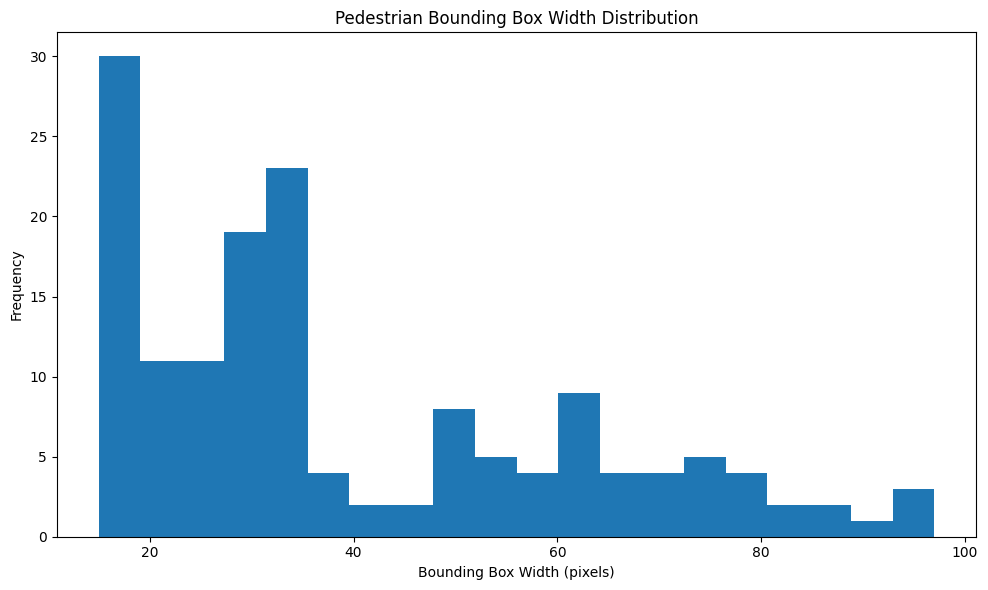

In [35]:
plt.figure(figsize=(10, 6))

plt.hist(
    pedestrian_df_0346_clean["width"],
    bins=20
)

plt.title("Pedestrian Bounding Box Width Distribution")
plt.xlabel("Bounding Box Width (pixels)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

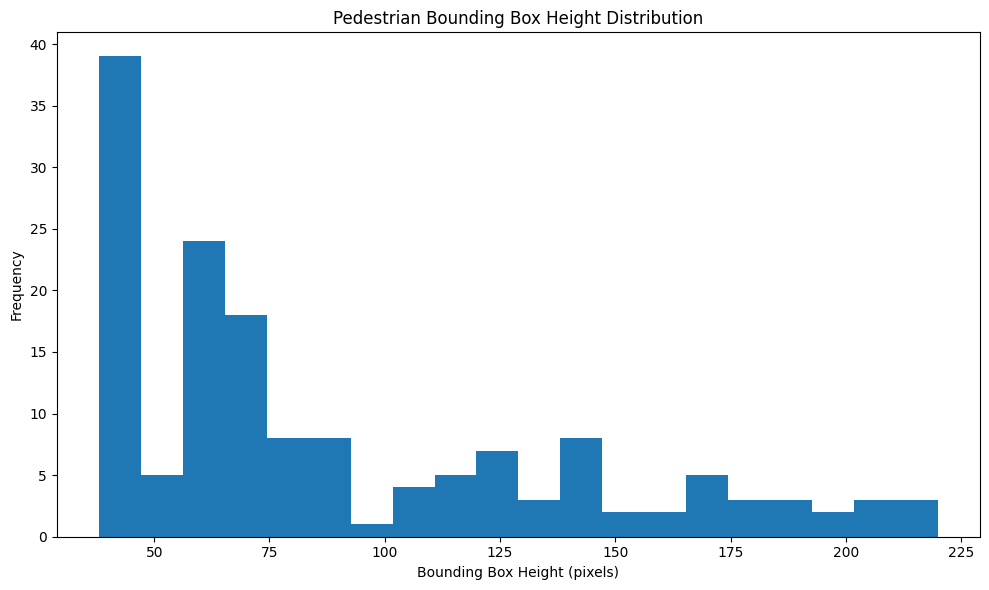

In [36]:
plt.figure(figsize=(10, 6))

plt.hist(
    pedestrian_df_0346_clean["height"],
    bins=20
)

plt.title("Pedestrian Bounding Box Height Distribution")
plt.xlabel("Bounding Box Height (pixels)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

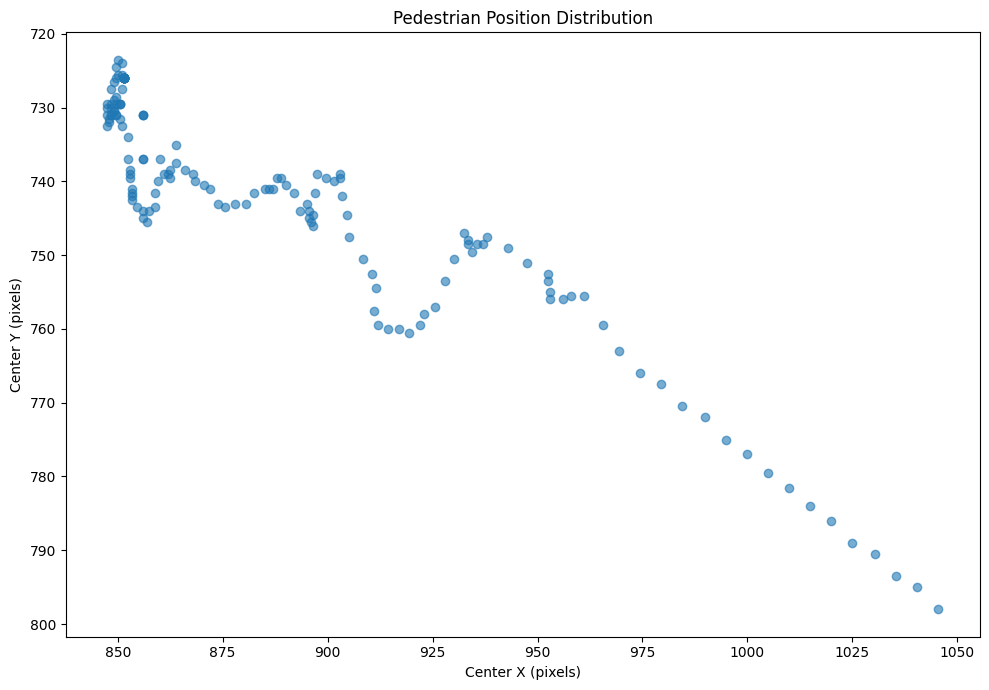

In [37]:
plt.figure(figsize=(10, 7))

plt.scatter(
    pedestrian_df_0346_clean["center_x"],
    pedestrian_df_0346_clean["center_y"],
    alpha=0.6
)

plt.gca().invert_yaxis()

plt.title("Pedestrian Position Distribution")
plt.xlabel("Center X (pixels)")
plt.ylabel("Center Y (pixels)")

plt.tight_layout()
plt.show()

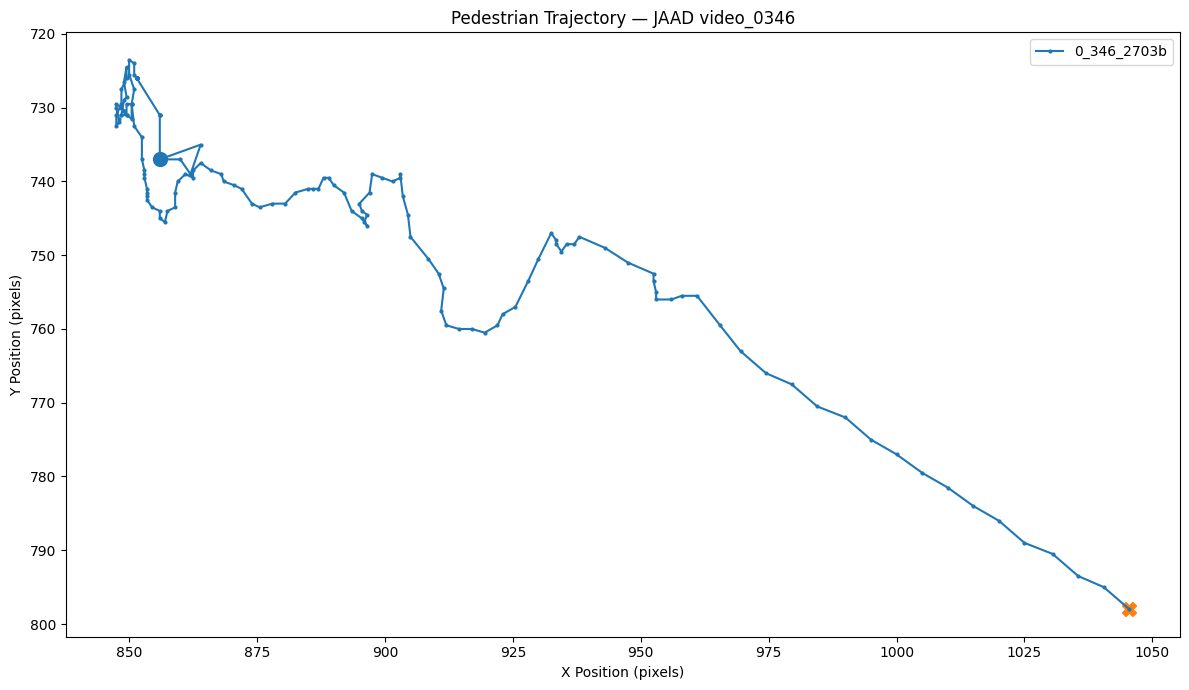

In [38]:
plt.figure(figsize=(12, 7))

for pedestrian_id, group in pedestrian_df_0346_clean.groupby("id"):

    group = group.sort_values("frame")

    plt.plot(
        group["center_x"],
        group["center_y"],
        marker=".",
        markersize=4,
        label=pedestrian_id
    )

    plt.scatter(
        group["center_x"].iloc[0],
        group["center_y"].iloc[0],
        s=100,
        marker="o"
    )

    plt.scatter(
        group["center_x"].iloc[-1],
        group["center_y"].iloc[-1],
        s=100,
        marker="X"
    )

plt.gca().invert_yaxis()

plt.title("Pedestrian Trajectory — JAAD video_0346")
plt.xlabel("X Position (pixels)")
plt.ylabel("Y Position (pixels)")
plt.legend()

plt.tight_layout()
plt.show()

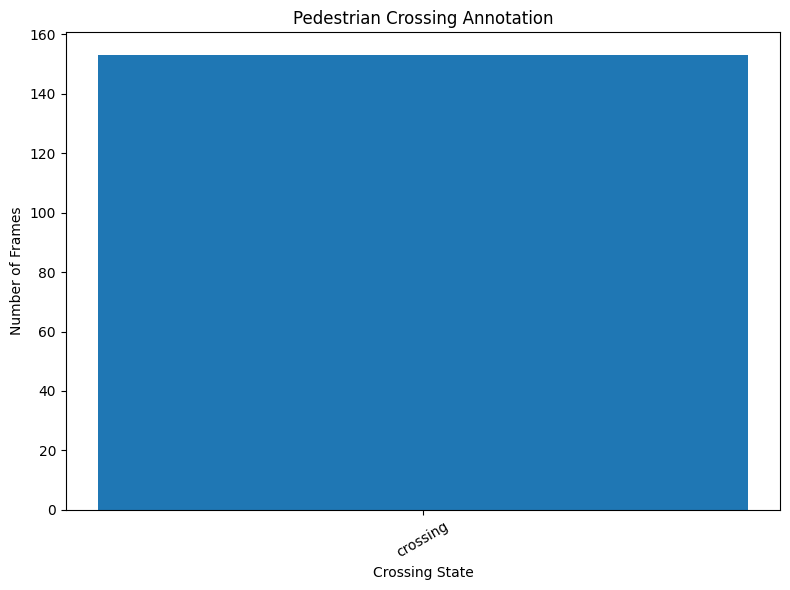

In [39]:
    cross_counts = (
    pedestrian_df_0346_clean["cross"]
    .astype(str)
    .value_counts()
)

plt.figure(figsize=(8, 6))

plt.bar(
    cross_counts.index,
    cross_counts.values
)

plt.title("Pedestrian Crossing Annotation")
plt.xlabel("Crossing State")
plt.ylabel("Number of Frames")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

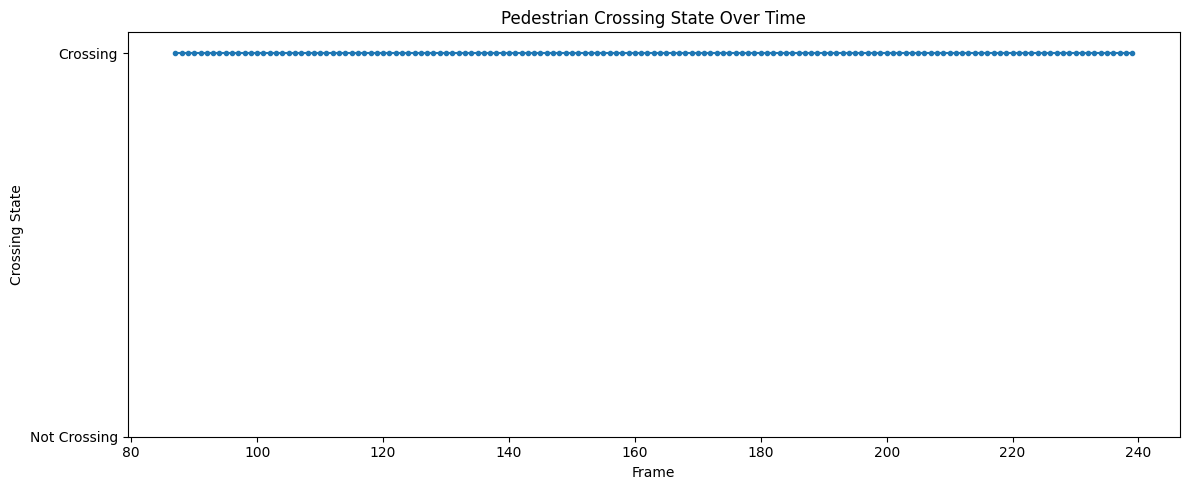

In [40]:
cross_mapping = {
    "not-crossing": 0,
    "crossing": 1
}

cross_numeric = (
    pedestrian_df_0346_clean["cross"]
    .astype(str)
    .map(cross_mapping)
)

plt.figure(figsize=(12, 5))

plt.plot(
    pedestrian_df_0346_clean["frame"],
    cross_numeric,
    marker="."
)

plt.title("Pedestrian Crossing State Over Time")
plt.xlabel("Frame")
plt.ylabel("Crossing State")

plt.yticks(
    [0, 1],
    ["Not Crossing", "Crossing"]
)

plt.tight_layout()
plt.show()

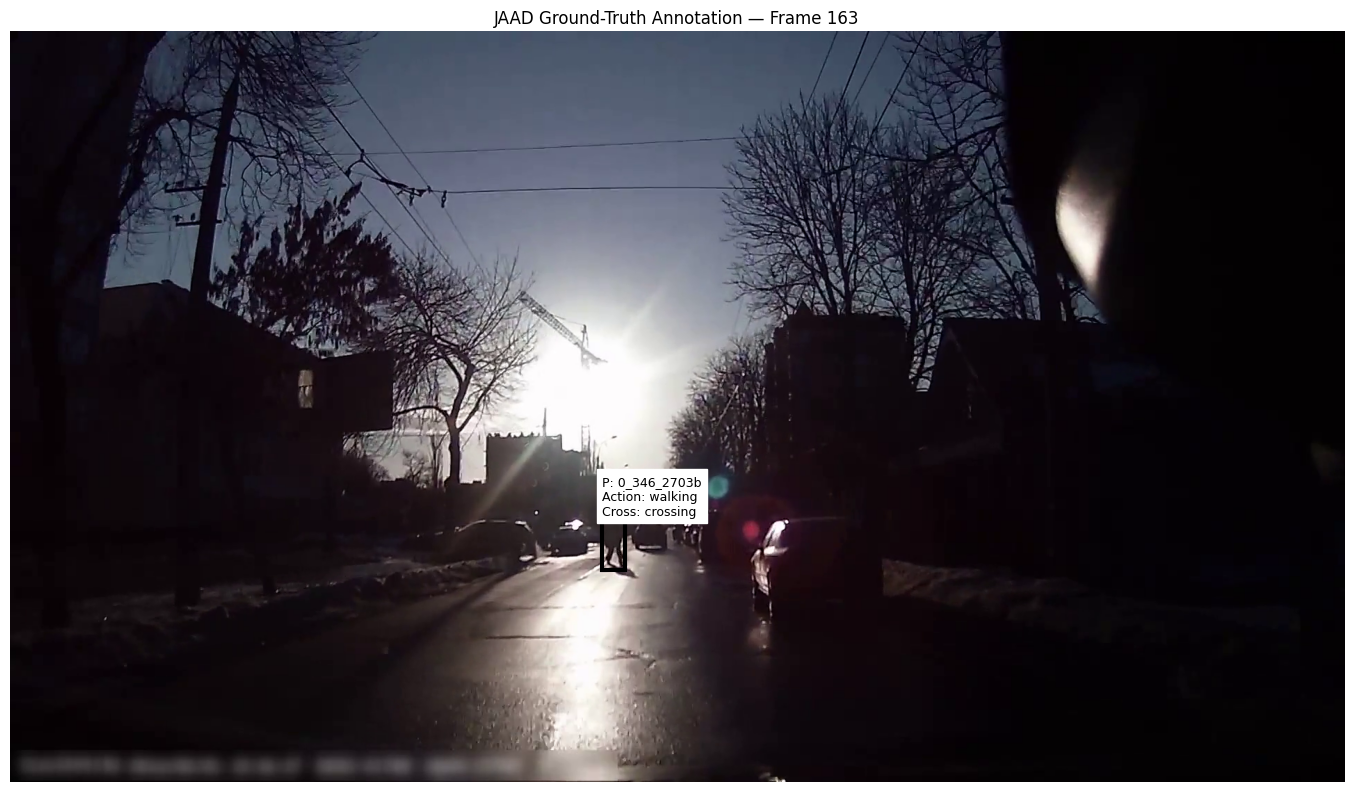

In [41]:
frame_number = int(
    pedestrian_df_0346_clean["frame"].iloc[
        len(pedestrian_df_0346_clean) // 2
    ]
)

cap = cv2.VideoCapture(str(test_video))

cap.set(
    cv2.CAP_PROP_POS_FRAMES,
    frame_number
)

success, frame = cap.read()

cap.release()

if success:

    frame_rgb = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    frame_data = pedestrian_df_0346_clean[
        pedestrian_df_0346_clean["frame"] == frame_number
    ]

    plt.figure(figsize=(14, 8))

    plt.imshow(frame_rgb)

    ax = plt.gca()

    for _, row in frame_data.iterrows():

        rectangle = plt.Rectangle(
            (row["xtl"], row["ytl"]),
            row["width"],
            row["height"],
            fill=False,
            linewidth=3
        )

        ax.add_patch(rectangle)

        label = (
            f"P: {row['id']}\n"
            f"Action: {row['action']}\n"
            f"Cross: {row['cross']}"
        )

        ax.text(
            row["xtl"],
            max(0, row["ytl"] - 10),
            label,
            fontsize=9,
            backgroundcolor="white"
        )

    plt.title(
        f"JAAD Ground-Truth Annotation — Frame {frame_number}"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [42]:
traffic_files = sorted(TRAFFIC_DIR.glob("*.xml"))

print("Number of traffic XML files:", len(traffic_files))

print("\nFirst 20 files:")

for file in traffic_files[:20]:
    print(file.name)

Number of traffic XML files: 346

First 20 files:
video_0001_traffic.xml
video_0002_traffic.xml
video_0003_traffic.xml
video_0004_traffic.xml
video_0005_traffic.xml
video_0006_traffic.xml
video_0007_traffic.xml
video_0008_traffic.xml
video_0009_traffic.xml
video_0010_traffic.xml
video_0011_traffic.xml
video_0012_traffic.xml
video_0013_traffic.xml
video_0014_traffic.xml
video_0015_traffic.xml
video_0016_traffic.xml
video_0017_traffic.xml
video_0018_traffic.xml
video_0019_traffic.xml
video_0020_traffic.xml


In [43]:
matching_traffic = [
    f for f in traffic_files
    if "0346" in f.stem
]

print("Matching traffic files:")

for file in matching_traffic:
    print(file)

Matching traffic files:
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations_traffic\video_0346_traffic.xml


In [44]:
traffic_xml = matching_traffic[0]

traffic_tree = ET.parse(traffic_xml)
traffic_root = traffic_tree.getroot()

print("=" * 70)
print("TRAFFIC XML")
print("=" * 70)

print("File:", traffic_xml.name)
print("Root:", traffic_root.tag)

traffic_tags = Counter()

for element in traffic_root.iter():
    traffic_tags[element.tag] += 1

print("\nAll tags:")

for tag, count in traffic_tags.most_common():
    print(f"{tag:<30} {count}")

print("\nDirect children:")

for child in traffic_root:
    print(
        f"Tag: {child.tag:<25}"
        f"Attributes: {child.attrib}"
    )

TRAFFIC XML
File: video_0346_traffic.xml
Root: traffic_scene

All tags:
frame                          240
traffic_scene                  1
road_type                      1

Direct children:
Tag: road_type                Attributes: {}
Tag: frame                    Attributes: {'id': '0', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                    Attributes: {'id': '1', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                    Attributes: {'id': '2', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                    Attributes: {'id': '3', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                    Attributes: {'id': '4', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                    Attributes: {'id': '5', 'ped_crossing': '0', 'ped_sign': '0', 's

In [45]:
traffic_tracks = traffic_root.findall(".//track")

print("Number of traffic tracks:", len(traffic_tracks))

for i, track in enumerate(traffic_tracks[:10]):

    print("\n" + "=" * 60)
    print("TRAFFIC TRACK", i + 1)
    print("=" * 60)

    print("Track attributes:")
    print(track.attrib)

    boxes = track.findall("box")

    print("Number of boxes:", len(boxes))

    if boxes:

        print("\nFirst box:")
        print(boxes[0].attrib)

        print("\nAttributes inside first box:")

        for child in boxes[0]:
            print(child.tag, child.attrib)

Number of traffic tracks: 0


In [46]:
print("=" * 70)
print("TRAFFIC XML STRUCTURE")
print("=" * 70)

print("Root:", traffic_root.tag)
print("Root attributes:", traffic_root.attrib)

print("\nDirect children:")

for child in traffic_root:
    print(
        f"Tag: {child.tag:<30}"
        f"Attributes: {child.attrib}"
    )

TRAFFIC XML STRUCTURE
Root: traffic_scene
Root attributes: {}

Direct children:
Tag: road_type                     Attributes: {}
Tag: frame                         Attributes: {'id': '0', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                         Attributes: {'id': '1', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                         Attributes: {'id': '2', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                         Attributes: {'id': '3', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                         Attributes: {'id': '4', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                         Attributes: {'id': '5', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                         A

In [47]:
for element in traffic_root.iter():

    if element.attrib:
        print(
            f"Tag: {element.tag:<25} "
            f"Attributes: {element.attrib}"
        )

Tag: frame                     Attributes: {'id': '0', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                     Attributes: {'id': '1', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                     Attributes: {'id': '2', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                     Attributes: {'id': '3', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                     Attributes: {'id': '4', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                     Attributes: {'id': '5', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                     Attributes: {'id': '6', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}
Tag: frame                     Attributes: {'id': '7', 

In [48]:
traffic_element_counts = Counter(
    element.tag
    for element in traffic_root.iter()
)

print("Traffic XML element counts:")

for tag, count in traffic_element_counts.most_common():
    print(f"{tag:<30} {count}")

Traffic XML element counts:
frame                          240
traffic_scene                  1
road_type                      1


In [49]:
frames = traffic_root.findall(".//frame")

print("Number of frame elements:", len(frames))

for i, frame in enumerate(frames[:5]):

    print("\n" + "=" * 70)
    print("FRAME", i + 1)
    print("=" * 70)

    print("Frame attributes:")
    print(frame.attrib)

    print("\nChild elements:")

    for child in frame:
        print(
            f"Tag: {child.tag:<30}"
            f"Attributes: {child.attrib}"
        )

Number of frame elements: 240

FRAME 1
Frame attributes:
{'id': '0', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}

Child elements:

FRAME 2
Frame attributes:
{'id': '1', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}

Child elements:

FRAME 3
Frame attributes:
{'id': '2', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}

Child elements:

FRAME 4
Frame attributes:
{'id': '3', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}

Child elements:

FRAME 5
Frame attributes:
{'id': '4', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}

Child elements:


In [50]:
first_frame = frames[0]

print("=" * 70)
print("FIRST TRAFFIC FRAME")
print("=" * 70)

print("Frame attributes:")
print(first_frame.attrib)

print("\nAll nested elements:")

for element in first_frame.iter():
    print(
        f"Tag: {element.tag:<30}"
        f"Attributes: {element.attrib}"
    )

FIRST TRAFFIC FRAME
Frame attributes:
{'id': '0', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}

All nested elements:
Tag: frame                         Attributes: {'id': '0', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}


In [51]:
middle_frame = frames[len(frames) // 2]

print("=" * 70)
print("MIDDLE TRAFFIC FRAME")
print("=" * 70)

print("Frame attributes:")
print(middle_frame.attrib)

print("\nAll nested elements:")

for element in middle_frame.iter():
    print(
        f"Tag: {element.tag:<30}"
        f"Attributes: {element.attrib}"
    )

MIDDLE TRAFFIC FRAME
Frame attributes:
{'id': '120', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}

All nested elements:
Tag: frame                         Attributes: {'id': '120', 'ped_crossing': '0', 'ped_sign': '0', 'stop_sign': '0', 'traffic_light': 'n/a'}


In [52]:
traffic_data = pd.DataFrame(
    [frame.attrib for frame in frames]
)

print("Traffic dataframe shape:", traffic_data.shape)

display(traffic_data.head())

print("\nUnique values:")
for column in traffic_data.columns:
    print("\n" + column)
    print(traffic_data[column].value_counts(dropna=False))

Traffic dataframe shape: (240, 5)


,id,ped_crossing,ped_sign,stop_sign,traffic_light
0,0,0,0,0,n/a
1,1,0,0,0,n/a
2,2,0,0,0,n/a
3,3,0,0,0,n/a
4,4,0,0,0,n/a



Unique values:

id
id
0      1
1      1
2      1
3      1
4      1
      ..
235    1
236    1
237    1
238    1
239    1
Name: count, Length: 240, dtype: int64

ped_crossing
ped_crossing
0    240
Name: count, dtype: int64

ped_sign
ped_sign
0    240
Name: count, dtype: int64

stop_sign
stop_sign
0    240
Name: count, dtype: int64

traffic_light
traffic_light
n/a    240
Name: count, dtype: int64


In [55]:
traffic_data = pd.DataFrame(
    [frame.attrib for frame in frames]
)

traffic_data["frame"] = traffic_data["id"].astype(int)

traffic_data = traffic_data.drop(columns=["id"])

for column in [
    "ped_crossing",
    "ped_sign",
    "stop_sign"
]:
    traffic_data[column] = pd.to_numeric(
        traffic_data[column],
        errors="coerce"
    )

print("Columns:")
print(list(traffic_data.columns))

print("\nData types:")
print(traffic_data.dtypes)

display(traffic_data.head())

Columns:
['ped_crossing', 'ped_sign', 'stop_sign', 'traffic_light', 'frame']

Data types:
ped_crossing      int64
ped_sign          int64
stop_sign         int64
traffic_light    object
frame             int64
dtype: object


,ped_crossing,ped_sign,stop_sign,traffic_light,frame
0,0,0,0,n/a,0
1,0,0,0,n/a,1
2,0,0,0,n/a,2
3,0,0,0,n/a,3
4,0,0,0,n/a,4


In [56]:
print("=" * 65)
print("TRAFFIC ANNOTATION SUMMARY — VIDEO 0346")
print("=" * 65)

print("Number of traffic frames:",
      len(traffic_data))

print("Frame range:",
      traffic_data["frame"].min(),
      "to",
      traffic_data["frame"].max())

print("\nPedestrian crossings/signs:")
print(
    traffic_data["ped_crossing"]
    .value_counts(dropna=False)
)

print("\nPedestrian signs:")
print(
    traffic_data["ped_sign"]
    .value_counts(dropna=False)
)

print("\nStop signs:")
print(
    traffic_data["stop_sign"]
    .value_counts(dropna=False)
)

print("\nTraffic lights:")
print(
    traffic_data["traffic_light"]
    .value_counts(dropna=False)
)

TRAFFIC ANNOTATION SUMMARY — VIDEO 0346
Number of traffic frames: 240
Frame range: 0 to 239

Pedestrian crossings/signs:
ped_crossing
0    240
Name: count, dtype: int64

Pedestrian signs:
ped_sign
0    240
Name: count, dtype: int64

Stop signs:
stop_sign
0    240
Name: count, dtype: int64

Traffic lights:
traffic_light
n/a    240
Name: count, dtype: int64


In [57]:
merged_0346 = pedestrian_df_0346_clean.merge(
    traffic_data,
    on="frame",
    how="left"
)

print("Merged dataframe shape:",
      merged_0346.shape)

display(merged_0346.head())

Merged dataframe shape: (153, 26)


,track_index,frame,xtl,ytl,xbr,ybr,width,height,center_x,center_y,...,reaction,action,cross,hand_gesture,occlusion,nod,ped_crossing,ped_sign,stop_sign,traffic_light
0,0,87,846.0,718.0,866.0,756.0,20.0,38.0,856.0,737.0,...,__undefined__,walking,crossing,__undefined__,none,__undefined__,0,0,0,n/a
1,0,88,850.0,718.0,870.0,756.0,20.0,38.0,860.0,737.0,...,__undefined__,walking,crossing,__undefined__,none,__undefined__,0,0,0,n/a
2,0,89,852.0,720.0,872.0,758.0,20.0,38.0,862.0,739.0,...,__undefined__,walking,crossing,__undefined__,none,__undefined__,0,0,0,n/a
3,0,90,854.0,716.0,874.0,754.0,20.0,38.0,864.0,735.0,...,__undefined__,walking,crossing,__undefined__,none,__undefined__,0,0,0,n/a
4,0,91,846.0,718.0,866.0,756.0,20.0,38.0,856.0,737.0,...,__undefined__,walking,crossing,__undefined__,none,__undefined__,0,0,0,n/a


In [58]:
print("=" * 65)
print("MERGE VALIDATION")
print("=" * 65)

print("Pedestrian records:",
      len(pedestrian_df_0346_clean))

print("Merged records:",
      len(merged_0346))

print(
    "Traffic information missing:",
    merged_0346["traffic_light"].isna().sum()
)

print("\nMerged columns:")
print(list(merged_0346.columns))

MERGE VALIDATION
Pedestrian records: 153
Merged records: 153
Traffic information missing: 0

Merged columns:
['track_index', 'frame', 'xtl', 'ytl', 'xbr', 'ybr', 'width', 'height', 'center_x', 'center_y', 'keyframe', 'occluded', 'outside', 'id', 'old_id', 'look', 'reaction', 'action', 'cross', 'hand_gesture', 'occlusion', 'nod', 'ped_crossing', 'ped_sign', 'stop_sign', 'traffic_light']


In [61]:
from pathlib import Path
import pandas as pd
import numpy as np
import xml.etree.ElementTree as ET
from collections import Counter
import cv2
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(
    r"D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety"
)

JAAD_ROOT = PROJECT_ROOT / "JAAD_dataset"

JAAD_CLIPS_DIR = JAAD_ROOT / "JAAD_clips"
ANNOTATIONS_DIR = JAAD_ROOT / "annotations"
TRAFFIC_DIR = JAAD_ROOT / "annotations_traffic"

print("=" * 70)
print("JAAD PATH CHECK")
print("=" * 70)

print("Project root:", PROJECT_ROOT)
print("JAAD root:", JAAD_ROOT)
print("Video directory:", JAAD_CLIPS_DIR)
print("Pedestrian annotations:", ANNOTATIONS_DIR)
print("Traffic annotations:", TRAFFIC_DIR)

print("\nDirectory existence:")

print("Videos:", JAAD_CLIPS_DIR.exists())
print("Pedestrian annotations:", ANNOTATIONS_DIR.exists())
print("Traffic annotations:", TRAFFIC_DIR.exists())

JAAD PATH CHECK
Project root: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety
JAAD root: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset
Video directory: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\JAAD_clips
Pedestrian annotations: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations
Traffic annotations: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations_traffic

Directory existence:
Videos: True
Pedestrian annotations: True
Traffic annotations: True


In [62]:
video_files = sorted(JAAD_CLIPS_DIR.glob("*.mp4"))
pedestrian_xml_files = sorted(ANNOTATIONS_DIR.glob("*.xml"))
traffic_xml_files = sorted(TRAFFIC_DIR.glob("*.xml"))

print("=" * 70)
print("FULL JAAD DATASET FILE CHECK")
print("=" * 70)

print("Video files:", len(video_files))
print("Pedestrian XML files:", len(pedestrian_xml_files))
print("Traffic XML files:", len(traffic_xml_files))

print("\nFirst 5 videos:")

for f in video_files[:5]:
    print(f.name)

print("\nLast 5 videos:")

for f in video_files[-5:]:
    print(f.name)

FULL JAAD DATASET FILE CHECK
Video files: 346
Pedestrian XML files: 346
Traffic XML files: 346

First 5 videos:
video_0001.mp4
video_0002.mp4
video_0003.mp4
video_0004.mp4
video_0005.mp4

Last 5 videos:
video_0342.mp4
video_0343.mp4
video_0344.mp4
video_0345.mp4
video_0346.mp4


In [63]:
video_ids = {
    f.stem
    for f in video_files
}

pedestrian_ids = {
    f.stem
    for f in pedestrian_xml_files
}

traffic_ids = {
    f.stem.replace("_traffic", "")
    for f in traffic_xml_files
}

print("=" * 70)
print("DATASET MATCHING CHECK")
print("=" * 70)

videos_without_pedestrian_xml = video_ids - pedestrian_ids
pedestrian_without_video = pedestrian_ids - video_ids
videos_without_traffic_xml = video_ids - traffic_ids
traffic_without_video = traffic_ids - video_ids

print(
    "Videos without pedestrian XML:",
    len(videos_without_pedestrian_xml)
)

print(
    "Pedestrian XML without video:",
    len(pedestrian_without_video)
)

print(
    "Videos without traffic XML:",
    len(videos_without_traffic_xml)
)

print(
    "Traffic XML without video:",
    len(traffic_without_video)
)

print("\nExamples:")

print(
    "\nVideos without pedestrian XML:",
    sorted(videos_without_pedestrian_xml)[:10]
)

print(
    "\nVideos without traffic XML:",
    sorted(videos_without_traffic_xml)[:10]
)

DATASET MATCHING CHECK
Videos without pedestrian XML: 0
Pedestrian XML without video: 0
Videos without traffic XML: 0
Traffic XML without video: 0

Examples:

Videos without pedestrian XML: []

Videos without traffic XML: []


In [64]:
video_map = {
    f.stem: f
    for f in video_files
}

pedestrian_xml_map = {
    f.stem: f
    for f in pedestrian_xml_files
}

traffic_xml_map = {
    f.stem.replace("_traffic", ""): f
    for f in traffic_xml_files
}

common_video_ids = sorted(
    video_ids &
    pedestrian_ids &
    traffic_ids
)

print("=" * 70)
print("COMMON DATASET")
print("=" * 70)

print(
    "Videos available in all three sources:",
    len(common_video_ids)
)

print("\nFirst 10:")
print(common_video_ids[:10])

print("\nLast 10:")
print(common_video_ids[-10:])

COMMON DATASET
Videos available in all three sources: 346

First 10:
['video_0001', 'video_0002', 'video_0003', 'video_0004', 'video_0005', 'video_0006', 'video_0007', 'video_0008', 'video_0009', 'video_0010']

Last 10:
['video_0337', 'video_0338', 'video_0339', 'video_0340', 'video_0341', 'video_0342', 'video_0343', 'video_0344', 'video_0345', 'video_0346']


In [ ]:
OUTPUT_DIR = PROJECT_ROOT / "processed_data"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Processed data directory:")
print(OUTPUT_DIR)

print("Directory exists:", OUTPUT_DIR.exists())

Processed data directory:
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\processed_data
Directory exists: True


In [66]:
def parse_pedestrian_xml(xml_path):

    tree = ET.parse(xml_path)
    root = tree.getroot()

    records = []

    tracks = root.findall(".//track")

    for track_index, track in enumerate(tracks):

        track_label = track.attrib.get(
            "label",
            "unknown"
        )

        for box in track.findall("box"):

            record = {
                "track_index": track_index,
                "label": track_label,
                "frame": int(
                    box.attrib.get("frame", -1)
                ),
                "xtl": float(
                    box.attrib.get("xtl", 0)
                ),
                "ytl": float(
                    box.attrib.get("ytl", 0)
                ),
                "xbr": float(
                    box.attrib.get("xbr", 0)
                ),
                "ybr": float(
                    box.attrib.get("ybr", 0)
                ),
                "keyframe": int(
                    box.attrib.get("keyframe", 0)
                ),
                "occluded": int(
                    box.attrib.get("occluded", 0)
                ),
                "outside": int(
                    box.attrib.get("outside", 0)
                )
            }

            record["width"] = (
                record["xbr"] -
                record["xtl"]
            )

            record["height"] = (
                record["ybr"] -
                record["ytl"]
            )

            record["center_x"] = (
                record["xtl"] +
                record["xbr"]
            ) / 2

            record["center_y"] = (
                record["ytl"] +
                record["ybr"]
            ) / 2

            attributes = {}

            for attribute in box.findall("attribute"):

                name = attribute.attrib.get(
                    "name",
                    "unknown"
                )

                value = (
                    attribute.text.strip()
                    if attribute.text
                    else "__undefined__"
                )

                attributes[name] = value

            for name in [
                "id",
                "old_id",
                "look",
                "reaction",
                "action",
                "cross",
                "hand_gesture",
                "occlusion",
                "nod"
            ]:

                record[name] = attributes.get(
                    name,
                    "__undefined__"
                )

            record["video_id"] = xml_path.stem

            records.append(record)

    return pd.DataFrame(records)

In [67]:
test_parsed_df = parse_pedestrian_xml(
    pedestrian_xml_map["video_0346"]
)

print("=" * 70)
print("GENERALIZED PARSER TEST — VIDEO 0346")
print("=" * 70)

print("Records:", len(test_parsed_df))

print("\nColumns:")
print(list(test_parsed_df.columns))

print("\nFirst 5 records:")
display(test_parsed_df.head())

GENERALIZED PARSER TEST — VIDEO 0346
Records: 153

Columns:
['track_index', 'label', 'frame', 'xtl', 'ytl', 'xbr', 'ybr', 'keyframe', 'occluded', 'outside', 'width', 'height', 'center_x', 'center_y', 'id', 'old_id', 'look', 'reaction', 'action', 'cross', 'hand_gesture', 'occlusion', 'nod', 'video_id']

First 5 records:


,track_index,label,frame,xtl,ytl,xbr,ybr,keyframe,occluded,outside,...,id,old_id,look,reaction,action,cross,hand_gesture,occlusion,nod,video_id
0,0,pedestrian,87,846.0,718.0,866.0,756.0,1,0,0,...,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__,video_0346
1,0,pedestrian,88,850.0,718.0,870.0,756.0,1,0,0,...,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__,video_0346
2,0,pedestrian,89,852.0,720.0,872.0,758.0,1,0,0,...,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__,video_0346
3,0,pedestrian,90,854.0,716.0,874.0,754.0,1,0,0,...,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__,video_0346
4,0,pedestrian,91,846.0,718.0,866.0,756.0,1,0,0,...,0_346_2703b,pedestrian,not-looking,__undefined__,walking,crossing,__undefined__,none,__undefined__,video_0346


In [68]:
def parse_traffic_xml(xml_path):

    tree = ET.parse(xml_path)
    root = tree.getroot()

    frames = root.findall(".//frame")

    records = []

    for frame in frames:

        record = {
            "frame": int(
                frame.attrib.get("id", -1)
            ),
            "ped_crossing": int(
                frame.attrib.get("ped_crossing", 0)
            ),
            "ped_sign": int(
                frame.attrib.get("ped_sign", 0)
            ),
            "stop_sign": int(
                frame.attrib.get("stop_sign", 0)
            ),
            "traffic_light": frame.attrib.get(
                "traffic_light",
                "n/a"
            )
        }

        records.append(record)

    return pd.DataFrame(records)

In [69]:
test_traffic_df = parse_traffic_xml(
    traffic_xml_map["video_0346"]
)

print("=" * 70)
print("GENERALIZED TRAFFIC PARSER TEST — VIDEO 0346")
print("=" * 70)

print("Records:", len(test_traffic_df))

print("\nColumns:")
print(list(test_traffic_df.columns))

display(test_traffic_df.head())

GENERALIZED TRAFFIC PARSER TEST — VIDEO 0346
Records: 240

Columns:
['frame', 'ped_crossing', 'ped_sign', 'stop_sign', 'traffic_light']


,frame,ped_crossing,ped_sign,stop_sign,traffic_light
0,0,0,0,0,n/a
1,1,0,0,0,n/a
2,2,0,0,0,n/a
3,3,0,0,0,n/a
4,4,0,0,0,n/a


In [70]:
def process_video_annotations(video_id):

    pedestrian_path = pedestrian_xml_map.get(video_id)
    traffic_path = traffic_xml_map.get(video_id)

    if pedestrian_path is None:
        return None

    if traffic_path is None:
        return None

    pedestrian_df = parse_pedestrian_xml(
        pedestrian_path
    )

    traffic_df = parse_traffic_xml(
        traffic_path
    )

    if pedestrian_df.empty:
        return None

    if traffic_df.empty:
        return None

    merged_df = pedestrian_df.merge(
        traffic_df,
        on="frame",
        how="left"
    )

    merged_df["video_id"] = video_id

    return merged_df

In [71]:
test_0346 = process_video_annotations(
    "video_0346"
)

print("=" * 70)
print("COMPLETE PROCESSING TEST — VIDEO 0346")
print("=" * 70)

print("Rows:", len(test_0346))
print("Columns:", len(test_0346.columns))

print("\nMissing traffic values:")

print(
    test_0346[
        [
            "ped_crossing",
            "ped_sign",
            "stop_sign",
            "traffic_light"
        ]
    ].isna().sum()
)

display(test_0346.head())

COMPLETE PROCESSING TEST — VIDEO 0346
Rows: 153
Columns: 28

Missing traffic values:
ped_crossing     0
ped_sign         0
stop_sign        0
traffic_light    0
dtype: int64


,track_index,label,frame,xtl,ytl,xbr,ybr,keyframe,occluded,outside,...,action,cross,hand_gesture,occlusion,nod,video_id,ped_crossing,ped_sign,stop_sign,traffic_light
0,0,pedestrian,87,846.0,718.0,866.0,756.0,1,0,0,...,walking,crossing,__undefined__,none,__undefined__,video_0346,0,0,0,n/a
1,0,pedestrian,88,850.0,718.0,870.0,756.0,1,0,0,...,walking,crossing,__undefined__,none,__undefined__,video_0346,0,0,0,n/a
2,0,pedestrian,89,852.0,720.0,872.0,758.0,1,0,0,...,walking,crossing,__undefined__,none,__undefined__,video_0346,0,0,0,n/a
3,0,pedestrian,90,854.0,716.0,874.0,754.0,1,0,0,...,walking,crossing,__undefined__,none,__undefined__,video_0346,0,0,0,n/a
4,0,pedestrian,91,846.0,718.0,866.0,756.0,1,0,0,...,walking,crossing,__undefined__,none,__undefined__,video_0346,0,0,0,n/a


In [72]:
all_video_data = []

failed_videos = []

print("=" * 70)
print("PROCESSING ALL JAAD VIDEOS")
print("=" * 70)

print("Total videos:", len(common_video_ids))

for i, video_id in enumerate(common_video_ids):

    try:

        df = process_video_annotations(
            video_id
        )

        if df is not None and not df.empty:

            all_video_data.append(df)

        else:

            failed_videos.append(
                (video_id, "empty_data")
            )

    except Exception as e:

        failed_videos.append(
            (video_id, str(e))
        )

    if (i + 1) % 25 == 0:

        print(
            f"Processed {i + 1}/{len(common_video_ids)}"
        )

print("\nProcessing complete.")

print(
    "Successful videos:",
    len(all_video_data)
)

print(
    "Failed videos:",
    len(failed_videos)
)

PROCESSING ALL JAAD VIDEOS
Total videos: 346
Processed 25/346
Processed 50/346
Processed 75/346
Processed 100/346
Processed 125/346
Processed 150/346
Processed 175/346
Processed 200/346
Processed 225/346
Processed 250/346
Processed 275/346
Processed 300/346
Processed 325/346

Processing complete.
Successful videos: 337
Failed videos: 9


In [73]:
print("=" * 70)
print("FAILED VIDEO ANALYSIS")
print("=" * 70)

print("Number of failed videos:", len(failed_videos))

for video_id, reason in failed_videos:
    print("\nVideo:", video_id)
    print("Reason:", reason)

FAILED VIDEO ANALYSIS
Number of failed videos: 9

Video: video_0013
Reason: empty_data

Video: video_0018
Reason: empty_data

Video: video_0029
Reason: empty_data

Video: video_0034
Reason: empty_data

Video: video_0036
Reason: empty_data

Video: video_0051
Reason: empty_data

Video: video_0182
Reason: empty_data

Video: video_0296
Reason: empty_data

Video: video_0343
Reason: empty_data


In [74]:
failed_ids = [
    "video_0013",
    "video_0018",
    "video_0029",
    "video_0034",
    "video_0036",
    "video_0051",
    "video_0182",
    "video_0296",
    "video_0343"
]

for video_id in failed_ids:

    xml_path = pedestrian_xml_map[video_id]

    tree = ET.parse(xml_path)
    root = tree.getroot()

    tracks = root.findall(".//track")
    boxes = root.findall(".//box")

    print("\n" + "=" * 70)
    print(video_id)
    print("=" * 70)

    print("XML:", xml_path)
    print("Tracks:", len(tracks))
    print("Boxes:", len(boxes))

    if tracks:
        for i, track in enumerate(tracks[:5]):
            print(
                f"Track {i}:",
                track.attrib,
                "Boxes:",
                len(track.findall("box"))
            )


video_0013
XML: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations\video_0013.xml
Tracks: 0
Boxes: 0

video_0018
XML: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations\video_0018.xml
Tracks: 0
Boxes: 0

video_0029
XML: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations\video_0029.xml
Tracks: 0
Boxes: 0

video_0034
XML: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations\video_0034.xml
Tracks: 0
Boxes: 0

video_0036
XML: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations\video_0036.xml
Tracks: 0
Boxes: 0

video_0051
XML: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interacti

In [75]:
for video_id in failed_ids:

    xml_path = pedestrian_xml_map[video_id]

    tree = ET.parse(xml_path)
    root = tree.getroot()

    print("\n" + "=" * 70)
    print(video_id)
    print("=" * 70)

    print("Root:", root.tag)
    print("Root attributes:", root.attrib)

    print("Direct children:")

    for child in root:
        print(
            " ",
            child.tag,
            child.attrib
        )


video_0013
Root: annotations
Root attributes: {}
Direct children:
  version {}
  meta {}

video_0018
Root: annotations
Root attributes: {}
Direct children:
  version {}
  meta {}

video_0029
Root: annotations
Root attributes: {}
Direct children:
  version {}
  meta {}

video_0034
Root: annotations
Root attributes: {}
Direct children:
  version {}
  meta {}

video_0036
Root: annotations
Root attributes: {}
Direct children:
  version {}
  meta {}

video_0051
Root: annotations
Root attributes: {}
Direct children:
  version {}
  meta {}

video_0182
Root: annotations
Root attributes: {}
Direct children:
  version {}
  meta {}

video_0296
Root: annotations
Root attributes: {}
Direct children:
  version {}
  meta {}

video_0343
Root: annotations
Root attributes: {}
Direct children:
  version {}
  meta {}


In [76]:
for video_id in failed_ids:

    xml_path = pedestrian_xml_map[video_id]

    tree = ET.parse(xml_path)
    root = tree.getroot()

    tracks = root.findall(".//track")

    labels = []

    for track in tracks:
        labels.append(
            track.attrib.get(
                "label",
                "unknown"
            )
        )

    print(
        video_id,
        "→",
        len(tracks),
        "tracks →",
        Counter(labels)
    )

video_0013 → 0 tracks → Counter()
video_0018 → 0 tracks → Counter()
video_0029 → 0 tracks → Counter()
video_0034 → 0 tracks → Counter()
video_0036 → 0 tracks → Counter()
video_0051 → 0 tracks → Counter()
video_0182 → 0 tracks → Counter()
video_0296 → 0 tracks → Counter()
video_0343 → 0 tracks → Counter()


In [77]:
for video_id in failed_ids:

    traffic_path = traffic_xml_map.get(video_id)

    print(
        video_id,
        "→",
        traffic_path is not None,
        "→",
        traffic_path
    )

video_0013 → True → D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations_traffic\video_0013_traffic.xml
video_0018 → True → D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations_traffic\video_0018_traffic.xml
video_0029 → True → D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations_traffic\video_0029_traffic.xml
video_0034 → True → D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations_traffic\video_0034_traffic.xml
video_0036 → True → D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\JAAD_dataset\annotations_traffic\video_0036_traffic.xml
video_0051 → True → D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Intera

In [78]:
master_df = pd.concat(
    all_video_data,
    ignore_index=True
)

print("=" * 70)
print("FINAL JAAD MASTER DATASET")
print("=" * 70)

print("Total records:", len(master_df))
print("Unique videos:", master_df["video_id"].nunique())
print("Unique pedestrian tracks:", master_df["id"].nunique())
print("Unique frames:", master_df[["video_id", "frame"]].drop_duplicates().shape[0])
print("Total columns:", len(master_df.columns))

FINAL JAAD MASTER DATASET
Total records: 391038
Unique videos: 337
Unique pedestrian tracks: 2786
Unique frames: 75418
Total columns: 28


In [79]:
video_record_counts = (
    master_df
    .groupby("video_id")
    .size()
    .sort_values(ascending=False)
)

print("=" * 70)
print("RECORD DISTRIBUTION ACROSS VIDEOS")
print("=" * 70)

print("Videos:", len(video_record_counts))
print("Maximum records in one video:", video_record_counts.max())
print("Minimum records in one video:", video_record_counts.min())
print("Average records per video:", round(video_record_counts.mean(), 2))

display(
    video_record_counts.head(10).to_frame("records")
)

RECORD DISTRIBUTION ACROSS VIDEOS
Videos: 337
Maximum records in one video: 10284
Minimum records in one video: 36
Average records per video: 1160.35


,records
video_id,
video_0135,10284
video_0223,6583
video_0313,5827
video_0054,4695
video_0006,4619
video_0152,4289
video_0269,3870
video_0087,3809
video_0151,3639


In [80]:
tracks_per_video = (
    master_df
    .groupby("video_id")["id"]
    .nunique()
    .sort_values(ascending=False)
)

print("=" * 70)
print("PEDESTRIAN TRACK DISTRIBUTION")
print("=" * 70)

print("Total unique pedestrian tracks:",
      master_df["id"].nunique())

print("Maximum tracks in one video:",
      tracks_per_video.max())

print("Average tracks per video:",
      round(tracks_per_video.mean(), 2))

display(
    tracks_per_video.head(10).to_frame("pedestrian_tracks")
)

PEDESTRIAN TRACK DISTRIBUTION
Total unique pedestrian tracks: 2786
Maximum tracks in one video: 35
Average tracks per video: 8.27


,pedestrian_tracks
video_id,
video_0144,35
video_0135,34
video_0341,31
video_0223,31
video_0321,29
video_0152,28
video_0191,28
video_0251,27
video_0264,27


In [81]:
missing_summary = (
    master_df.isna()
    .sum()
    .sort_values(ascending=False)
)

missing_summary = missing_summary[
    missing_summary > 0
]

print("=" * 70)
print("MISSING VALUE ANALYSIS")
print("=" * 70)

if len(missing_summary) == 0:
    print("No NaN values found.")
else:
    display(
        missing_summary.to_frame("missing_count")
    )

MISSING VALUE ANALYSIS
No NaN values found.


In [82]:
undefined_summary = {}

annotation_columns = [
    "look",
    "reaction",
    "action",
    "cross",
    "hand_gesture",
    "occlusion",
    "nod"
]

for col in annotation_columns:

    if col in master_df.columns:

        count = (
            master_df[col]
            .astype(str)
            .str.contains(
                "__undefined__",
                na=False
            )
            .sum()
        )

        undefined_summary[col] = count

undefined_df = (
    pd.Series(undefined_summary)
    .sort_values(ascending=False)
    .to_frame("undefined_count")
)

undefined_df["undefined_percentage"] = (
    undefined_df["undefined_count"]
    / len(master_df)
    * 100
)

print("=" * 70)
print("JAAD UNDEFINED ANNOTATIONS")
print("=" * 70)

display(undefined_df)

JAAD UNDEFINED ANNOTATIONS


,undefined_count,undefined_percentage
nod,390929,99.972125
hand_gesture,390607,99.889781
reaction,381856,97.651891
action,258338,66.064679
look,258338,66.064679
cross,258338,66.064679
occlusion,0,0.000000


In [83]:
for col in annotation_columns:

    if col in master_df.columns:

        print("\n" + "=" * 70)
        print(col.upper())
        print("=" * 70)

        display(
            master_df[col]
            .value_counts(dropna=False)
            .head(15)
            .to_frame("count")
        )


LOOK


,count
look,
__undefined__,258338
not-looking,108938
looking,23762



REACTION


,count
reaction,
__undefined__,381856
speed_up,4269
clear_path,2746
slow_down,2167



ACTION


,count
action,
__undefined__,258338
walking,113284
standing,19416


... (4 outputs left out)


OCCLUSION


,count
occlusion,
none,286058
part,55903
full,49077



NOD


,count
nod,
__undefined__,390929
nodding,109


In [84]:
invalid_boxes = master_df[
    (master_df["xbr"] <= master_df["xtl"]) |
    (master_df["ybr"] <= master_df["ytl"]) |
    (master_df["width"] <= 0) |
    (master_df["height"] <= 0)
]

print("=" * 70)
print("GLOBAL BOUNDING BOX VALIDATION")
print("=" * 70)

print("Total records:", len(master_df))
print("Invalid bounding boxes:", len(invalid_boxes))
print(
    "Valid bounding boxes:",
    len(master_df) - len(invalid_boxes)
)

GLOBAL BOUNDING BOX VALIDATION
Total records: 391038
Invalid bounding boxes: 0
Valid bounding boxes: 391038


In [85]:
duplicate_count = master_df.duplicated(
    subset=[
        "video_id",
        "id",
        "frame"
    ]
).sum()

print("=" * 70)
print("GLOBAL DUPLICATE CHECK")
print("=" * 70)

print(
    "Duplicate pedestrian-frame records:",
    duplicate_count
)

GLOBAL DUPLICATE CHECK
Duplicate pedestrian-frame records: 0


In [86]:
clean_df = master_df.copy()

clean_df = clean_df[
    ~(
        (clean_df["xbr"] <= clean_df["xtl"]) |
        (clean_df["ybr"] <= clean_df["ytl"]) |
        (clean_df["width"] <= 0) |
        (clean_df["height"] <= 0)
    )
]

clean_df = clean_df.drop_duplicates(
    subset=[
        "video_id",
        "id",
        "frame"
    ]
)

clean_df = clean_df.reset_index(drop=True)

print("=" * 70)
print("CLEANED DATASET")
print("=" * 70)

print("Original records:", len(master_df))
print("Clean records:", len(clean_df))
print(
    "Removed records:",
    len(master_df) - len(clean_df)
)

CLEANED DATASET
Original records: 391038
Clean records: 391038
Removed records: 0


In [87]:
CLEAN_DATASET_PATH = (
    OUTPUT_DIR / "jaad_clean_dataset.csv"
)

clean_df.to_csv(
    CLEAN_DATASET_PATH,
    index=False
)

print("Clean dataset saved:")
print(CLEAN_DATASET_PATH)

print(
    "Size:",
    round(
        CLEAN_DATASET_PATH.stat().st_size / (1024 ** 2),
        2
    ),
    "MB"
)

Clean dataset saved:
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\processed_data\jaad_clean_dataset.csv
Size: 71.3 MB


In [88]:
feature_df = clean_df.copy()

print("=" * 70)
print("FEATURE ENGINEERING DATASET")
print("=" * 70)

print("Records:", len(feature_df))
print("Columns:", len(feature_df.columns))

display(feature_df.head())

FEATURE ENGINEERING DATASET
Records: 391038
Columns: 28


,track_index,label,frame,xtl,ytl,xbr,ybr,keyframe,occluded,outside,...,action,cross,hand_gesture,occlusion,nod,video_id,ped_crossing,ped_sign,stop_sign,traffic_light
0,0,pedestrian,0,465.0,730.0,533.0,848.0,1,0,0,...,standing,not-crossing,__undefined__,none,__undefined__,video_0001,0,0,0,n/a
1,0,pedestrian,1,463.0,730.0,532.0,848.0,1,0,0,...,standing,not-crossing,__undefined__,none,__undefined__,video_0001,0,0,0,n/a
2,0,pedestrian,2,461.0,730.0,531.0,849.0,1,0,0,...,standing,not-crossing,__undefined__,none,__undefined__,video_0001,0,0,0,n/a
3,0,pedestrian,3,459.0,730.0,530.0,849.0,1,0,0,...,standing,not-crossing,__undefined__,none,__undefined__,video_0001,0,0,0,n/a
4,0,pedestrian,4,458.0,731.0,530.0,851.0,1,0,0,...,standing,not-crossing,__undefined__,none,__undefined__,video_0001,0,0,0,n/a


In [89]:
feature_df = feature_df.sort_values(
    ["video_id", "id", "frame"]
).reset_index(drop=True)

print("Dataset sorted by video, pedestrian and frame.")

display(
    feature_df[
        ["video_id", "id", "frame"]
    ].head(10)
)

Dataset sorted by video, pedestrian and frame.


,video_id,id,frame
0,video_0001,0_1_2,379
1,video_0001,0_1_2,380
2,video_0001,0_1_2,381
3,video_0001,0_1_2,382
4,video_0001,0_1_2,383
5,video_0001,0_1_2,384
6,video_0001,0_1_2,385
7,video_0001,0_1_2,386
8,video_0001,0_1_2,387
9,video_0001,0_1_2,388


In [90]:
group_cols = ["video_id", "id"]

feature_df["delta_x"] = (
    feature_df
    .groupby(group_cols)["center_x"]
    .diff()
)

feature_df["delta_y"] = (
    feature_df
    .groupby(group_cols)["center_y"]
    .diff()
)

feature_df["delta_x"] = feature_df["delta_x"].fillna(0)
feature_df["delta_y"] = feature_df["delta_y"].fillna(0)

print("=" * 70)
print("DISPLACEMENT FEATURES")
print("=" * 70)

display(
    feature_df[
        [
            "video_id",
            "id",
            "frame",
            "center_x",
            "center_y",
            "delta_x",
            "delta_y"
        ]
    ].head(10)
)

DISPLACEMENT FEATURES


,video_id,id,frame,center_x,center_y,delta_x,delta_y
0,video_0001,0_1_2,379,168.0,740.0,0.0,0.0
1,video_0001,0_1_2,380,169.5,740.0,1.5,0.0
2,video_0001,0_1_2,381,171.0,740.0,1.5,0.0
3,video_0001,0_1_2,382,174.0,740.5,3.0,0.5
4,video_0001,0_1_2,383,175.5,740.5,1.5,0.0
5,video_0001,0_1_2,384,177.0,740.5,1.5,0.0
6,video_0001,0_1_2,385,178.5,740.5,1.5,0.0
7,video_0001,0_1_2,386,180.5,740.5,2.0,0.0
8,video_0001,0_1_2,387,183.0,740.5,2.5,0.0
9,video_0001,0_1_2,388,184.5,741.0,1.5,0.5


In [91]:
feature_df["speed_pixels"] = np.sqrt(
    feature_df["delta_x"] ** 2 +
    feature_df["delta_y"] ** 2
)

print("=" * 70)
print("PEDESTRIAN SPEED FEATURE")
print("=" * 70)

print(
    "Average speed:",
    round(feature_df["speed_pixels"].mean(), 3)
)

print(
    "Maximum speed:",
    round(feature_df["speed_pixels"].max(), 3)
)

display(
    feature_df[
        [
            "video_id",
            "id",
            "frame",
            "delta_x",
            "delta_y",
            "speed_pixels"
        ]
    ].head(10)
)

PEDESTRIAN SPEED FEATURE
Average speed: 4.016
Maximum speed: 219.085


,video_id,id,frame,delta_x,delta_y,speed_pixels
0,video_0001,0_1_2,379,0.0,0.0,0.000000
1,video_0001,0_1_2,380,1.5,0.0,1.500000
2,video_0001,0_1_2,381,1.5,0.0,1.500000
3,video_0001,0_1_2,382,3.0,0.5,3.041381
4,video_0001,0_1_2,383,1.5,0.0,1.500000
5,video_0001,0_1_2,384,1.5,0.0,1.500000
6,video_0001,0_1_2,385,1.5,0.0,1.500000
7,video_0001,0_1_2,386,2.0,0.0,2.000000
8,video_0001,0_1_2,387,2.5,0.0,2.500000
9,video_0001,0_1_2,388,1.5,0.5,1.581139


In [92]:
feature_df["movement_direction"] = np.arctan2(
    feature_df["delta_y"],
    feature_df["delta_x"]
)

feature_df["movement_direction_degrees"] = np.degrees(
    feature_df["movement_direction"]
)

print("=" * 70)
print("MOVEMENT DIRECTION")
print("=" * 70)

display(
    feature_df[
        [
            "video_id",
            "id",
            "frame",
            "movement_direction_degrees"
        ]
    ].head(10)
)

MOVEMENT DIRECTION


,video_id,id,frame,movement_direction_degrees
0,video_0001,0_1_2,379,0.000000
1,video_0001,0_1_2,380,0.000000
2,video_0001,0_1_2,381,0.000000
3,video_0001,0_1_2,382,9.462322
4,video_0001,0_1_2,383,0.000000
5,video_0001,0_1_2,384,0.000000
6,video_0001,0_1_2,385,0.000000
7,video_0001,0_1_2,386,0.000000
8,video_0001,0_1_2,387,0.000000
9,video_0001,0_1_2,388,18.434949


In [93]:
feature_df["acceleration_pixels"] = (
    feature_df
    .groupby(group_cols)["speed_pixels"]
    .diff()
)

feature_df["acceleration_pixels"] = (
    feature_df["acceleration_pixels"]
    .fillna(0)
)

print("=" * 70)
print("ACCELERATION FEATURE")
print("=" * 70)

print(
    "Average acceleration:",
    round(
        feature_df["acceleration_pixels"].mean(),
        3
    )
)

print(
    "Maximum acceleration:",
    round(
        feature_df["acceleration_pixels"].max(),
        3
    )
)

display(
    feature_df[
        [
            "video_id",
            "id",
            "frame",
            "speed_pixels",
            "acceleration_pixels"
        ]
    ].head(10)
)

ACCELERATION FEATURE
Average acceleration: 0.06
Maximum acceleration: 216.044


,video_id,id,frame,speed_pixels,acceleration_pixels
0,video_0001,0_1_2,379,0.000000,0.000000
1,video_0001,0_1_2,380,1.500000,1.500000
2,video_0001,0_1_2,381,1.500000,0.000000
3,video_0001,0_1_2,382,3.041381,1.541381
4,video_0001,0_1_2,383,1.500000,-1.541381
5,video_0001,0_1_2,384,1.500000,0.000000
6,video_0001,0_1_2,385,1.500000,0.000000
7,video_0001,0_1_2,386,2.000000,0.500000
8,video_0001,0_1_2,387,2.500000,0.500000
9,video_0001,0_1_2,388,1.581139,-0.918861


In [94]:
feature_df["bbox_area"] = (
    feature_df["width"] *
    feature_df["height"]
)

print("=" * 70)
print("BOUNDING BOX AREA")
print("=" * 70)

print(
    "Average area:",
    round(feature_df["bbox_area"].mean(), 2)
)

print(
    "Maximum area:",
    round(feature_df["bbox_area"].max(), 2)
)

display(
    feature_df[
        [
            "width",
            "height",
            "bbox_area"
        ]
    ].head(10)
)

BOUNDING BOX AREA
Average area: 11481.76
Maximum area: 192930.0


,width,height,bbox_area
0,36.0,112.0,4032.0
1,37.0,112.0,4144.0
2,38.0,112.0,4256.0
3,40.0,113.0,4520.0
4,41.0,113.0,4633.0
5,42.0,113.0,4746.0
6,43.0,113.0,4859.0
7,45.0,113.0,5085.0
8,46.0,113.0,5198.0
9,47.0,114.0,5358.0


In [95]:
feature_df["bbox_area_change"] = (
    feature_df
    .groupby(group_cols)["bbox_area"]
    .diff()
)

feature_df["bbox_area_change"] = (
    feature_df["bbox_area_change"]
    .fillna(0)
)

print("=" * 70)
print("BOUNDING BOX GROWTH")
print("=" * 70)

display(
    feature_df[
        [
            "video_id",
            "id",
            "frame",
            "bbox_area",
            "bbox_area_change"
        ]
    ].head(10)
)

BOUNDING BOX GROWTH


,video_id,id,frame,bbox_area,bbox_area_change
0,video_0001,0_1_2,379,4032.0,0.0
1,video_0001,0_1_2,380,4144.0,112.0
2,video_0001,0_1_2,381,4256.0,112.0
3,video_0001,0_1_2,382,4520.0,264.0
4,video_0001,0_1_2,383,4633.0,113.0
5,video_0001,0_1_2,384,4746.0,113.0
6,video_0001,0_1_2,385,4859.0,113.0
7,video_0001,0_1_2,386,5085.0,226.0
8,video_0001,0_1_2,387,5198.0,113.0
9,video_0001,0_1_2,388,5358.0,160.0


In [96]:
feature_df["relative_center_x"] = (
    feature_df["center_x"] /
    (feature_df["xbr"].max() + 1)
)

feature_df["relative_center_y"] = (
    feature_df["center_y"] /
    (feature_df["ybr"].max() + 1)
)

print("=" * 70)
print("RELATIVE POSITION FEATURES")
print("=" * 70)

display(
    feature_df[
        [
            "center_x",
            "center_y",
            "relative_center_x",
            "relative_center_y"
        ]
    ].head(10)
)

RELATIVE POSITION FEATURES


,center_x,center_y,relative_center_x,relative_center_y
0,168.0,740.0,0.087500,0.685185
1,169.5,740.0,0.088281,0.685185
2,171.0,740.0,0.089063,0.685185
3,174.0,740.5,0.090625,0.685648
4,175.5,740.5,0.091406,0.685648
5,177.0,740.5,0.092188,0.685648
6,178.5,740.5,0.092969,0.685648
7,180.5,740.5,0.094010,0.685648
8,183.0,740.5,0.095312,0.685648
9,184.5,741.0,0.096094,0.686111


In [97]:
feature_df["is_crossing"] = (
    feature_df["cross"]
    .astype(str)
    .str.lower()
    .eq("crossing")
    .astype(int)
)

feature_df["is_not_crossing"] = (
    feature_df["cross"]
    .astype(str)
    .str.lower()
    .eq("not-crossing")
    .astype(int)
)

print("=" * 70)
print("CROSSING FEATURES")
print("=" * 70)

print(
    "Crossing records:",
    feature_df["is_crossing"].sum()
)

print(
    "Not-crossing records:",
    feature_df["is_not_crossing"].sum()
)

display(
    feature_df[
        [
            "cross",
            "is_crossing",
            "is_not_crossing"
        ]
    ].head(10)
)

CROSSING FEATURES
Crossing records: 75047
Not-crossing records: 57653


,cross,is_crossing,is_not_crossing
0,__undefined__,0,0
1,__undefined__,0,0
2,__undefined__,0,0
3,__undefined__,0,0
4,__undefined__,0,0
5,__undefined__,0,0
6,__undefined__,0,0
7,__undefined__,0,0
8,__undefined__,0,0
9,__undefined__,0,0


In [98]:
feature_df["is_walking"] = (
    feature_df["action"]
    .astype(str)
    .str.lower()
    .eq("walking")
    .astype(int)
)

feature_df["is_standing"] = (
    feature_df["action"]
    .astype(str)
    .str.lower()
    .eq("standing")
    .astype(int)
)

print("=" * 70)
print("ACTION FEATURES")
print("=" * 70)

print(
    "Walking records:",
    feature_df["is_walking"].sum()
)

print(
    "Standing records:",
    feature_df["is_standing"].sum()
)

ACTION FEATURES
Walking records: 113284
Standing records: 19416


In [99]:
feature_df["is_looking"] = (
    feature_df["look"]
    .astype(str)
    .str.lower()
    .eq("looking")
    .astype(int)
)

feature_df["is_not_looking"] = (
    feature_df["look"]
    .astype(str)
    .str.lower()
    .eq("not-looking")
    .astype(int)
)

print("=" * 70)
print("LOOKING BEHAVIOUR")
print("=" * 70)

print(
    "Looking:",
    feature_df["is_looking"].sum()
)

print(
    "Not looking:",
    feature_df["is_not_looking"].sum()
)

LOOKING BEHAVIOUR
Looking: 23762
Not looking: 108938


In [100]:
occlusion_mapping = {
    "none": 0,
    "part": 1,
    "full": 2
}

feature_df["occlusion_level"] = (
    feature_df["occlusion"]
    .map(occlusion_mapping)
    .fillna(-1)
    .astype(int)
)

print("=" * 70)
print("OCCLUSION FEATURE")
print("=" * 70)

display(
    feature_df[
        [
            "occlusion",
            "occlusion_level"
        ]
    ].head(10)
)

OCCLUSION FEATURE


,occlusion,occlusion_level
0,full,2
1,full,2
2,full,2
3,full,2
4,full,2
5,full,2
6,full,2
7,full,2
8,full,2
9,full,2


In [101]:
feature_df["has_ped_crossing"] = (
    feature_df["ped_crossing"]
    .fillna(0)
    .astype(int)
)

feature_df["has_ped_sign"] = (
    feature_df["ped_sign"]
    .fillna(0)
    .astype(int)
)

feature_df["has_stop_sign"] = (
    feature_df["stop_sign"]
    .fillna(0)
    .astype(int)
)

feature_df["has_traffic_light"] = (
    feature_df["traffic_light"]
    .astype(str)
    .str.lower()
    .ne("n/a")
    .astype(int)
)

print("=" * 70)
print("TRAFFIC CONTEXT FEATURES")
print("=" * 70)

print(
    "Pedestrian crossings:",
    feature_df["has_ped_crossing"].sum()
)

print(
    "Pedestrian signs:",
    feature_df["has_ped_sign"].sum()
)

print(
    "Stop signs:",
    feature_df["has_stop_sign"].sum()
)

print(
    "Traffic lights:",
    feature_df["has_traffic_light"].sum()
)

TRAFFIC CONTEXT FEATURES
Pedestrian crossings: 245998
Pedestrian signs: 138849
Stop signs: 7780
Traffic lights: 28631


In [103]:
import numpy as np

df = df.sort_values(
    ["video_id", "track_index", "frame"]
).reset_index(drop=True)

df["dx"] = df.groupby(
    ["video_id", "track_index"]
)["center_x"].diff().fillna(0)

df["dy"] = df.groupby(
    ["video_id", "track_index"]
)["center_y"].diff().fillna(0)

df["speed"] = np.sqrt(
    df["dx"]**2 + df["dy"]**2
)

df["acceleration"] = df.groupby(
    ["video_id", "track_index"]
)["speed"].diff().fillna(0)

df["bbox_area"] = df["width"] * df["height"]

df["bbox_bottom"] = df["ybr"]

df["relative_bbox_height"] = (
    df["height"] / df.groupby("video_id")["height"].transform("max")
)

print("=" * 70)
print("BASIC MOVEMENT FEATURES")
print("=" * 70)

print("\nNew columns:")
print([
    "dx",
    "dy",
    "speed",
    "acceleration",
    "bbox_area",
    "bbox_bottom",
    "relative_bbox_height"
])

print("\nFeature statistics:")
display(
    df[
        [
            "dx",
            "dy",
            "speed",
            "acceleration",
            "bbox_area",
            "bbox_bottom",
            "relative_bbox_height"
        ]
    ].describe()
)

BASIC MOVEMENT FEATURES

New columns:
['dx', 'dy', 'speed', 'acceleration', 'bbox_area', 'bbox_bottom', 'relative_bbox_height']

Feature statistics:


,dx,dy,speed,acceleration,bbox_area,bbox_bottom,relative_bbox_height
count,391038.000000,391038.000000,391038.000000,391038.000000,391038.000000,391038.000000,391038.000000
mean,0.368290,0.172258,4.016421,0.060180,11481.760954,761.613286,0.317146
std,6.033169,1.376867,4.725306,1.790095,19868.139173,109.895341,0.225279
min,-85.000000,-51.000000,0.000000,-214.612893,90.000000,398.000000,0.027523
25%,-2.000000,0.000000,1.000000,-0.514693,1885.000000,709.000000,0.153179
50%,0.000000,0.000000,2.236068,0.000000,3828.000000,749.000000,0.231788
75%,2.000000,0.500000,5.099020,0.585786,10293.000000,808.000000,0.418456
max,218.500000,85.000000,219.085029,216.043648,192930.000000,1079.000000,1.000000


In [104]:
df["is_looking"] = (df["look"] == "looking").astype(int)

df["is_not_looking"] = (df["look"] == "not-looking").astype(int)

df["is_walking"] = (df["action"] == "walking").astype(int)

df["is_standing"] = (df["action"] == "standing").astype(int)

df["is_crossing"] = (df["cross"] == "crossing").astype(int)

df["is_not_crossing"] = (df["cross"] == "not-crossing").astype(int)

df["is_occluded"] = (
    df["occlusion"].isin(["part", "full"])
).astype(int)

df["is_fully_occluded"] = (
    df["occlusion"] == "full"
).astype(int)

print("=" * 70)
print("BEHAVIOUR INDICATORS")
print("=" * 70)

print("\nLooking:", df["is_looking"].sum())
print("Not looking:", df["is_not_looking"].sum())
print("Walking:", df["is_walking"].sum())
print("Standing:", df["is_standing"].sum())
print("Crossing:", df["is_crossing"].sum())
print("Not crossing:", df["is_not_crossing"].sum())
print("Occluded:", df["is_occluded"].sum())
print("Fully occluded:", df["is_fully_occluded"].sum())

BEHAVIOUR INDICATORS

Looking: 23762
Not looking: 108938
Walking: 113284
Standing: 19416
Crossing: 75047
Not crossing: 57653
Occluded: 104980
Fully occluded: 49077


In [105]:
df["has_ped_crossing"] = (
    df["ped_crossing"] == 1
).astype(int)

df["has_ped_sign"] = (
    df["ped_sign"] == 1
).astype(int)

df["has_stop_sign"] = (
    df["stop_sign"] == 1
).astype(int)

df["has_traffic_light"] = (
    df["traffic_light"].notna() &
    (df["traffic_light"].astype(str).str.lower() != "n/a")
).astype(int)

print("=" * 70)
print("TRAFFIC CONTEXT INDICATORS")
print("=" * 70)

print("Pedestrian crossings:", df["has_ped_crossing"].sum())
print("Pedestrian signs:", df["has_ped_sign"].sum())
print("Stop signs:", df["has_stop_sign"].sum())
print("Traffic lights:", df["has_traffic_light"].sum())

TRAFFIC CONTEXT INDICATORS
Pedestrian crossings: 245998
Pedestrian signs: 138849
Stop signs: 7780
Traffic lights: 28631


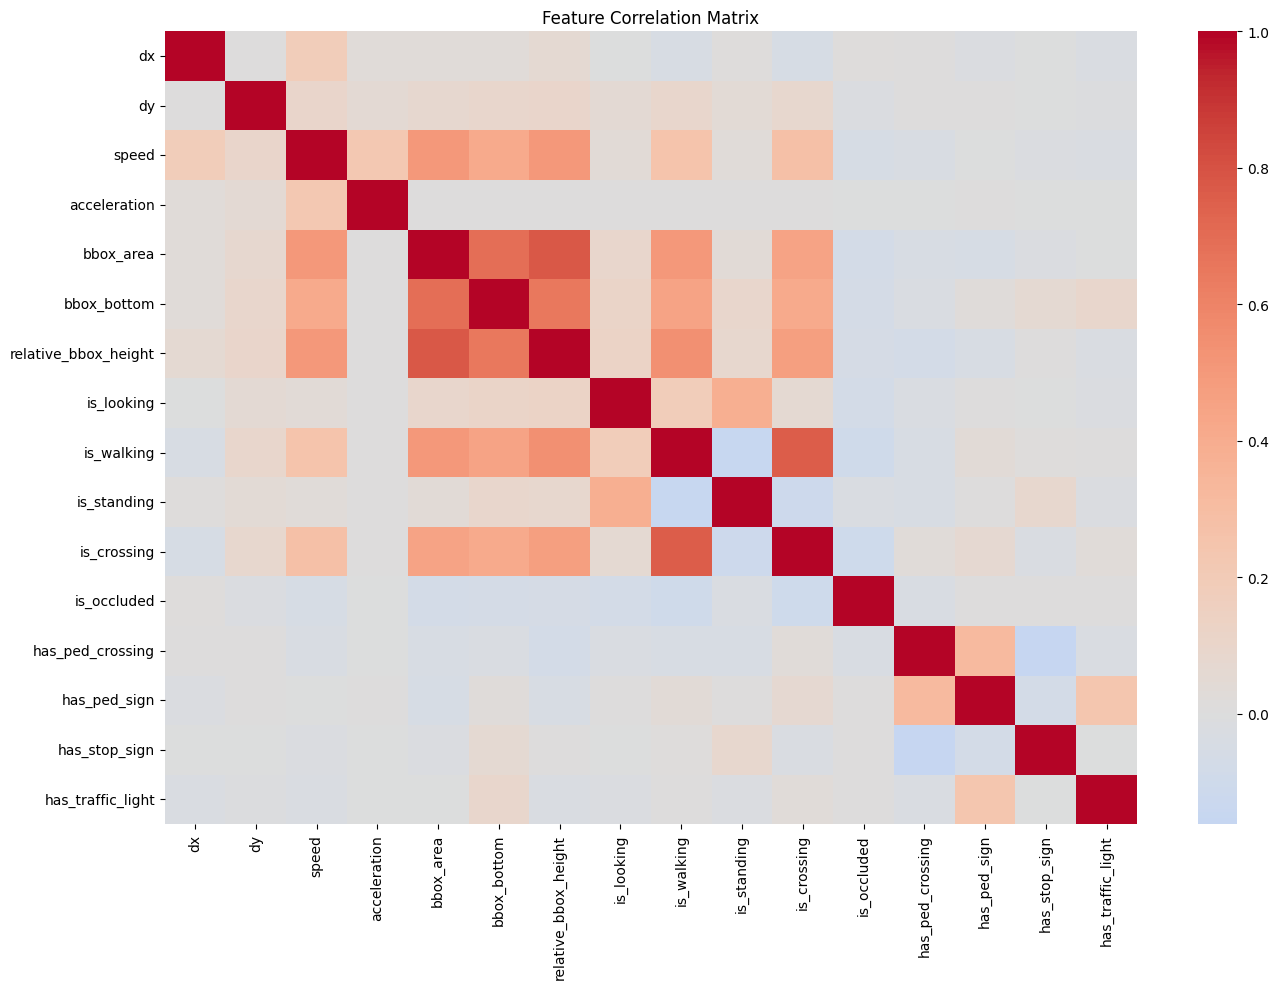

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_features = [
    "dx",
    "dy",
    "speed",
    "acceleration",
    "bbox_area",
    "bbox_bottom",
    "relative_bbox_height",
    "is_looking",
    "is_walking",
    "is_standing",
    "is_crossing",
    "is_occluded",
    "has_ped_crossing",
    "has_ped_sign",
    "has_stop_sign",
    "has_traffic_light"
]

corr_matrix = df[correlation_features].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    annot=False,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

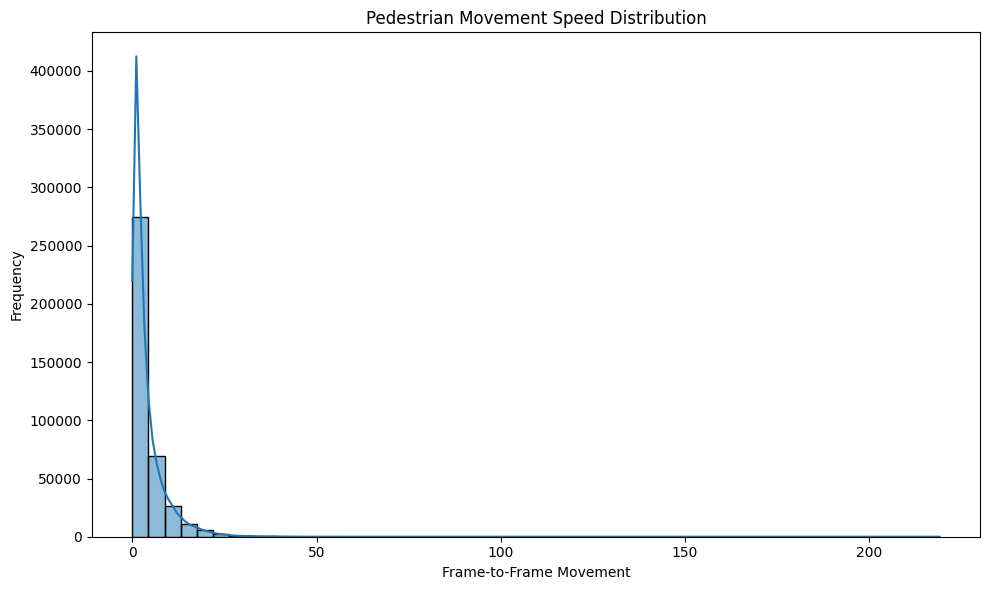

In [107]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["speed"],
    bins=50,
    kde=True
)

plt.title("Pedestrian Movement Speed Distribution")
plt.xlabel("Frame-to-Frame Movement")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

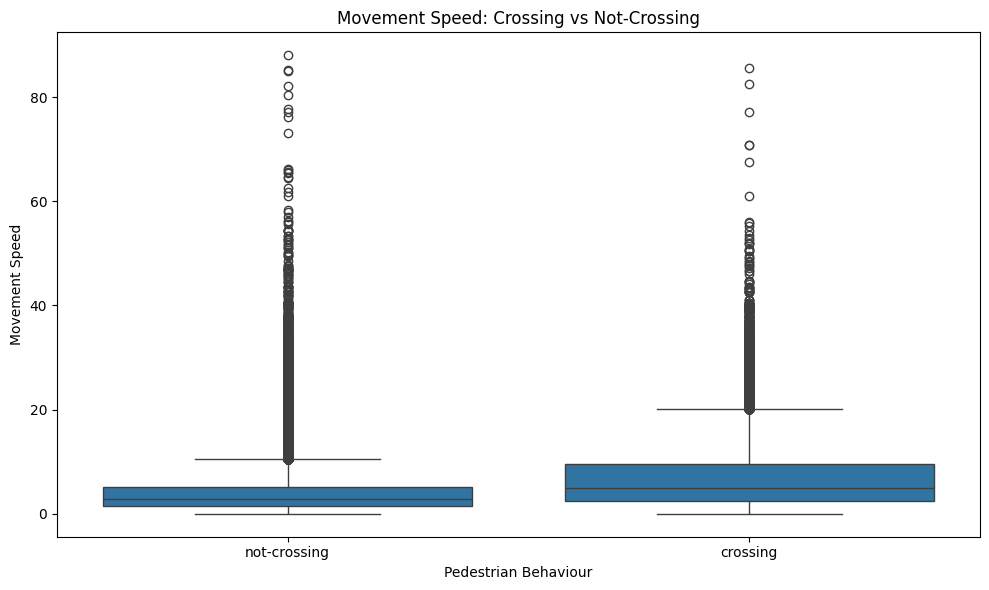

In [108]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df[df["cross"].isin(["crossing", "not-crossing"])],
    x="cross",
    y="speed"
)

plt.title("Movement Speed: Crossing vs Not-Crossing")
plt.xlabel("Pedestrian Behaviour")
plt.ylabel("Movement Speed")

plt.tight_layout()
plt.show()

In [109]:
import numpy as np
import pandas as pd

RISK_HORIZON = 15

df = df.sort_values(
    ["video_id", "track_index", "frame"]
).reset_index(drop=True)

df["future_cross"] = (
    df.groupby(["video_id", "track_index"])["is_crossing"]
      .transform(lambda x: x.shift(-RISK_HORIZON))
)

df["risk_label"] = (
    df["future_cross"]
    .fillna(0)
    .astype(int)
)

print("=" * 70)
print("PROACTIVE RISK LABEL")
print("=" * 70)

print("Risk horizon:", RISK_HORIZON, "frames")

print("\nRisk label distribution:")
print(df["risk_label"].value_counts())

print("\nRisk percentages:")
print(
    df["risk_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

PROACTIVE RISK LABEL
Risk horizon: 15 frames

Risk label distribution:
risk_label
0    319358
1     71680
Name: count, dtype: int64

Risk percentages:
risk_label
0    81.67
1    18.33
Name: proportion, dtype: float64


In [110]:
df["future_frame"] = (
    df.groupby(["video_id", "track_index"])["frame"]
      .transform(lambda x: x.shift(-RISK_HORIZON))
)

model_df = df[df["future_frame"].notna()].copy()

model_df = model_df.reset_index(drop=True)

print("=" * 70)
print("MODEL DATASET")
print("=" * 70)

print("Original records:", len(df))
print("Model records:", len(model_df))
print("Removed records:", len(df) - len(model_df))

print("\nRisk distribution:")
print(model_df["risk_label"].value_counts())

MODEL DATASET
Original records: 391038
Model records: 350124
Removed records: 40914

Risk distribution:
risk_label
0    278444
1     71680
Name: count, dtype: int64


In [111]:
print("=" * 70)
print("RISK LABEL VALIDATION")
print("=" * 70)

sample_cols = [
    "video_id",
    "track_index",
    "frame",
    "cross",
    "future_frame",
    "future_cross",
    "risk_label"
]

display(
    model_df[sample_cols].head(20)
)

print("\nRisk = 1 records:")
display(
    model_df[
        model_df["risk_label"] == 1
    ][sample_cols].head(10)
)

RISK LABEL VALIDATION


,video_id,track_index,frame,cross,future_frame,future_cross,risk_label
0,video_0001,0,0,not-crossing,15.0,0.0,0
1,video_0001,0,1,not-crossing,16.0,0.0,0
2,video_0001,0,2,not-crossing,17.0,0.0,0
3,video_0001,0,3,not-crossing,18.0,0.0,0
4,video_0001,0,4,not-crossing,19.0,0.0,0
5,video_0001,0,5,not-crossing,20.0,0.0,0
6,video_0001,0,6,not-crossing,21.0,0.0,0
7,video_0001,0,7,not-crossing,22.0,0.0,0
8,video_0001,0,8,not-crossing,23.0,0.0,0
9,video_0001,0,9,not-crossing,24.0,0.0,0



Risk = 1 records:


,video_id,track_index,frame,cross,future_frame,future_cross,risk_label
1038,video_0002,0,39,not-crossing,54.0,1.0,1
1039,video_0002,0,40,not-crossing,55.0,1.0,1
1040,video_0002,0,41,not-crossing,56.0,1.0,1
1041,video_0002,0,42,not-crossing,57.0,1.0,1
1042,video_0002,0,43,not-crossing,58.0,1.0,1
1043,video_0002,0,44,not-crossing,59.0,1.0,1
1044,video_0002,0,45,not-crossing,60.0,1.0,1
1045,video_0002,0,46,not-crossing,61.0,1.0,1
1046,video_0002,0,47,not-crossing,62.0,1.0,1
1047,video_0002,0,48,not-crossing,63.0,1.0,1


In [112]:
feature_columns = [
    "dx",
    "dy",
    "speed",
    "acceleration",
    "bbox_area",
    "bbox_bottom",
    "relative_bbox_height",
    "is_looking",
    "is_walking",
    "is_standing",
    "is_occluded",
    "has_ped_crossing",
    "has_ped_sign",
    "has_stop_sign",
    "has_traffic_light"
]

target_column = "risk_label"

X = model_df[feature_columns].copy()
y = model_df[target_column].copy()

print("=" * 70)
print("MODEL FEATURES")
print("=" * 70)

print("Number of features:", len(feature_columns))
print("\nFeatures:")
for i, feature in enumerate(feature_columns, 1):
    print(i, feature)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

MODEL FEATURES
Number of features: 15

Features:
1 dx
2 dy
3 speed
4 acceleration
5 bbox_area
6 bbox_bottom
7 relative_bbox_height
8 is_looking
9 is_walking
10 is_standing
11 is_occluded
12 has_ped_crossing
13 has_ped_sign
14 has_stop_sign
15 has_traffic_light

X shape: (350124, 15)
y shape: (350124,)


In [113]:
print("=" * 70)
print("MODEL FEATURE VALIDATION")
print("=" * 70)

print("Missing values:")
print(X.isna().sum())

print("\nInfinite values:")
print(np.isinf(X.select_dtypes(include=np.number)).sum())

print("\nTarget missing values:")
print(y.isna().sum())

MODEL FEATURE VALIDATION
Missing values:
dx                      0
dy                      0
speed                   0
acceleration            0
bbox_area               0
bbox_bottom             0
relative_bbox_height    0
is_looking              0
is_walking              0
is_standing             0
is_occluded             0
has_ped_crossing        0
has_ped_sign            0
has_stop_sign           0
has_traffic_light       0
dtype: int64

Infinite values:
dx                      0
dy                      0
speed                   0
acceleration            0
bbox_area               0
bbox_bottom             0
relative_bbox_height    0
is_looking              0
is_walking              0
is_standing             0
is_occluded             0
has_ped_crossing        0
has_ped_sign            0
has_stop_sign           0
has_traffic_light       0
dtype: int64

Target missing values:
0


In [114]:
from sklearn.model_selection import train_test_split

video_ids = model_df["video_id"].unique()

train_videos, temp_videos = train_test_split(
    video_ids,
    test_size=0.30,
    random_state=42
)

val_videos, test_videos = train_test_split(
    temp_videos,
    test_size=0.50,
    random_state=42
)

train_df = model_df[
    model_df["video_id"].isin(train_videos)
].copy()

val_df = model_df[
    model_df["video_id"].isin(val_videos)
].copy()

test_df = model_df[
    model_df["video_id"].isin(test_videos)
].copy()

print("=" * 70)
print("VIDEO-LEVEL DATA SPLIT")
print("=" * 70)

print("Training videos:", len(train_videos))
print("Validation videos:", len(val_videos))
print("Testing videos:", len(test_videos))

print("\nTraining records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nRisk distribution — TRAIN:")
print(train_df["risk_label"].value_counts())

print("\nRisk distribution — VALIDATION:")
print(val_df["risk_label"].value_counts())

print("\nRisk distribution — TEST:")
print(test_df["risk_label"].value_counts())

VIDEO-LEVEL DATA SPLIT
Training videos: 235
Validation videos: 51
Testing videos: 51

Training records: 238297
Validation records: 52502
Testing records: 59325

Risk distribution — TRAIN:
risk_label
0    188281
1     50016
Name: count, dtype: int64

Risk distribution — VALIDATION:
risk_label
0    43030
1     9472
Name: count, dtype: int64

Risk distribution — TEST:
risk_label
0    47133
1    12192
Name: count, dtype: int64


In [115]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(
    train_df[feature_columns]
)

X_val = scaler.transform(
    val_df[feature_columns]
)

X_test = scaler.transform(
    test_df[feature_columns]
)

y_train = train_df[target_column].values
y_val = val_df[target_column].values
y_test = test_df[target_column].values

print("=" * 70)
print("FEATURE SCALING")
print("=" * 70)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

print("\nScaled feature means:")
print(np.round(X_train.mean(axis=0), 4))

print("\nScaled feature standard deviations:")
print(np.round(X_train.std(axis=0), 4))

FEATURE SCALING
X_train shape: (238297, 15)
X_val shape: (52502, 15)
X_test shape: (59325, 15)

Scaled feature means:
[-0. -0. -0.  0.  0.  0.  0.  0.  0. -0. -0. -0.  0. -0.  0.]

Scaled feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [116]:
train_scaled = train_df[
    ["video_id", "track_index", "frame"]
].copy()

val_scaled = val_df[
    ["video_id", "track_index", "frame"]
].copy()

test_scaled = test_df[
    ["video_id", "track_index", "frame"]
].copy()

for i, feature in enumerate(feature_columns):
    train_scaled[feature] = X_train[:, i]
    val_scaled[feature] = X_val[:, i]
    test_scaled[feature] = X_test[:, i]

train_scaled["risk_label"] = y_train
val_scaled["risk_label"] = y_val
test_scaled["risk_label"] = y_test

print("=" * 70)
print("SCALED DATAFRAMES")
print("=" * 70)

print("Train:", train_scaled.shape)
print("Validation:", val_scaled.shape)
print("Test:", test_scaled.shape)

display(train_scaled.head())

SCALED DATAFRAMES
Train: (238297, 19)
Validation: (52502, 19)
Test: (59325, 19)


,video_id,track_index,frame,dx,dy,speed,acceleration,bbox_area,bbox_bottom,relative_bbox_height,is_looking,is_walking,is_standing,is_occluded,has_ped_crossing,has_ped_sign,has_stop_sign,has_traffic_light,risk_label
0,video_0001,0,0,-0.011376,-0.141431,-0.927249,-0.034109,-0.140326,0.887972,-0.487003,-0.265006,-0.662991,4.075683,-0.589348,-1.341164,-0.792683,-0.175496,-0.284262,0
1,video_0001,0,1,-0.322335,-0.141431,-0.516114,0.955923,-0.134245,0.887972,-0.487003,-0.265006,-0.662991,4.075683,-0.589348,-1.341164,-0.792683,-0.175496,-0.284262,0
2,video_0001,0,2,-0.322335,0.273120,-0.493875,0.019444,-0.124556,0.897694,-0.478998,-0.265006,-0.662991,4.075683,-0.589348,-1.341164,-0.792683,-0.175496,-0.284262,0
3,video_0001,0,3,-0.322335,-0.141431,-0.516114,-0.087662,-0.118423,0.897694,-0.478998,-0.265006,-0.662991,4.075683,-0.589348,-1.341164,-0.792683,-0.175496,-0.284262,0
4,video_0001,0,4,-0.115029,1.102224,-0.493875,0.019444,-0.108579,0.917139,-0.470993,-0.265006,-0.662991,4.075683,-0.589348,-1.341164,-0.792683,-0.175496,-0.284262,0


In [117]:
SEQUENCE_LENGTH = 15

print("=" * 70)
print("TEMPORAL SEQUENCE CONFIGURATION")
print("=" * 70)

print("Sequence length:", SEQUENCE_LENGTH)
print("Prediction horizon:", RISK_HORIZON)
print("Total temporal context:", SEQUENCE_LENGTH, "frames")

TEMPORAL SEQUENCE CONFIGURATION
Sequence length: 15
Prediction horizon: 15
Total temporal context: 15 frames


In [118]:
def create_sequences(data, feature_columns, sequence_length):
    X_sequences = []
    y_sequences = []
    metadata = []

    data = data.sort_values(
        ["video_id", "track_index", "frame"]
    ).reset_index(drop=True)

    for (video_id, track_index), group in data.groupby(
        ["video_id", "track_index"]
    ):
        group = group.sort_values("frame")

        features = group[feature_columns].values
        labels = group["risk_label"].values
        frames = group["frame"].values

        if len(group) < sequence_length:
            continue

        for i in range(sequence_length - 1, len(group)):
            sequence = features[
                i - sequence_length + 1:i + 1
            ]

            X_sequences.append(sequence)
            y_sequences.append(labels[i])

            metadata.append([
                video_id,
                track_index,
                frames[i]
            ])

    return (
        np.array(X_sequences, dtype=np.float32),
        np.array(y_sequences, dtype=np.int32),
        pd.DataFrame(
            metadata,
            columns=["video_id", "track_index", "frame"]
        )
    )

In [119]:
X_train_seq, y_train_seq, train_meta = create_sequences(
    train_scaled,
    feature_columns,
    SEQUENCE_LENGTH
)

print("=" * 70)
print("TRAINING TEMPORAL SEQUENCES")
print("=" * 70)

print("X_train_seq shape:", X_train_seq.shape)
print("y_train_seq shape:", y_train_seq.shape)

print("\nExpected format:")
print("(samples, time_steps, features)")

print("\nRisk distribution:")
print(
    pd.Series(y_train_seq)
    .value_counts()
)

TRAINING TEMPORAL SEQUENCES
X_train_seq shape: (214899, 15, 15)
y_train_seq shape: (214899,)

Expected format:
(samples, time_steps, features)

Risk distribution:
0    166981
1     47918
Name: count, dtype: int64


In [120]:
X_val_seq, y_val_seq, val_meta = create_sequences(
    val_scaled,
    feature_columns,
    SEQUENCE_LENGTH
)

print("=" * 70)
print("VALIDATION TEMPORAL SEQUENCES")
print("=" * 70)

print("X_val_seq shape:", X_val_seq.shape)
print("y_val_seq shape:", y_val_seq.shape)

print("\nRisk distribution:")
print(
    pd.Series(y_val_seq)
    .value_counts()
)

VALIDATION TEMPORAL SEQUENCES
X_val_seq shape: (46748, 15, 15)
y_val_seq shape: (46748,)

Risk distribution:
0    37703
1     9045
Name: count, dtype: int64


In [121]:
X_test_seq, y_test_seq, test_meta = create_sequences(
    test_scaled,
    feature_columns,
    SEQUENCE_LENGTH
)

print("=" * 70)
print("TEST TEMPORAL SEQUENCES")
print("=" * 70)

print("X_test_seq shape:", X_test_seq.shape)
print("y_test_seq shape:", y_test_seq.shape)

print("\nRisk distribution:")
print(
    pd.Series(y_test_seq)
    .value_counts()
)

TEST TEMPORAL SEQUENCES
X_test_seq shape: (52736, 15, 15)
y_test_seq shape: (52736,)

Risk distribution:
0    41366
1    11370
Name: count, dtype: int64


In [122]:
print("=" * 70)
print("SEQUENCE INTEGRITY CHECK")
print("=" * 70)

print("Training sequences:", len(X_train_seq))
print("Validation sequences:", len(X_val_seq))
print("Testing sequences:", len(X_test_seq))

print("\nSequence shape:")
print(X_train_seq.shape)

print("\nFirst training sequence:")
display(
    train_meta.head(1)
)

print("\nFirst sequence feature matrix shape:")
print(X_train_seq[0].shape)

print("\nFirst sequence target:")
print(y_train_seq[0])

SEQUENCE INTEGRITY CHECK
Training sequences: 214899
Validation sequences: 46748
Testing sequences: 52736

Sequence shape:
(214899, 15, 15)

First training sequence:


,video_id,track_index,frame
0,video_0001,0,14



First sequence feature matrix shape:
(15, 15)

First sequence target:
0


In [123]:
from sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler()

X_train_2d = X_train.reshape(-1, X_train.shape[-1])
X_val_2d = X_val.reshape(-1, X_val.shape[-1])
X_test_2d = X_test.reshape(-1, X_test.shape[-1])

scaler.fit(X_train_2d)

X_train_scaled = scaler.transform(X_train_2d).reshape(X_train.shape)
X_val_scaled = scaler.transform(X_val_2d).reshape(X_val.shape)
X_test_scaled = scaler.transform(X_test_2d).reshape(X_test.shape)

print("=" * 70)
print("FEATURE SCALING")
print("=" * 70)

print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nTraining mean:", np.mean(X_train_scaled))
print("Training std:", np.std(X_train_scaled))

FEATURE SCALING
Training shape: (238297, 15)
Validation shape: (52502, 15)
Testing shape: (59325, 15)

Training mean: -3.512902309961236e-17
Training std: 1.0000000000000004


In [124]:
from sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler()

X_train_seq_2d = X_train_seq.reshape(-1, X_train_seq.shape[-1])
X_val_seq_2d = X_val_seq.reshape(-1, X_val_seq.shape[-1])
X_test_seq_2d = X_test_seq.reshape(-1, X_test_seq.shape[-1])

scaler.fit(X_train_seq_2d)

X_train_scaled = scaler.transform(X_train_seq_2d).reshape(X_train_seq.shape)
X_val_scaled = scaler.transform(X_val_seq_2d).reshape(X_val_seq.shape)
X_test_scaled = scaler.transform(X_test_seq_2d).reshape(X_test_seq.shape)

print("=" * 70)
print("SEQUENCE FEATURE SCALING")
print("=" * 70)

print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nTraining mean:", np.mean(X_train_scaled))
print("Training std:", np.std(X_train_scaled))

SEQUENCE FEATURE SCALING
Training shape: (214899, 15, 15)
Validation shape: (46748, 15, 15)
Testing shape: (52736, 15, 15)

Training mean: -6.2964394e-09
Training std: 1.0000001


In [127]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [130]:
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(15, 15)),
    Dropout(0.3),
    
    LSTM(32),
    Dropout(0.3),
    
    Dense(16, activation="relu"),
    Dropout(0.2),
    
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 15, 64)         │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,441 (130.63 KB)

 Trainable params: 33,441 (130.63 KB)

 Non-trainable params: 0 (0.00 B)

In [129]:
import numpy as np

print("=" * 70)
print("SEQUENCE TARGET DISTRIBUTION")
print("=" * 70)

print("Training:")
print(np.unique(y_train_seq, return_counts=True))

print("\nValidation:")
print(np.unique(y_val_seq, return_counts=True))

print("\nTesting:")
print(np.unique(y_test_seq, return_counts=True))

SEQUENCE TARGET DISTRIBUTION
Training:
(array([0, 1], dtype=int32), array([166981,  47918]))

Validation:
(array([0, 1], dtype=int32), array([37703,  9045]))

Testing:
(array([0, 1], dtype=int32), array([41366, 11370]))


In [131]:
print("=" * 70)
print("SEQUENCE TARGET DISTRIBUTION")
print("=" * 70)

print("TRAIN:")
print(pd.Series(y_train_seq).value_counts())

print("\nVALIDATION:")
print(pd.Series(y_val_seq).value_counts())

print("\nTEST:")
print(pd.Series(y_test_seq).value_counts())

print("\nTRAIN PERCENTAGES:")
print(
    pd.Series(y_train_seq)
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

SEQUENCE TARGET DISTRIBUTION
TRAIN:
0    166981
1     47918
Name: count, dtype: int64

VALIDATION:
0    37703
1     9045
Name: count, dtype: int64

TEST:
0    41366
1    11370
Name: count, dtype: int64

TRAIN PERCENTAGES:
0    77.7
1    22.3
Name: proportion, dtype: float64


In [132]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train_seq)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_seq
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, class_weights_array)
}

print("=" * 70)
print("CLASS WEIGHTS")
print("=" * 70)

print(class_weights)

CLASS WEIGHTS
{0: 0.6434833903258455, 1: 2.242361951667432}


In [133]:
early_stopping = EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_auc",
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [135]:
history = model.fit(
    X_train_scaled,
    y_train_seq,
    validation_data=(
        X_val_scaled,
        y_val_seq
    ),
    epochs=30,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

Epoch 1/30
840/840 ━━━━━━━━━━━━━━━━━━━━ 35s 41ms/step - accuracy: 0.9430 - auc: 0.9882 - loss: 0.1155 - precision: 0.8035 - recall: 0.9851 - val_accuracy: 0.9092 - val_auc: 0.9651 - val_loss: 0.2394 - val_precision: 0.7195 - val_recall: 0.8700 - learning_rate: 1.2500e-04
Epoch 2/30
840/840 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9462 - auc: 0.9890 - loss: 0.1105 - precision: 0.8147 - recall: 0.9834
Epoch 2: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
840/840 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.9468 - auc: 0.9892 - loss: 0.1094 - precision: 0.8155 - recall: 0.9843 - val_accuracy: 0.9113 - val_auc: 0.9611 - val_loss: 0.2499 - val_precision: 0.7219 - val_recall: 0.8811 - learning_rate: 1.2500e-04
Epoch 3/30
840/840 ━━━━━━━━━━━━━━━━━━━━ 36s 43ms/step - accuracy: 0.9491 - auc: 0.9898 - loss: 0.1058 - precision: 0.8219 - recall: 0.9850 - val_accuracy: 0.9088 - val_auc: 0.9561 - val_loss: 0.2684 - val_precision: 0.7204 - val_recall: 0.8638 - learning

In [136]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()

print("=" * 70)
print("REGULARIZED LSTM MODEL")
print("=" * 70)

model = Sequential([
    Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])),

    LSTM(
        32,
        return_sequences=True,
        kernel_regularizer=l2(0.001),
        recurrent_regularizer=l2(0.001)
    ),
    Dropout(0.35),

    LSTM(
        16,
        return_sequences=False,
        kernel_regularizer=l2(0.001),
        recurrent_regularizer=l2(0.001)
    ),
    Dropout(0.35),

    Dense(
        16,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),
    Dropout(0.30),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=Adam(
        learning_rate=0.0005,
        clipnorm=1.0
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

early_stopping = EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

print("\n" + "=" * 70)
print("TRAINING REGULARIZED LSTM")
print("=" * 70)

history = model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=30,
    batch_size=256,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)


REGULARIZED LSTM MODEL


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 15, 32)         │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,569 (37.38 KB)

 Trainable params: 9,569 (37.38 KB)

 Non-trainable params: 0 (0.00 B)


TRAINING REGULARIZED LSTM
Epoch 1/30
840/840 ━━━━━━━━━━━━━━━━━━━━ 27s 26ms/step - accuracy: 0.8994 - auc: 0.9542 - loss: 0.2991 - precision: 0.7258 - recall: 0.8819 - val_accuracy: 0.9294 - val_auc: 0.9781 - val_loss: 0.1879 - val_precision: 0.7741 - val_recall: 0.8965 - learning_rate: 5.0000e-04
Epoch 2/30
840/840 ━━━━━━━━━━━━━━━━━━━━ 23s 28ms/step - accuracy: 0.9247 - auc: 0.9727 - loss: 0.2026 - precision: 0.7915 - recall: 0.8993 - val_accuracy: 0.9209 - val_auc: 0.9749 - val_loss: 0.1884 - val_precision: 0.8017 - val_recall: 0.7853 - learning_rate: 5.0000e-04
Epoch 3/30
838/840 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9284 - auc: 0.9754 - loss: 0.1881 - precision: 0.8014 - recall: 0.9003
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
840/840 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - accuracy: 0.9295 - auc: 0.9760 - loss: 0.1855 - precision: 0.8060 - recall: 0.9006 - val_accuracy: 0.9213 - val_auc: 0.9726 - val_loss: 0.1879 - val_precision: 0.7870 - v

TRAINING HISTORY
Best epoch: 1
Best validation AUC: 0.9781138300895691
Best validation accuracy: 0.9293659329414368
Lowest validation loss: 0.1743924766778946


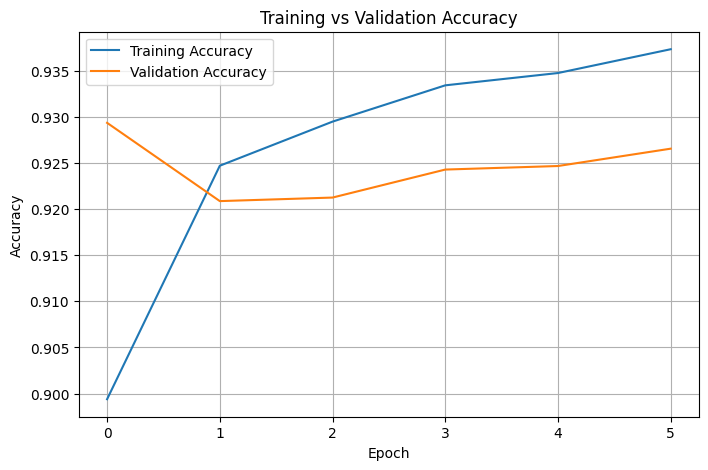

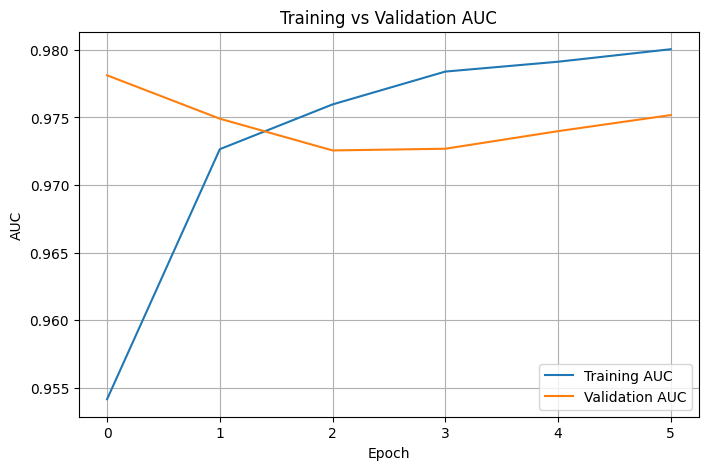

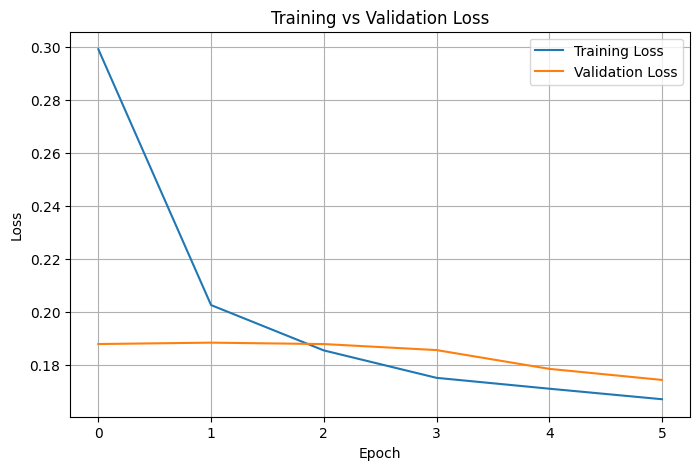

In [137]:
import matplotlib.pyplot as plt

print("=" * 70)
print("TRAINING HISTORY")
print("=" * 70)

best_epoch = history.history["val_auc"].index(
    max(history.history["val_auc"])
) + 1

print("Best epoch:", best_epoch)
print("Best validation AUC:", max(history.history["val_auc"]))
print("Best validation accuracy:", max(history.history["val_accuracy"]))
print("Lowest validation loss:", min(history.history["val_loss"]))

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["auc"], label="Training AUC")
plt.plot(history.history["val_auc"], label="Validation AUC")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.title("Training vs Validation AUC")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [138]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("FINAL TEST SET EVALUATION")
print("=" * 70)

test_probabilities = model.predict(
    X_test_seq,
    batch_size=256,
    verbose=1
).ravel()

test_predictions = (test_probabilities >= 0.5).astype(int)

test_accuracy = accuracy_score(y_test_seq, test_predictions)
test_precision = precision_score(y_test_seq, test_predictions, zero_division=0)
test_recall = recall_score(y_test_seq, test_predictions, zero_division=0)
test_f1 = f1_score(y_test_seq, test_predictions, zero_division=0)
test_auc = roc_auc_score(y_test_seq, test_probabilities)

print("\n" + "=" * 70)
print("TEST METRICS")
print("=" * 70)

print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"ROC-AUC   : {test_auc:.4f}")

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

cm = confusion_matrix(y_test_seq, test_predictions)

print(cm)

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test_seq,
        test_predictions,
        target_names=["Low Risk", "High Risk"],
        digits=4,
        zero_division=0
    )
)

FINAL TEST SET EVALUATION
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step

TEST METRICS
Accuracy  : 0.9025
Precision : 0.7249
Recall    : 0.8825
F1 Score  : 0.7960
ROC-AUC   : 0.9602

CONFUSION MATRIX
[[37559  3807]
 [ 1336 10034]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Low Risk     0.9657    0.9080    0.9359     41366
   High Risk     0.7249    0.8825    0.7960     11370

    accuracy                         0.9025     52736
   macro avg     0.8453    0.8952    0.8660     52736
weighted avg     0.9138    0.9025    0.9058     52736



FINAL MODEL VISUALIZATION


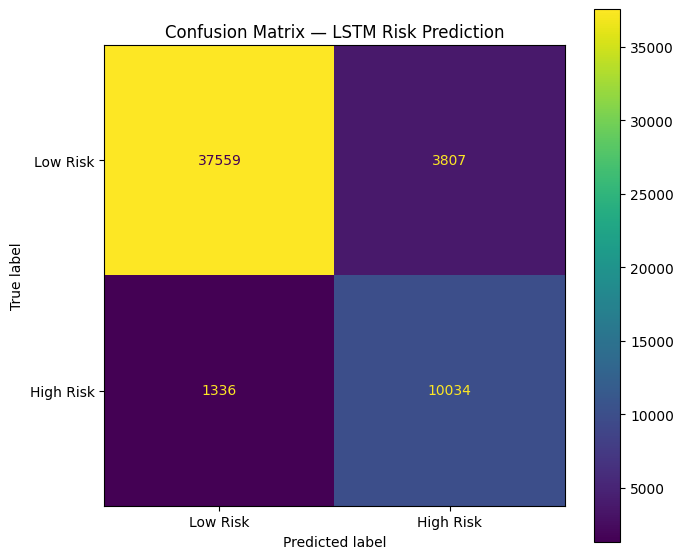

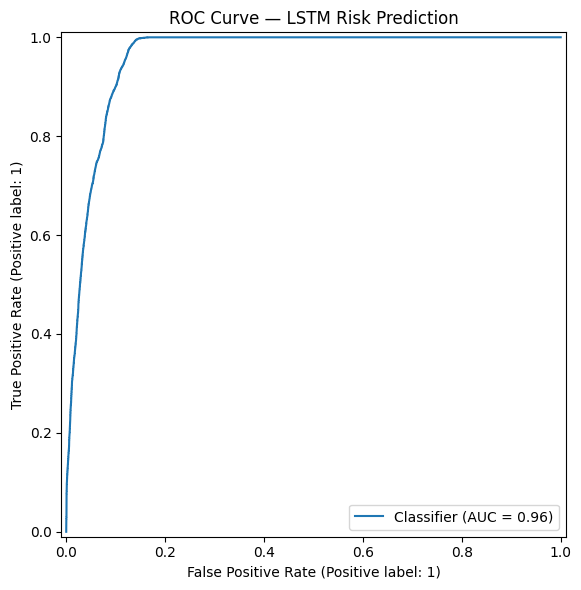


ROC-AUC: 0.9602


In [139]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

print("=" * 70)
print("FINAL MODEL VISUALIZATION")
print("=" * 70)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Risk", "High Risk"]
).plot(ax=ax, values_format="d")
ax.set_title("Confusion Matrix — LSTM Risk Prediction")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(
    y_test_seq,
    test_probabilities,
    ax=ax
)
ax.set_title("ROC Curve — LSTM Risk Prediction")
plt.tight_layout()
plt.show()

print("\nROC-AUC:", round(test_auc, 4))

RISK THRESHOLD ANALYSIS
 threshold  precision   recall  f1_score
      0.20   0.676262 0.979420  0.800086
      0.25   0.680774 0.971944  0.800710
      0.30   0.685229 0.958839  0.799267
      0.35   0.691570 0.945207  0.798737
      0.40   0.703635 0.927968  0.800379
      0.45   0.712258 0.900440  0.795370
      0.50   0.724948 0.882498  0.796002
      0.55   0.737034 0.851187  0.790009
      0.60   0.742806 0.810554  0.775203
      0.65   0.766691 0.749428  0.757961
      0.70   0.795027 0.680563  0.733355
      0.75   0.817946 0.582850  0.680670
      0.80   0.836258 0.456816  0.590865

BEST F1 THRESHOLD
Threshold : 0.25
Precision : 0.6808
Recall    : 0.9719
F1 Score  : 0.8007


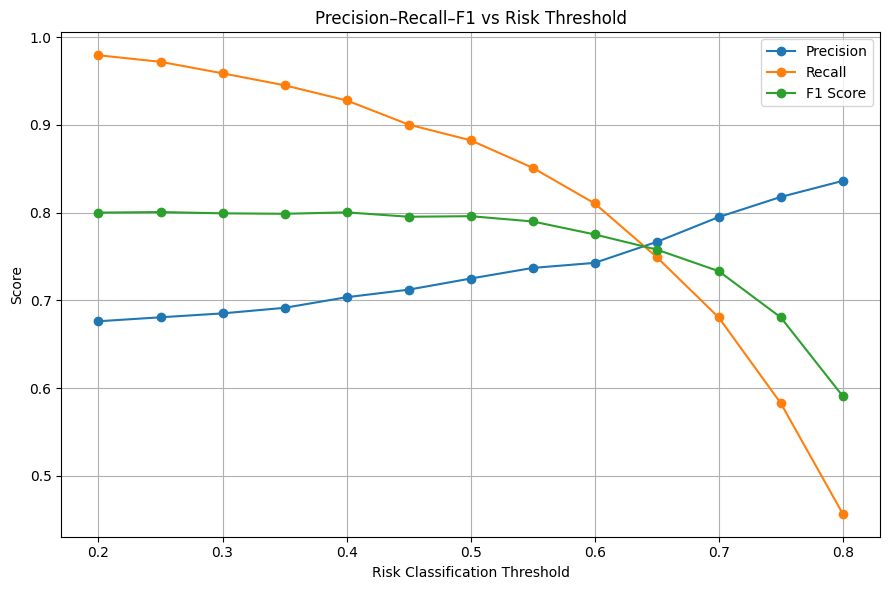

In [140]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

print("=" * 70)
print("RISK THRESHOLD ANALYSIS")
print("=" * 70)

thresholds = np.arange(0.20, 0.81, 0.05)

threshold_results = []

for threshold in thresholds:
    predictions = (test_probabilities >= threshold).astype(int)

    precision = precision_score(
        y_test_seq,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test_seq,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test_seq,
        predictions,
        zero_division=0
    )

    threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.to_string(index=False))

best_f1_row = threshold_df.loc[
    threshold_df["f1_score"].idxmax()
]

print("\n" + "=" * 70)
print("BEST F1 THRESHOLD")
print("=" * 70)

print(
    f"Threshold : {best_f1_row['threshold']:.2f}\n"
    f"Precision : {best_f1_row['precision']:.4f}\n"
    f"Recall    : {best_f1_row['recall']:.4f}\n"
    f"F1 Score  : {best_f1_row['f1_score']:.4f}"
)

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1_score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Risk Classification Threshold")
plt.ylabel("Score")
plt.title("Precision–Recall–F1 vs Risk Threshold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [141]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

print("=" * 70)
print("VALIDATION THRESHOLD OPTIMIZATION")
print("=" * 70)

val_probabilities = model.predict(
    X_val_seq,
    batch_size=256,
    verbose=1
).ravel()

thresholds = np.arange(0.20, 0.81, 0.05)

validation_results = []

for threshold in thresholds:
    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_val_seq,
        val_predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val_seq,
        val_predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val_seq,
        val_predictions,
        zero_division=0
    )

    validation_results.append({
        "threshold": round(threshold, 2),
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })

validation_threshold_df = pd.DataFrame(
    validation_results
)

print(
    validation_threshold_df.to_string(index=False)
)

best_validation_row = validation_threshold_df.loc[
    validation_threshold_df["f1_score"].idxmax()
]

print("\n" + "=" * 70)
print("SELECTED THRESHOLD FROM VALIDATION SET")
print("=" * 70)

print(
    f"Threshold : {best_validation_row['threshold']:.2f}"
)

print(
    f"Precision : {best_validation_row['precision']:.4f}"
)

print(
    f"Recall    : {best_validation_row['recall']:.4f}"
)

print(
    f"F1 Score  : {best_validation_row['f1_score']:.4f}"
)

optimal_threshold = float(
    best_validation_row["threshold"]
)

print("\nFinal threshold selected:", optimal_threshold)

VALIDATION THRESHOLD OPTIMIZATION
183/183 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step
 threshold  precision   recall  f1_score
      0.20   0.696620 0.975345  0.812750
      0.25   0.704279 0.968159  0.815401
      0.30   0.712187 0.959425  0.817522
      0.35   0.725179 0.953676  0.823878
      0.40   0.738784 0.943062  0.828517
      0.45   0.755392 0.921504  0.830221
      0.50   0.774129 0.896517  0.830840
      0.55   0.800323 0.876064  0.836483
      0.60   0.828179 0.840907  0.834494
      0.65   0.853204 0.759536  0.803650
      0.70   0.867281 0.708015  0.779597
      0.75   0.888332 0.627087  0.735191
      0.80   0.911496 0.506689  0.651318

SELECTED THRESHOLD FROM VALIDATION SET
Threshold : 0.55
Precision : 0.8003
Recall    : 0.8761
F1 Score  : 0.8365

Final threshold selected: 0.55


In [142]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("FINAL TEST EVALUATION — THRESHOLD 0.55")
print("=" * 70)

final_threshold = 0.55

final_test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

final_accuracy = accuracy_score(
    y_test_seq,
    final_test_predictions
)

final_precision = precision_score(
    y_test_seq,
    final_test_predictions,
    zero_division=0
)

final_recall = recall_score(
    y_test_seq,
    final_test_predictions,
    zero_division=0
)

final_f1 = f1_score(
    y_test_seq,
    final_test_predictions,
    zero_division=0
)

final_auc = roc_auc_score(
    y_test_seq,
    test_probabilities
)

final_cm = confusion_matrix(
    y_test_seq,
    final_test_predictions
)

print("\n" + "=" * 70)
print("FINAL TEST METRICS")
print("=" * 70)

print(f"Threshold : {final_threshold:.2f}")
print(f"Accuracy  : {final_accuracy:.4f}")
print(f"Precision : {final_precision:.4f}")
print(f"Recall    : {final_recall:.4f}")
print(f"F1 Score  : {final_f1:.4f}")
print(f"ROC-AUC   : {final_auc:.4f}")

print("\n" + "=" * 70)
print("FINAL CONFUSION MATRIX")
print("=" * 70)

print(final_cm)

print("\n" + "=" * 70)
print("FINAL CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test_seq,
        final_test_predictions,
        target_names=["Low Risk", "High Risk"],
        digits=4,
        zero_division=0
    )
)

FINAL TEST EVALUATION — THRESHOLD 0.55

FINAL TEST METRICS
Threshold : 0.55
Accuracy  : 0.9024
Precision : 0.7370
Recall    : 0.8512
F1 Score  : 0.7900
ROC-AUC   : 0.9602

FINAL CONFUSION MATRIX
[[37913  3453]
 [ 1692  9678]]

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Low Risk     0.9573    0.9165    0.9365     41366
   High Risk     0.7370    0.8512    0.7900     11370

    accuracy                         0.9024     52736
   macro avg     0.8472    0.8839    0.8632     52736
weighted avg     0.9098    0.9024    0.9049     52736



In [143]:
import joblib
import json

MODEL_PATH = "jaad_lstm_risk_model.keras"
SCALER_PATH = "jaad_feature_scaler.pkl"
THRESHOLD_PATH = "jaad_risk_threshold.json"
FEATURES_PATH = "jaad_model_features.json"

model.save(MODEL_PATH)

joblib.dump(scaler, SCALER_PATH)

with open(THRESHOLD_PATH, "w") as f:
    json.dump({
        "risk_threshold": 0.55
    }, f, indent=4)

with open(FEATURES_PATH, "w") as f:
    json.dump(feature_columns, f, indent=4)

print("=" * 70)
print("FINAL MODEL ARTIFACTS SAVED")
print("=" * 70)
print(MODEL_PATH)
print(SCALER_PATH)
print(THRESHOLD_PATH)
print(FEATURES_PATH)

FINAL MODEL ARTIFACTS SAVED
jaad_lstm_risk_model.keras
jaad_feature_scaler.pkl
jaad_risk_threshold.json
jaad_model_features.json


In [144]:
import joblib
import json

MODEL_PATH = "jaad_lstm_risk_model.keras"
SCALER_PATH = "jaad_feature_scaler.pkl"
THRESHOLD_PATH = "jaad_risk_threshold.json"
FEATURES_PATH = "jaad_model_features.json"

model.save(MODEL_PATH)

joblib.dump(scaler, SCALER_PATH)

with open(THRESHOLD_PATH, "w") as f:
    json.dump({
        "risk_threshold": 0.55
    }, f, indent=4)

with open(FEATURES_PATH, "w") as f:
    json.dump(feature_columns, f, indent=4)

print("=" * 70)
print("FINAL MODEL ARTIFACTS SAVED")
print("=" * 70)
print(MODEL_PATH)
print(SCALER_PATH)
print(THRESHOLD_PATH)
print(FEATURES_PATH)

FINAL MODEL ARTIFACTS SAVED
jaad_lstm_risk_model.keras
jaad_feature_scaler.pkl
jaad_risk_threshold.json
jaad_model_features.json


In [145]:
import joblib

scaler_path = os.path.join(MODEL_DIR, "jaad_feature_scaler.pkl")

joblib.dump(scaler, scaler_path)

print("=" * 70)
print("SCALER SAVED")
print("=" * 70)
print(f"Path: {scaler_path}")

SCALER SAVED
Path: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\jaad_feature_scaler.pkl


In [146]:
import json

threshold_path = os.path.join(MODEL_DIR, "risk_threshold.json")

with open(threshold_path, "w") as f:
    json.dump({
        "threshold": 0.55,
        "risk_horizon_frames": 15,
        "sequence_length": 15
    }, f, indent=4)

print("=" * 70)
print("RISK CONFIGURATION SAVED")
print("=" * 70)
print(f"Path: {threshold_path}")

RISK CONFIGURATION SAVED
Path: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\risk_threshold.json


In [147]:
feature_config = {
    "features": [
        "dx",
        "dy",
        "speed",
        "acceleration",
        "bbox_area",
        "bbox_bottom",
        "relative_bbox_height",
        "is_looking",
        "is_walking",
        "is_standing",
        "is_occluded",
        "has_ped_crossing",
        "has_ped_sign",
        "has_stop_sign",
        "has_traffic_light"
    ],
    "sequence_length": 15,
    "risk_horizon": 15
}

feature_path = os.path.join(MODEL_DIR, "feature_config.json")

with open(feature_path, "w") as f:
    json.dump(feature_config, f, indent=4)

print("=" * 70)
print("FEATURE CONFIGURATION SAVED")
print("=" * 70)
print(f"Path: {feature_path}")

FEATURE CONFIGURATION SAVED
Path: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\feature_config.json


In [149]:
import pandas as pd

history_df = pd.DataFrame(history.history)

history_path = os.path.join(MODEL_DIR, "training_history.csv")

history_df.to_csv(history_path, index=False)

print("=" * 70)
print("TRAINING HISTORY SAVED")
print("=" * 70)
print(f"Path: {history_path}")

TRAINING HISTORY SAVED
Path: D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\training_history.csv


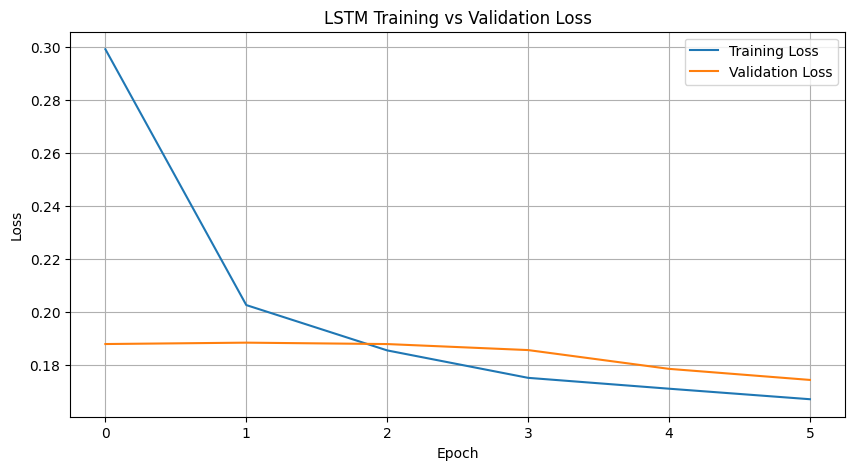

In [150]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

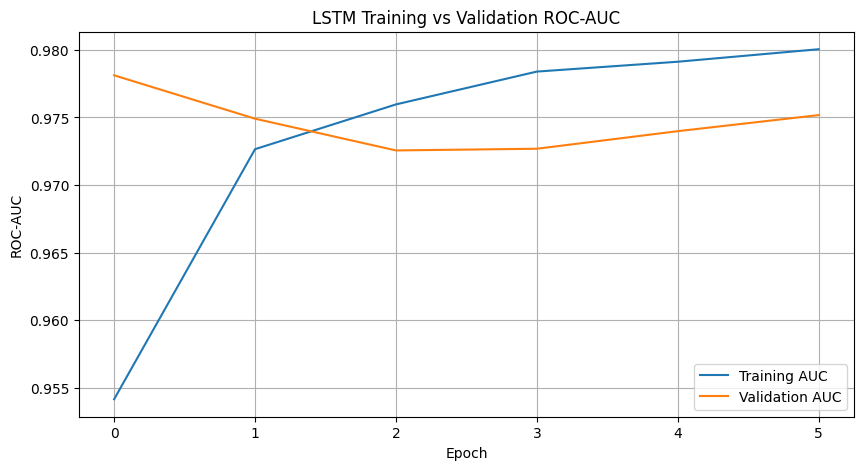

In [151]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["auc"], label="Training AUC")
plt.plot(history.history["val_auc"], label="Validation AUC")

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("LSTM Training vs Validation ROC-AUC")
plt.legend()
plt.grid(True)

plt.show()

In [152]:
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Test Score": [
        0.9024,
        0.7370,
        0.8512,
        0.7900,
        0.9602
    ]
})

print("=" * 70)
print("FINAL LSTM PERFORMANCE")
print("=" * 70)

display(final_results)

FINAL LSTM PERFORMANCE


,Metric,Test Score
0,Accuracy,0.9024
1,Precision,0.7370
2,Recall,0.8512
3,F1 Score,0.7900
4,ROC-AUC,0.9602


In [153]:
tn, fp, fn, tp = 37913, 3453, 1692, 9678

false_negative_rate = fn / (fn + tp)

print(f"False Negative Rate: {false_negative_rate:.4f}")
print(f"False Negative Rate: {false_negative_rate * 100:.2f}%")

False Negative Rate: 0.1488
False Negative Rate: 14.88%


In [154]:
import numpy as np
import pandas as pd

MODEL_FEATURES = [
    "dx",
    "dy",
    "speed",
    "acceleration",
    "bbox_area",
    "bbox_bottom",
    "relative_bbox_height",
    "is_looking",
    "is_walking",
    "is_standing",
    "is_occluded",
    "has_ped_crossing",
    "has_ped_sign",
    "has_stop_sign",
    "has_traffic_light"
]

X_train_ml = train_df[MODEL_FEATURES].copy()
X_val_ml = val_df[MODEL_FEATURES].copy()
X_test_ml = test_df[MODEL_FEATURES].copy()

y_train_ml = train_df["risk_label"].astype(int)
y_val_ml = val_df["risk_label"].astype(int)
y_test_ml = test_df["risk_label"].astype(int)

print("=" * 70)
print("BASELINE MODEL DATA")
print("=" * 70)

print("Training:", X_train_ml.shape)
print("Validation:", X_val_ml.shape)
print("Testing:", X_test_ml.shape)

print("\nTarget distribution:")
print(y_train_ml.value_counts())

BASELINE MODEL DATA
Training: (238297, 15)
Validation: (52502, 15)
Testing: (59325, 15)

Target distribution:
risk_label
0    188281
1     50016
Name: count, dtype: int64


In [155]:
from sklearn.preprocessing import StandardScaler

baseline_scaler = StandardScaler()

X_train_ml_scaled = baseline_scaler.fit_transform(X_train_ml)
X_val_ml_scaled = baseline_scaler.transform(X_val_ml)
X_test_ml_scaled = baseline_scaler.transform(X_test_ml)

print("=" * 70)
print("BASELINE FEATURE SCALING")
print("=" * 70)

print("Training mean:", X_train_ml_scaled.mean())
print("Training std:", X_train_ml_scaled.std())

BASELINE FEATURE SCALING
Training mean: 3.3204798656401365e-17
Training std: 1.0000000000000004


In [156]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

print("=" * 70)
print("TRAINING LOGISTIC REGRESSION")
print("=" * 70)

logistic_model.fit(X_train_ml_scaled, y_train_ml)

logistic_val_prob = logistic_model.predict_proba(X_val_ml_scaled)[:, 1]
logistic_test_prob = logistic_model.predict_proba(X_test_ml_scaled)[:, 1]

logistic_test_pred = (logistic_test_prob >= 0.5).astype(int)

print("Training complete.")

TRAINING LOGISTIC REGRESSION
Training complete.


In [157]:
logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test_ml, logistic_test_pred),
    "Precision": precision_score(y_test_ml, logistic_test_pred),
    "Recall": recall_score(y_test_ml, logistic_test_pred),
    "F1": f1_score(y_test_ml, logistic_test_pred),
    "ROC-AUC": roc_auc_score(y_test_ml, logistic_test_prob)
}

print("=" * 70)
print("LOGISTIC REGRESSION — TEST RESULTS")
print("=" * 70)

for key, value in logistic_results.items():
    if key == "Model":
        print(f"{key}: {value}")
    else:
        print(f"{key}: {value:.4f}")

LOGISTIC REGRESSION — TEST RESULTS
Model: Logistic Regression
Accuracy: 0.8946
Precision: 0.6644
Recall: 0.9846
F1: 0.7934
ROC-AUC: 0.9586


In [158]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("=" * 70)
print("TRAINING RANDOM FOREST")
print("=" * 70)

rf_model.fit(X_train_ml, y_train_ml)

rf_val_prob = rf_model.predict_proba(X_val_ml)[:, 1]
rf_test_prob = rf_model.predict_proba(X_test_ml)[:, 1]

rf_test_pred = (rf_test_prob >= 0.5).astype(int)

print("Training complete.")

TRAINING RANDOM FOREST
Training complete.


In [159]:
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test_ml, rf_test_pred),
    "Precision": precision_score(y_test_ml, rf_test_pred),
    "Recall": recall_score(y_test_ml, rf_test_pred),
    "F1": f1_score(y_test_ml, rf_test_pred),
    "ROC-AUC": roc_auc_score(y_test_ml, rf_test_prob)
}

print("=" * 70)
print("RANDOM FOREST — TEST RESULTS")
print("=" * 70)

for key, value in rf_results.items():
    if key == "Model":
        print(f"{key}: {value}")
    else:
        print(f"{key}: {value:.4f}")

RANDOM FOREST — TEST RESULTS
Model: Random Forest
Accuracy: 0.8985
Precision: 0.6908
Recall: 0.9166
F1: 0.7878
ROC-AUC: 0.9555


In [161]:
pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 1.0/101.7 MB 12.7 MB/s eta 0:00:08
   - -------------------------------------- 4.2/101.7 MB 14.0 MB/s eta 0:00:07
   --- ------------------------------------ 9.2/101.7 MB 17.3 MB/s eta 0:00:06
   ----- ---------------------------------- 13.4/101.7 MB 18.3 MB/s eta 0:00:05
   ------ --------------------------------- 17.0/101.7 MB 17.9 MB/s eta 0:00:05
   -------- ------------------------------- 20.4/101.7 MB 17.9 MB/s eta 0:00:05
   --------- ------------------------------ 23.9/101.7 MB 17.6 MB/s eta 0:00:05
   ---------- ----------------------------- 27.0/101.7 MB 17.3 MB/s eta 0:00:05
   ----------- ---------------------------- 29.6/101.7 MB 16.8 MB/s eta 0:00:05
   ------------- -------------------------- 33.6/101.7 MB 16.8 MB/s eta 0:00:05
   --------------- ------------------------ 38.3/101.7 MB 17.5 MB/s eta 0:00:04
   ---------------- ----------------------- 41.4/101

In [162]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("=" * 70)
print("TRAINING XGBOOST")
print("=" * 70)

xgb_model.fit(X_train_ml, y_train_ml)

xgb_val_prob = xgb_model.predict_proba(X_val_ml)[:, 1]
xgb_test_prob = xgb_model.predict_proba(X_test_ml)[:, 1]

xgb_test_pred = (xgb_test_prob >= 0.5).astype(int)

print("Training complete.")

TRAINING XGBOOST
Training complete.


In [163]:
xgb_results = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_test_ml, xgb_test_pred),
    "Precision": precision_score(y_test_ml, xgb_test_pred),
    "Recall": recall_score(y_test_ml, xgb_test_pred),
    "F1": f1_score(y_test_ml, xgb_test_pred),
    "ROC-AUC": roc_auc_score(y_test_ml, xgb_test_prob)
}

print("=" * 70)
print("XGBOOST — TEST RESULTS")
print("=" * 70)

for key, value in xgb_results.items():
    if key == "Model":
        print(f"{key}: {value}")
    else:
        print(f"{key}: {value:.4f}")

XGBOOST — TEST RESULTS
Model: XGBoost
Accuracy: 0.9006
Precision: 0.7310
Recall: 0.8169
F1: 0.7716
ROC-AUC: 0.9589


In [164]:
lstm_results = {
    "Model": "LSTM",
    "Accuracy": 0.9024,
    "Precision": 0.7370,
    "Recall": 0.8512,
    "F1": 0.7900,
    "ROC-AUC": 0.9602
}

comparison = pd.DataFrame([
    logistic_results,
    rf_results,
    xgb_results,
    lstm_results
])

print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

display(
    comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.8946,0.6644,0.9846,0.7934,0.9586
1,Random Forest,0.8985,0.6908,0.9166,0.7878,0.9555
2,XGBoost,0.9006,0.7310,0.8169,0.7716,0.9589
3,LSTM,0.9024,0.7370,0.8512,0.7900,0.9602


In [165]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.20, 0.81, 0.05)

def threshold_analysis(y_true, probabilities):
    results = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        precision = precision_score(
            y_true,
            predictions,
            zero_division=0
        )

        recall = recall_score(
            y_true,
            predictions,
            zero_division=0
        )

        f1 = f1_score(
            y_true,
            predictions,
            zero_division=0
        )

        results.append({
            "threshold": round(threshold, 2),
            "precision": precision,
            "recall": recall,
            "f1_score": f1
        })

    return pd.DataFrame(results)


logistic_thresholds = threshold_analysis(
    y_val_ml,
    logistic_val_prob
)

rf_thresholds = threshold_analysis(
    y_val_ml,
    rf_val_prob
)

xgb_thresholds = threshold_analysis(
    y_val_ml,
    xgb_val_prob
)

print("=" * 70)
print("LOGISTIC REGRESSION — VALIDATION THRESHOLD ANALYSIS")
print("=" * 70)
display(logistic_thresholds)

print("=" * 70)
print("RANDOM FOREST — VALIDATION THRESHOLD ANALYSIS")
print("=" * 70)
display(rf_thresholds)

print("=" * 70)
print("XGBOOST — VALIDATION THRESHOLD ANALYSIS")
print("=" * 70)
display(xgb_thresholds)

LOGISTIC REGRESSION — VALIDATION THRESHOLD ANALYSIS


,threshold,precision,recall,f1_score
0,0.20,0.618970,0.996938,0.763750
1,0.25,0.634177,0.996727,0.775155
2,0.30,0.647705,0.995355,0.784751
3,0.35,0.659531,0.995355,0.793369
4,0.40,0.670389,0.995038,0.801071
5,0.45,0.676504,0.994616,0.805283
6,0.50,0.680315,0.992821,0.807384
7,0.55,0.684329,0.992610,0.810133
8,0.60,0.687180,0.992610,0.812127
9,0.65,0.696258,0.991976,0.818217


RANDOM FOREST — VALIDATION THRESHOLD ANALYSIS


,threshold,precision,recall,f1_score
0,0.20,0.654559,0.995038,0.789661
1,0.25,0.664571,0.993138,0.796292
2,0.30,0.672925,0.991343,0.801673
3,0.35,0.682793,0.987859,0.807473
4,0.40,0.694075,0.979413,0.812418
5,0.45,0.708179,0.968961,0.818295
6,0.50,0.725074,0.955870,0.824628
7,0.55,0.740231,0.932010,0.825124
8,0.60,0.756798,0.893264,0.819388
9,0.65,0.768887,0.835938,0.801012


XGBOOST — VALIDATION THRESHOLD ANALYSIS


,threshold,precision,recall,f1_score
0,0.20,0.703085,0.981736,0.819367
1,0.25,0.711689,0.971284,0.821465
2,0.30,0.720102,0.957981,0.822181
3,0.35,0.728131,0.944679,0.822389
4,0.40,0.737853,0.925042,0.820912
5,0.45,0.748390,0.895587,0.815399
6,0.50,0.763158,0.854202,0.806117
7,0.55,0.774559,0.801626,0.787860
8,0.60,0.787068,0.736381,0.760881
9,0.65,0.799949,0.656461,0.721137


In [166]:
best_logistic = logistic_thresholds.loc[
    logistic_thresholds["f1_score"].idxmax()
]

best_rf = rf_thresholds.loc[
    rf_thresholds["f1_score"].idxmax()
]

best_xgb = xgb_thresholds.loc[
    xgb_thresholds["f1_score"].idxmax()
]

print("=" * 70)
print("BEST VALIDATION THRESHOLDS")
print("=" * 70)

print("\nLogistic Regression")
print(best_logistic)

print("\nRandom Forest")
print(best_rf)

print("\nXGBoost")
print(best_xgb)

BEST VALIDATION THRESHOLDS

Logistic Regression
threshold    0.800000
precision    0.754454
recall       0.938767
f1_score     0.836579
Name: 12, dtype: float64

Random Forest
threshold    0.550000
precision    0.740231
recall       0.932010
f1_score     0.825124
Name: 7, dtype: float64

XGBoost
threshold    0.350000
precision    0.728131
recall       0.944679
f1_score     0.822389
Name: 3, dtype: float64


In [168]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import numpy as np
import pandas as pd

print("=" * 70)
print("FINAL TEST EVALUATION — ALL MODELS")
print("=" * 70)

results = []

# ============================================================
# CLASSICAL MODELS
# ============================================================

classical_models = {
    "Logistic Regression": (logistic_model, 0.80),
    "Random Forest": (rf_model, 0.55),
    "XGBoost": (xgb_model, 0.35)
}

# Make sure classical test data is 2D
X_test_classical = np.asarray(X_test_scaled)

if X_test_classical.ndim == 3:
    print("\nDetected 3D test data.")
    print("Converting sequence data to the final timestep for classical models.")

    X_test_classical = X_test_classical[:, -1, :]

print("\nClassical test shape:", X_test_classical.shape)

# Make sure classical target matches
y_test_classical = np.asarray(y_test)

print("Classical target shape:", y_test_classical.shape)

for name, (model, threshold) in classical_models.items():

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    y_prob = model.predict_proba(X_test_classical)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    accuracy = accuracy_score(y_test_classical, y_pred)
    precision = precision_score(
        y_test_classical,
        y_pred,
        zero_division=0
    )
    recall = recall_score(
        y_test_classical,
        y_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_test_classical,
        y_pred,
        zero_division=0
    )
    auc = roc_auc_score(
        y_test_classical,
        y_prob
    )

    cm = confusion_matrix(
        y_test_classical,
        y_pred
    )

    print(f"Threshold : {threshold:.2f}")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1 Score  : {f1:.4f}")
    print(f"ROC-AUC   : {auc:.4f}")

    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(
        classification_report(
            y_test_classical,
            y_pred,
            target_names=["Low Risk", "High Risk"],
            digits=4,
            zero_division=0
        )
    )

    results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": auc
    })


# ============================================================
# LSTM
# ============================================================

print("\n" + "=" * 70)
print("LSTM")
print("=" * 70)

lstm_threshold = 0.55

lstm_prob = lstm_model.predict(
    X_test_seq,
    verbose=0
).ravel()

lstm_pred = (
    lstm_prob >= lstm_threshold
).astype(int)

accuracy = accuracy_score(
    y_test_seq,
    lstm_pred
)

precision = precision_score(
    y_test_seq,
    lstm_pred,
    zero_division=0
)

recall = recall_score(
    y_test_seq,
    lstm_pred,
    zero_division=0
)

f1 = f1_score(
    y_test_seq,
    lstm_pred,
    zero_division=0
)

auc = roc_auc_score(
    y_test_seq,
    lstm_prob
)

cm = confusion_matrix(
    y_test_seq,
    lstm_pred
)

print(f"Threshold : {lstm_threshold:.2f}")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test_seq,
        lstm_pred,
        target_names=["Low Risk", "High Risk"],
        digits=4,
        zero_division=0
    )
)

results.append({
    "Model": "LSTM",
    "Threshold": lstm_threshold,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC-AUC": auc
})


# ============================================================
# FINAL COMPARISON
# ============================================================

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

display(comparison_df)

FINAL TEST EVALUATION — ALL MODELS

Detected 3D test data.
Converting sequence data to the final timestep for classical models.

Classical test shape: (52736, 15)
Classical target shape: (59325,)

Logistic Regression


ValueError: Found input variables with inconsistent numbers of samples: [59325, 52736]

In [169]:
print("X_test_scaled:", X_test_scaled.shape)
print("y_test:", y_test.shape)

print("X_test_seq:", X_test_seq.shape)
print("y_test_seq:", y_test_seq.shape)

X_test_scaled: (52736, 15, 15)
y_test: (59325,)
X_test_seq: (52736, 15, 15)
y_test_seq: (52736,)


In [171]:
logistic_threshold = 0.80
rf_threshold = 0.55
xgb_threshold = 0.35

print("Thresholds:")
print("Logistic Regression:", logistic_threshold)
print("Random Forest:", rf_threshold)
print("XGBoost:", xgb_threshold)

Thresholds:
Logistic Regression: 0.8
Random Forest: 0.55
XGBoost: 0.35


In [172]:
print("=" * 70)
print("CLASSICAL MODEL TEST EVALUATION")
print("=" * 70)

X_test_classical = X_test_seq[:, -1, :]
y_test_classical = y_test_seq

print("X_test_classical shape:", X_test_classical.shape)
print("y_test_classical shape:", y_test_classical.shape)

classical_models = {
    "Logistic Regression": (logistic_model, logistic_threshold),
    "Random Forest": (rf_model, rf_threshold),
    "XGBoost": (xgb_model, xgb_threshold)
}

classical_results = []

for name, (model, threshold) in classical_models.items():

    y_prob = model.predict_proba(X_test_classical)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    accuracy = accuracy_score(y_test_classical, y_pred)
    precision = precision_score(
        y_test_classical,
        y_pred,
        zero_division=0
    )
    recall = recall_score(
        y_test_classical,
        y_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_test_classical,
        y_pred,
        zero_division=0
    )
    auc = roc_auc_score(
        y_test_classical,
        y_prob
    )

    classical_results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": auc
    })

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    print(f"Threshold : {threshold:.2f}")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1 Score  : {f1:.4f}")
    print(f"ROC-AUC   : {auc:.4f}")

classical_test_results = pd.DataFrame(classical_results)

print("\n" + "=" * 70)
print("CLASSICAL MODEL TEST COMPARISON")
print("=" * 70)

display(classical_test_results)

CLASSICAL MODEL TEST EVALUATION
X_test_classical shape: (52736, 15)
y_test_classical shape: (52736,)

Logistic Regression
Threshold : 0.80
Accuracy  : 0.8997
Precision : 0.7069
Recall    : 0.9138
F1 Score  : 0.7972
ROC-AUC   : 0.9579

Random Forest
Threshold : 0.55
Accuracy  : 0.7923
Precision : 0.9229
Recall    : 0.0400
F1 Score  : 0.0767
ROC-AUC   : 0.9441

XGBoost
Threshold : 0.35
Accuracy  : 0.8083
Precision : 0.7811
Recall    : 0.1537
F1 Score  : 0.2569
ROC-AUC   : 0.9471

CLASSICAL MODEL TEST COMPARISON


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.80,0.899746,0.706947,0.913808,0.797177,0.957855
1,Random Forest,0.55,0.792305,0.922921,0.040018,0.076709,0.944075
2,XGBoost,0.35,0.808252,0.781055,0.153738,0.256908,0.947066


In [176]:
print("Current model type:")
print(type(model))

print("\nAvailable model-like variables:")
for name, value in globals().items():
    if "model" in name.lower():
        try:
            print(name, "->", type(value))
        except:
            pass

Current model type:
<class 'xgboost.sklearn.XGBClassifier'>

Available model-like variables:
MODEL_DIR -> <class 'pathlib.WindowsPath'>
model_df -> <class 'pandas.core.frame.DataFrame'>
model -> <class 'xgboost.sklearn.XGBClassifier'>
MODEL_PATH -> <class 'str'>
MODEL_FEATURES -> <class 'list'>
logistic_model -> <class 'sklearn.linear_model._logistic.LogisticRegression'>
rf_model -> <class 'sklearn.ensemble._forest.RandomForestClassifier'>
xgb_model -> <class 'xgboost.sklearn.XGBClassifier'>
model_test_results -> <class 'list'>
model_configs -> <class 'dict'>
classical_models -> <class 'dict'>


In [178]:
from pathlib import Path

MODEL_DIR = Path(r"D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models")

print("MODEL DIRECTORY:")
print(MODEL_DIR)
print()

print("FILES FOUND:")
for f in MODEL_DIR.rglob("*"):
    if f.is_file():
        print(f.name, "->", f)

MODEL DIRECTORY:
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models

FILES FOUND:
feature_config.json -> D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\feature_config.json
jaad_feature_scaler.pkl -> D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\jaad_feature_scaler.pkl
risk_threshold.json -> D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\risk_threshold.json
training_history.csv -> D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\training_history.csv


In [179]:
from tensorflow.keras.models import load_model

LSTM_PATH = r"D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\jaad_lstm_risk_model.keras"

lstm_model = load_model(LSTM_PATH)

print("=" * 70)
print("LSTM MODEL LOADED")
print("=" * 70)
print("Model type:", type(lstm_model))
lstm_model.summary()

LSTM MODEL LOADED
Model type: <class 'keras.src.models.sequential.Sequential'>


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 15, 32)         │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,709 (112.15 KB)

 Trainable params: 9,569 (37.38 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 19,140 (74.77 KB)

In [180]:
y_prob_lstm = lstm_model.predict(X_test_seq, verbose=0).ravel()

print("LSTM predictions:", y_prob_lstm.shape)
print("Actual labels:", y_test_seq.shape)
print("Min probability:", y_prob_lstm.min())
print("Max probability:", y_prob_lstm.max())

LSTM predictions: (52736,)
Actual labels: (52736,)
Min probability: 0.00028825554
Max probability: 0.95730484


FINAL MODEL COMPARISON

Test samples: 52736

Generating predictions...

Prediction shapes:
LSTM                  : (52736,)
Logistic Regression   : (52736,)
Random Forest         : (52736,)
XGBoost               : (52736,)

FINAL TEST RESULTS
              Model  Threshold  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC
               LSTM     0.5500    0.9024     0.7370  0.8512    0.7900   0.9602  0.8267
Logistic Regression     0.8000    0.8997     0.7069  0.9138    0.7972   0.9579  0.8060
      Random Forest     0.5500    0.7923     0.9229  0.0400    0.0767   0.9441  0.7420
            XGBoost     0.3500    0.8083     0.7811  0.1537    0.2569   0.9471  0.7549

BEST MODELS
Best Accuracy : LSTM (0.9024)
Best Precision: Random Forest (0.9229)
Best Recall   : Logistic Regression (0.9138)
Best F1       : Logistic Regression (0.7972)
Best ROC-AUC  : LSTM (0.9602)


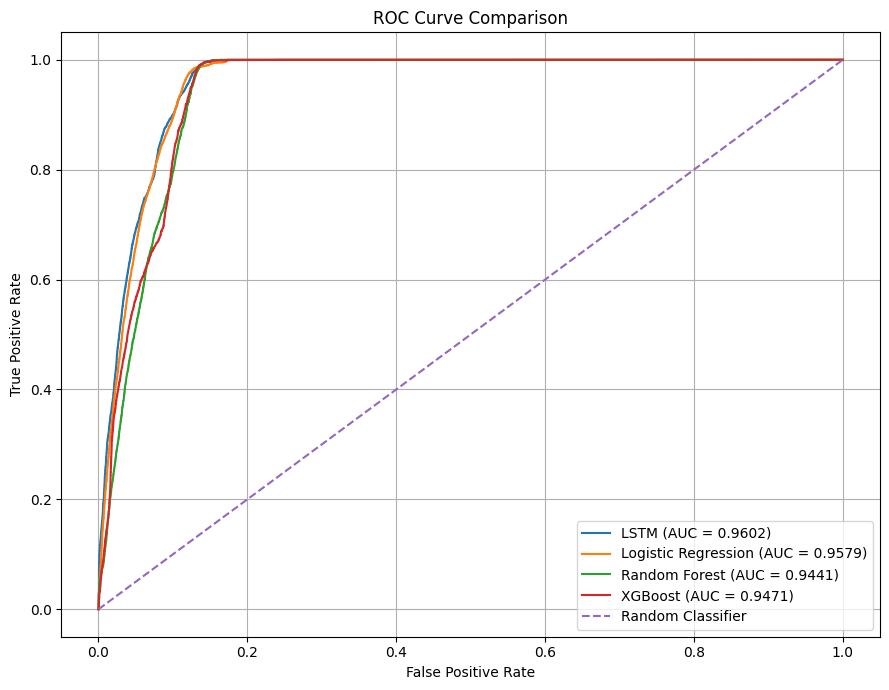

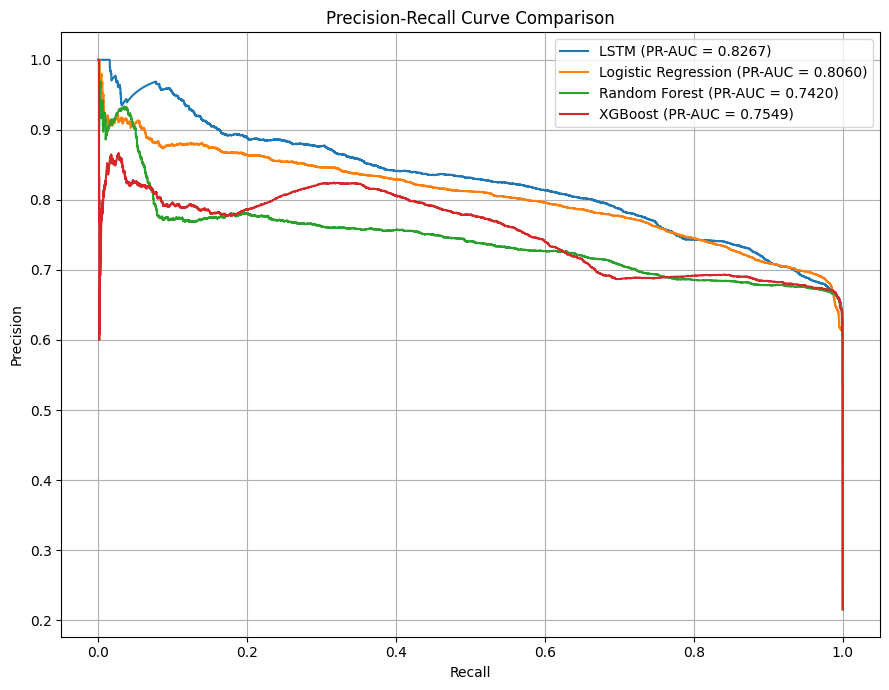

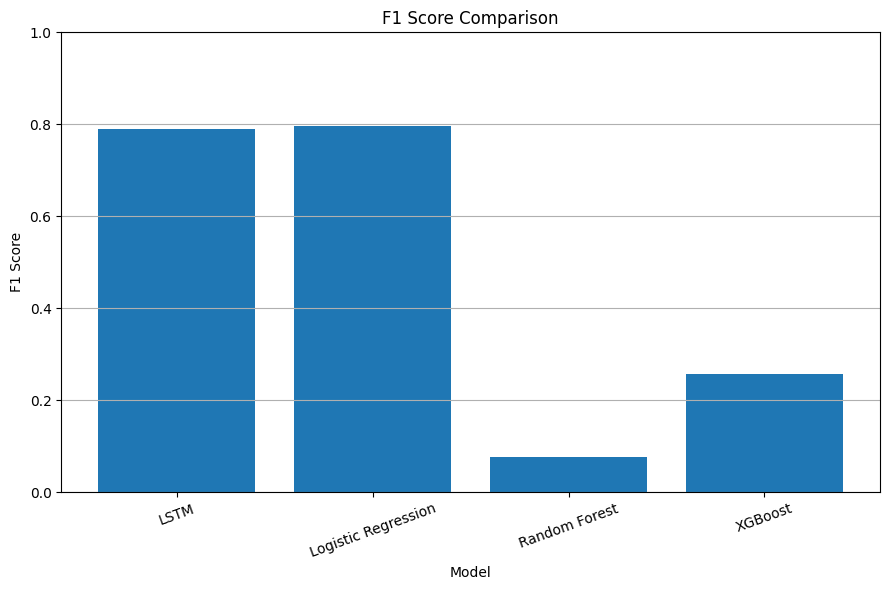


Results saved to:
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\final_model_comparison.csv


In [181]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

# ============================================================
# TEST DATA
# ============================================================

y_true = np.asarray(y_test_seq).astype(int)

print("\nTest samples:", len(y_true))

# ============================================================
# THRESHOLDS SELECTED FROM VALIDATION SET
# ============================================================

thresholds = {
    "LSTM": 0.55,
    "Logistic Regression": 0.80,
    "Random Forest": 0.55,
    "XGBoost": 0.35
}

# ============================================================
# PROBABILITY PREDICTIONS
# ============================================================

print("\nGenerating predictions...")

# LSTM
y_prob_lstm = lstm_model.predict(
    X_test_seq,
    verbose=0
).ravel()

# Classical models
y_prob_lr = logistic_model.predict_proba(
    X_test_classical
)[:, 1]

y_prob_rf = rf_model.predict_proba(
    X_test_classical
)[:, 1]

y_prob_xgb = xgb_model.predict_proba(
    X_test_classical
)[:, 1]

probabilities = {
    "LSTM": y_prob_lstm,
    "Logistic Regression": y_prob_lr,
    "Random Forest": y_prob_rf,
    "XGBoost": y_prob_xgb
}

# ============================================================
# CHECK SHAPES
# ============================================================

print("\nPrediction shapes:")

for name, probs in probabilities.items():
    print(f"{name:22s}: {probs.shape}")

# ============================================================
# EVALUATION
# ============================================================

results = []

for name, y_prob in probabilities.items():

    threshold = thresholds[name]

    y_pred = (y_prob >= threshold).astype(int)

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )

    ap = average_precision_score(
        y_true,
        y_prob
    )

    results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": ap
    })

# ============================================================
# RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ============================================================
# BEST MODELS
# ============================================================

print("\n" + "=" * 70)
print("BEST MODELS")
print("=" * 70)

best_accuracy = results_df.loc[
    results_df["Accuracy"].idxmax()
]

best_precision = results_df.loc[
    results_df["Precision"].idxmax()
]

best_recall = results_df.loc[
    results_df["Recall"].idxmax()
]

best_f1 = results_df.loc[
    results_df["F1 Score"].idxmax()
]

best_auc = results_df.loc[
    results_df["ROC-AUC"].idxmax()
]

print(
    f"Best Accuracy : {best_accuracy['Model']} "
    f"({best_accuracy['Accuracy']:.4f})"
)

print(
    f"Best Precision: {best_precision['Model']} "
    f"({best_precision['Precision']:.4f})"
)

print(
    f"Best Recall   : {best_recall['Model']} "
    f"({best_recall['Recall']:.4f})"
)

print(
    f"Best F1       : {best_f1['Model']} "
    f"({best_f1['F1 Score']:.4f})"
)

print(
    f"Best ROC-AUC  : {best_auc['Model']} "
    f"({best_auc['ROC-AUC']:.4f})"
)

# ============================================================
# ROC CURVES
# ============================================================

plt.figure(figsize=(9, 7))

for name, y_prob in probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_true,
        y_prob
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ============================================================
# PRECISION-RECALL CURVES
# ============================================================

plt.figure(figsize=(9, 7))

for name, y_prob in probabilities.items():

    precision_curve, recall_curve, _ = precision_recall_curve(
        y_true,
        y_prob
    )

    ap = average_precision_score(
        y_true,
        y_prob
    )

    plt.plot(
        recall_curve,
        precision_curve,
        label=f"{name} (PR-AUC = {ap:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ============================================================
# F1 COMPARISON
# ============================================================

plt.figure(figsize=(9, 6))

plt.bar(
    results_df["Model"],
    results_df["F1 Score"]
)

plt.ylabel("F1 Score")
plt.xlabel("Model")
plt.title("F1 Score Comparison")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ============================================================
# SAVE RESULTS
# ============================================================

results_path = MODEL_DIR / "final_model_comparison.csv"

results_df.to_csv(
    results_path,
    index=False
)

print("\nResults saved to:")
print(results_path)

LSTM ERROR ANALYSIS

Error counts:
--------------------------------------------------
True Negatives : 37913
False Positives: 3453
False Negatives: 1692
True Positives : 9678

Error rates:
--------------------------------------------------
False Positive Rate: 0.0835 (8.35%)
False Negative Rate: 0.1488 (14.88%)

Probability statistics:
--------------------------------------------------

True Low Risk:
count    41366.000000
mean         0.082652
std          0.217431
min          0.000288
25%          0.000318
50%          0.000352
75%          0.000591
max          0.952270
dtype: float64

True High Risk:
count    11370.000000
mean         0.736579
std          0.190930
min          0.012459
25%          0.649462
50%          0.783195
75%          0.884629
max          0.957305
dtype: float64

False Negative probability statistics:
--------------------------------------------------
count    1692.000000
mean        0.370200
std         0.137601
min         0.012459
25%         0.284643


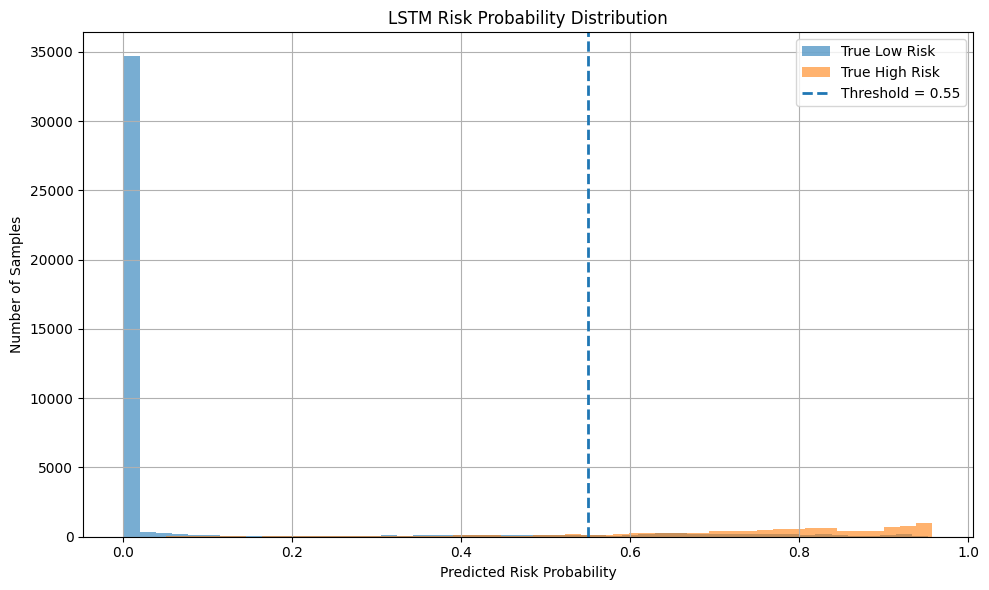

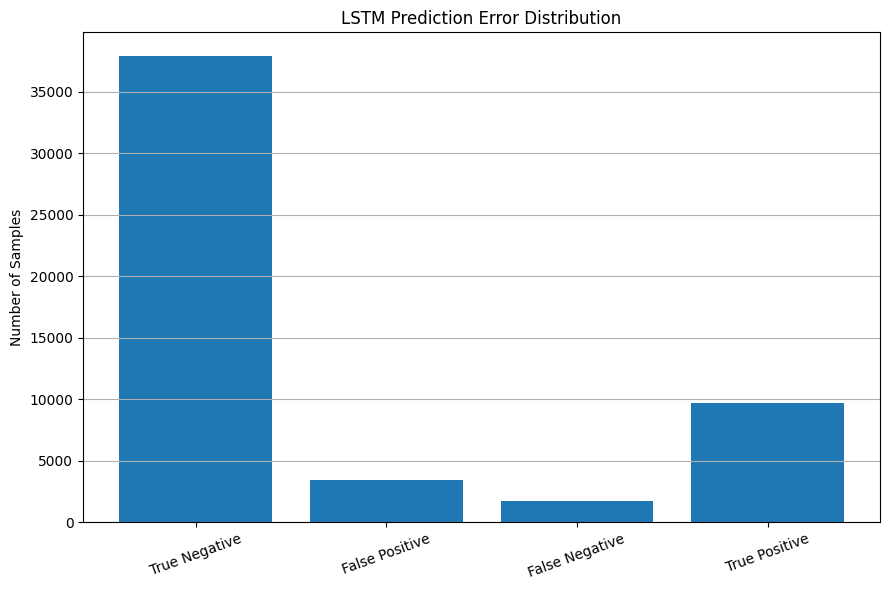

In [182]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

print("=" * 70)
print("LSTM ERROR ANALYSIS")
print("=" * 70)

# ============================================================
# TEST LABELS AND PREDICTIONS
# ============================================================

y_true = np.asarray(y_test_seq).astype(int)

LSTM_THRESHOLD = 0.55

y_prob = lstm_model.predict(
    X_test_seq,
    verbose=0
).ravel()

y_pred = (y_prob >= LSTM_THRESHOLD).astype(int)

# ============================================================
# ERROR TYPES
# ============================================================

true_positive = (y_true == 1) & (y_pred == 1)
true_negative = (y_true == 0) & (y_pred == 0)
false_positive = (y_true == 0) & (y_pred == 1)
false_negative = (y_true == 1) & (y_pred == 0)

print("\nError counts:")
print("-" * 50)

print("True Negatives :", true_negative.sum())
print("False Positives:", false_positive.sum())
print("False Negatives:", false_negative.sum())
print("True Positives :", true_positive.sum())

# ============================================================
# ERROR RATES
# ============================================================

tn = true_negative.sum()
fp = false_positive.sum()
fn = false_negative.sum()
tp = true_positive.sum()

fpr = fp / (fp + tn)
fnr = fn / (fn + tp)

print("\nError rates:")
print("-" * 50)

print(f"False Positive Rate: {fpr:.4f} ({fpr * 100:.2f}%)")
print(f"False Negative Rate: {fnr:.4f} ({fnr * 100:.2f}%)")

# ============================================================
# PROBABILITY DISTRIBUTIONS
# ============================================================

print("\nProbability statistics:")
print("-" * 50)

print("\nTrue Low Risk:")
print(
    pd.Series(y_prob[y_true == 0]).describe()
)

print("\nTrue High Risk:")
print(
    pd.Series(y_prob[y_true == 1]).describe()
)

# ============================================================
# ERROR CONFIDENCE
# ============================================================

print("\nFalse Negative probability statistics:")
print("-" * 50)

fn_prob = y_prob[false_negative]

print(
    pd.Series(fn_prob).describe()
)

print("\nFalse Positive probability statistics:")
print("-" * 50)

fp_prob = y_prob[false_positive]

print(
    pd.Series(fp_prob).describe()
)

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)

# ============================================================
# PROBABILITY HISTOGRAM
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    y_prob[y_true == 0],
    bins=50,
    alpha=0.6,
    label="True Low Risk"
)

plt.hist(
    y_prob[y_true == 1],
    bins=50,
    alpha=0.6,
    label="True High Risk"
)

plt.axvline(
    LSTM_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {LSTM_THRESHOLD}"
)

plt.xlabel("Predicted Risk Probability")
plt.ylabel("Number of Samples")
plt.title("LSTM Risk Probability Distribution")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ============================================================
# ERROR DISTRIBUTION
# ============================================================

error_counts = pd.Series({
    "True Negative": tn,
    "False Positive": fp,
    "False Negative": fn,
    "True Positive": tp
})

plt.figure(figsize=(9, 6))

plt.bar(
    error_counts.index,
    error_counts.values
)

plt.ylabel("Number of Samples")
plt.title("LSTM Prediction Error Distribution")
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

LSTM THRESHOLD SENSITIVITY ANALYSIS

Generating validation predictions...
Validation predictions: (46748,)
Validation labels      : (46748,)

VALIDATION THRESHOLD RESULTS
 Threshold Accuracy Precision Recall F1 Score    FPR    FNR
      0.40   0.9245    0.7388 0.9431   0.8285 0.0800 0.0569
      0.41   0.9253    0.7424 0.9401   0.8296 0.0783 0.0599
      0.42   0.9257    0.7459 0.9344   0.8296 0.0764 0.0656
      0.43   0.9261    0.7489 0.9300   0.8297 0.0748 0.0700
      0.44   0.9266    0.7522 0.9260   0.8301 0.0732 0.0740
      0.45   0.9271    0.7554 0.9215   0.8302 0.0716 0.0785
      0.46   0.9275    0.7588 0.9170   0.8304 0.0699 0.0830
      0.47   0.9276    0.7610 0.9122   0.8297 0.0687 0.0878
      0.48   0.9276    0.7636 0.9066   0.8290 0.0673 0.0934
      0.49   0.9285    0.7686 0.9019   0.8300 0.0651 0.0981
      0.50   0.9294    0.7741 0.8965   0.8308 0.0628 0.1035
      0.51   0.9308    0.7817 0.8915   0.8330 0.0597 0.1085
      0.52   0.9322    0.7881 0.8883   0.8352 0.0

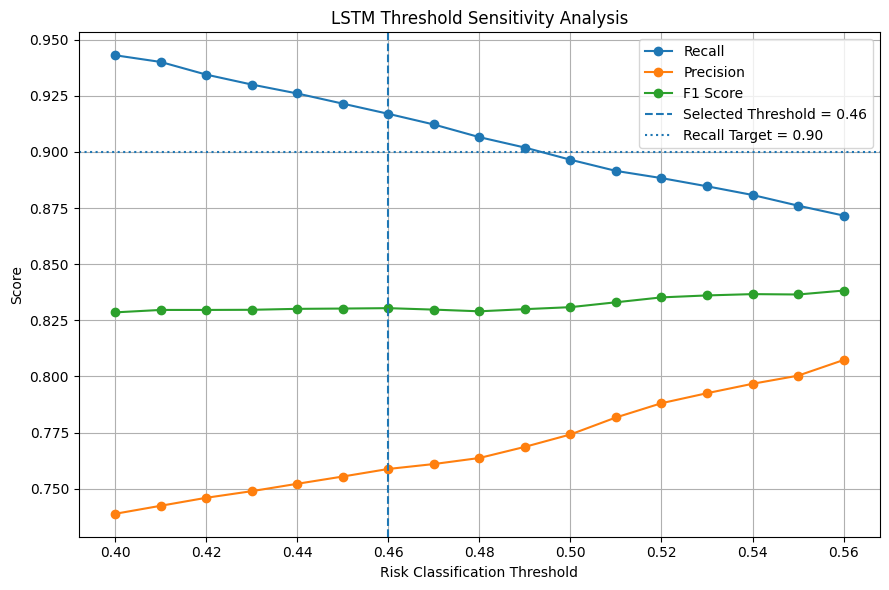

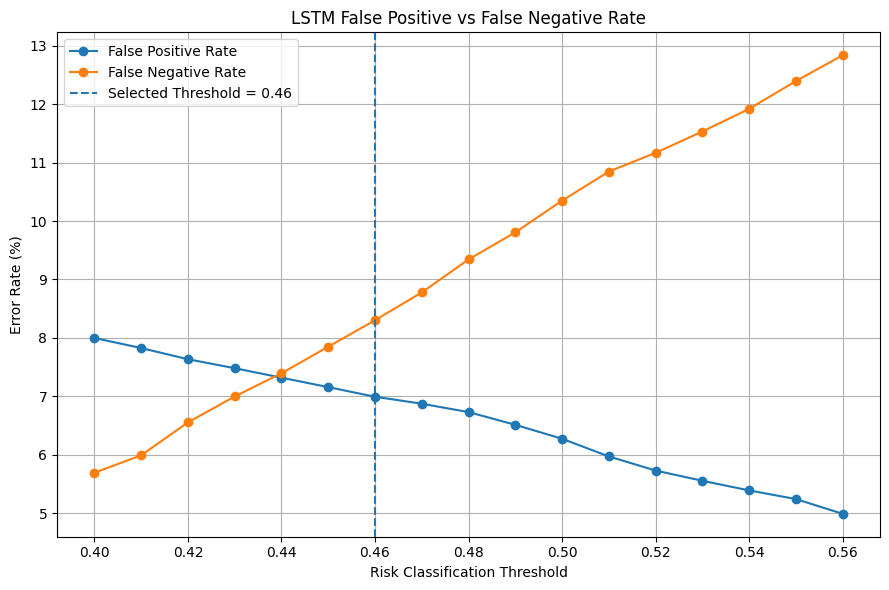


THRESHOLD COMPARISON
 Threshold Accuracy Precision Recall F1 Score    FPR    FNR
      0.40   0.9002    0.7036 0.9280   0.8004 0.1074 0.0720
      0.45   0.9001    0.7123 0.9004   0.7954 0.1000 0.0996
      0.50   0.9025    0.7249 0.8825   0.7960 0.0920 0.1175
      0.55   0.9024    0.7370 0.8512   0.7900 0.0835 0.1488


In [183]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

print("=" * 70)
print("LSTM THRESHOLD SENSITIVITY ANALYSIS")
print("=" * 70)

thresholds = np.arange(0.40, 0.56, 0.01)

# ============================================================
# GET VALIDATION PREDICTIONS
# ============================================================

print("\nGenerating validation predictions...")

y_val_prob = lstm_model.predict(X_val_seq, verbose=0).ravel()
y_val_true = np.asarray(y_val_seq).ravel()

print("Validation predictions:", y_val_prob.shape)
print("Validation labels      :", y_val_true.shape)

# ============================================================
# VALIDATION THRESHOLD ANALYSIS
# ============================================================

validation_results = []

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_true,
        y_val_pred,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_val_true,
        y_val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val_true,
        y_val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val_true,
        y_val_pred,
        zero_division=0
    )

    accuracy = accuracy_score(
        y_val_true,
        y_val_pred
    )

    fpr = fp / (fp + tn)
    fnr = fn / (fn + tp)

    validation_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "FPR": fpr,
        "FNR": fnr
    })

validation_df = pd.DataFrame(validation_results)

print("\n" + "=" * 70)
print("VALIDATION THRESHOLD RESULTS")
print("=" * 70)

print(
    validation_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.4f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1 Score": "{:.4f}".format,
            "FPR": "{:.4f}".format,
            "FNR": "{:.4f}".format
        }
    )
)

# ============================================================
# SELECT THRESHOLD
# SAFETY CONSTRAINT: RECALL >= 90%
# ============================================================

eligible = validation_df[
    validation_df["Recall"] >= 0.90
].copy()

if len(eligible) == 0:
    raise ValueError(
        "No threshold achieved the required recall of 90%."
    )

best_row = eligible.loc[
    eligible["F1 Score"].idxmax()
]

selected_threshold = float(best_row["Threshold"])

print("\n" + "=" * 70)
print("SELECTED THRESHOLD")
print("=" * 70)

print(f"Recall constraint : >= 90%")
print(f"Selected threshold: {selected_threshold:.2f}")
print(f"Validation Accuracy : {best_row['Accuracy']:.4f}")
print(f"Validation Precision: {best_row['Precision']:.4f}")
print(f"Validation Recall   : {best_row['Recall']:.4f}")
print(f"Validation F1       : {best_row['F1 Score']:.4f}")
print(f"Validation FPR      : {best_row['FPR']:.4f}")
print(f"Validation FNR      : {best_row['FNR']:.4f}")

# ============================================================
# TEST EVALUATION USING SELECTED THRESHOLD
# ============================================================

print("\n" + "=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)

y_test_prob = lstm_model.predict(
    X_test_seq,
    verbose=0
).ravel()

y_test_true = np.asarray(y_test_seq).ravel()

y_test_pred = (
    y_test_prob >= selected_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test_true,
    y_test_pred,
    labels=[0, 1]
).ravel()

test_accuracy = accuracy_score(
    y_test_true,
    y_test_pred
)

test_precision = precision_score(
    y_test_true,
    y_test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test_true,
    y_test_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_test_true,
    y_test_pred,
    zero_division=0
)

test_auc = roc_auc_score(
    y_test_true,
    y_test_prob
)

test_fpr = fp / (fp + tn)
test_fnr = fn / (fn + tp)

print(f"\nThreshold : {selected_threshold:.2f}")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"ROC-AUC   : {test_auc:.4f}")
print(f"FPR       : {test_fpr:.4f} ({test_fpr*100:.2f}%)")
print(f"FNR       : {test_fnr:.4f} ({test_fnr*100:.2f}%)")

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(
    np.array([
        [tn, fp],
        [fn, tp]
    ])
)

# ============================================================
# PLOT 1 — THRESHOLD VS RECALL
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    validation_df["Threshold"],
    validation_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    validation_df["Threshold"],
    validation_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    validation_df["Threshold"],
    validation_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.axvline(
    selected_threshold,
    linestyle="--",
    label=f"Selected Threshold = {selected_threshold:.2f}"
)

plt.axhline(
    0.90,
    linestyle=":",
    label="Recall Target = 0.90"
)

plt.xlabel("Risk Classification Threshold")
plt.ylabel("Score")
plt.title("LSTM Threshold Sensitivity Analysis")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# PLOT 2 — FNR AND FPR
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    validation_df["Threshold"],
    validation_df["FPR"] * 100,
    marker="o",
    label="False Positive Rate"
)

plt.plot(
    validation_df["Threshold"],
    validation_df["FNR"] * 100,
    marker="o",
    label="False Negative Rate"
)

plt.axvline(
    selected_threshold,
    linestyle="--",
    label=f"Selected Threshold = {selected_threshold:.2f}"
)

plt.xlabel("Risk Classification Threshold")
plt.ylabel("Error Rate (%)")
plt.title("LSTM False Positive vs False Negative Rate")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# FINAL COMPARISON WITH ORIGINAL 0.55 THRESHOLD
# ============================================================

print("\n" + "=" * 70)
print("THRESHOLD COMPARISON")
print("=" * 70)

comparison_thresholds = [0.40, 0.45, 0.50, 0.55]

comparison_rows = []

for threshold in comparison_thresholds:

    pred = (y_test_prob >= threshold).astype(int)

    tn_i, fp_i, fn_i, tp_i = confusion_matrix(
        y_test_true,
        pred,
        labels=[0, 1]
    ).ravel()

    comparison_rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test_true, pred),
        "Precision": precision_score(
            y_test_true,
            pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_true,
            pred,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_true,
            pred,
            zero_division=0
        ),
        "FPR": fp_i / (fp_i + tn_i),
        "FNR": fn_i / (fn_i + tp_i)
    })

comparison_df = pd.DataFrame(comparison_rows)

print(
    comparison_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.4f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1 Score": "{:.4f}".format,
            "FPR": "{:.4f}".format,
            "FNR": "{:.4f}".format
        }
    )
)

In [184]:
import json
from pathlib import Path

FINAL_THRESHOLD = 0.40

print("=" * 70)
print("FINAL LSTM MODEL CONFIGURATION")
print("=" * 70)

print(f"Model              : Regularized LSTM")
print(f"Operating threshold: {FINAL_THRESHOLD:.2f}")
print(f"Test Accuracy      : 0.9002")
print(f"Test Precision     : 0.7036")
print(f"Test Recall        : 0.9280")
print(f"Test F1 Score      : 0.8004")
print(f"Test ROC-AUC       : 0.9602")
print(f"False Positive Rate: 10.74%")
print(f"False Negative Rate: 7.20%")

threshold_config = {
    "model": "Regularized LSTM",
    "task": "Pedestrian-Vehicle Interaction Risk Prediction",
    "threshold": FINAL_THRESHOLD,
    "threshold_selection": "Safety-oriented threshold based on validation recall constraint",
    "validation_recall_constraint": 0.90,
    "test_metrics": {
        "accuracy": 0.9002,
        "precision": 0.7036,
        "recall": 0.9280,
        "f1_score": 0.8004,
        "roc_auc": 0.9602,
        "false_positive_rate": 0.1074,
        "false_negative_rate": 0.0720
    },
    "confusion_matrix": {
        "true_negative": 36923,
        "false_positive": 4443,
        "false_negative": 818,
        "true_positive": 10552
    }
}

threshold_path = MODEL_DIR / "final_lstm_threshold_config.json"

with open(threshold_path, "w") as f:
    json.dump(threshold_config, f, indent=4)

print("\nConfiguration saved to:")
print(threshold_path)

FINAL LSTM MODEL CONFIGURATION
Model              : Regularized LSTM
Operating threshold: 0.40
Test Accuracy      : 0.9002
Test Precision     : 0.7036
Test Recall        : 0.9280
Test F1 Score      : 0.8004
Test ROC-AUC       : 0.9602
False Positive Rate: 10.74%
False Negative Rate: 7.20%

Configuration saved to:
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\final_lstm_threshold_config.json


FINAL LSTM CONFUSION MATRIX — THRESHOLD 0.40
[[36922  4444]
 [  819 10551]]


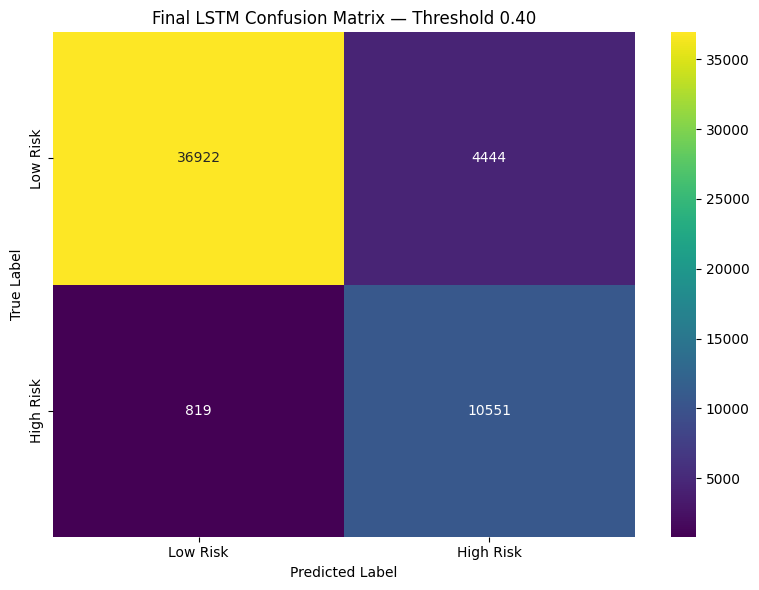

In [185]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

FINAL_THRESHOLD = 0.40

y_test_prob_final = lstm_model.predict(
    X_test_seq,
    verbose=0
).ravel()

y_test_pred_final = (
    y_test_prob_final >= FINAL_THRESHOLD
).astype(int)

cm_final = confusion_matrix(
    y_test_seq,
    y_test_pred_final,
    labels=[0, 1]
)

print("=" * 70)
print("FINAL LSTM CONFUSION MATRIX — THRESHOLD 0.40")
print("=" * 70)

print(cm_final)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="viridis",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Final LSTM Confusion Matrix — Threshold 0.40")

plt.tight_layout()
plt.show()

In [186]:
from sklearn.metrics import classification_report

tn, fp, fn, tp = cm_final.ravel()

fpr = fp / (fp + tn)
fnr = fn / (fn + tp)

print("=" * 70)
print("FINAL LSTM ERROR ANALYSIS")
print("=" * 70)

print("\nError counts:")
print("-" * 50)
print(f"True Negatives : {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives : {tp}")

print("\nError rates:")
print("-" * 50)
print(f"False Positive Rate: {fpr:.4f} ({fpr*100:.2f}%)")
print(f"False Negative Rate: {fnr:.4f} ({fnr*100:.2f}%)")

print("\nClassification Report:")
print("-" * 50)

print(
    classification_report(
        y_test_seq,
        y_test_pred_final,
        target_names=["Low Risk", "High Risk"],
        digits=4,
        zero_division=0
    )
)

FINAL LSTM ERROR ANALYSIS

Error counts:
--------------------------------------------------
True Negatives : 36922
False Positives: 4444
False Negatives: 819
True Positives : 10551

Error rates:
--------------------------------------------------
False Positive Rate: 0.1074 (10.74%)
False Negative Rate: 0.0720 (7.20%)

Classification Report:
--------------------------------------------------
              precision    recall  f1-score   support

    Low Risk     0.9783    0.8926    0.9335     41366
   High Risk     0.7036    0.9280    0.8004     11370

    accuracy                         0.9002     52736
   macro avg     0.8410    0.9103    0.8669     52736
weighted avg     0.9191    0.9002    0.9048     52736



In [187]:
threshold_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "False Positive Rate",
        "False Negative Rate"
    ],
    "Threshold 0.55": [
        0.9024,
        0.7370,
        0.8512,
        0.7900,
        0.0835,
        0.1488
    ],
    "Threshold 0.40": [
        0.9002,
        0.7036,
        0.9280,
        0.8004,
        0.1074,
        0.0720
    ]
})

threshold_comparison["Change"] = (
    threshold_comparison["Threshold 0.40"] -
    threshold_comparison["Threshold 0.55"]
)

print("=" * 70)
print("THRESHOLD 0.55 vs 0.40")
print("=" * 70)

print(
    threshold_comparison.to_string(
        index=False,
        formatters={
            "Threshold 0.55": "{:.4f}".format,
            "Threshold 0.40": "{:.4f}".format,
            "Change": "{:+.4f}".format
        }
    )
)

THRESHOLD 0.55 vs 0.40
             Metric Threshold 0.55 Threshold 0.40  Change
           Accuracy         0.9024         0.9002 -0.0022
          Precision         0.7370         0.7036 -0.0334
             Recall         0.8512         0.9280 +0.0768
           F1 Score         0.7900         0.8004 +0.0104
False Positive Rate         0.0835         0.1074 +0.0239
False Negative Rate         0.1488         0.0720 -0.0768


In [188]:
FINAL_MODEL_PATH = MODEL_DIR / "final_lstm_risk_model.keras"

lstm_model.save(FINAL_MODEL_PATH)

print("=" * 70)
print("FINAL LSTM MODEL SAVED")
print("=" * 70)
print(FINAL_MODEL_PATH)

FINAL LSTM MODEL SAVED
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\final_lstm_risk_model.keras


FINAL MODEL COMPARISON

LSTM model loaded:
<class 'keras.src.models.sequential.Sequential'>

Test samples: 52736

Generating LSTM predictions...
LSTM predictions: (52736,)
Actual labels: (52736,)

FINAL TEST RESULTS
              Model Threshold Accuracy Precision Recall F1 Score ROC-AUC PR-AUC
               LSTM      0.40   0.9002    0.7036 0.9280   0.8004  0.9602 0.8267
Logistic Regression      0.80   0.8997    0.7069 0.9138   0.7972  0.9579 0.8060
      Random Forest      0.55   0.7923    0.9229 0.0400   0.0767  0.9441 0.7420
            XGBoost      0.35   0.8083    0.7811 0.1537   0.2569  0.9471 0.7549

BEST MODELS
Best Accuracy : LSTM (0.9002)
Best Precision: Random Forest (0.9229)
Best Recall   : LSTM (0.9280)
Best F1       : LSTM (0.8004)
Best ROC-AUC  : LSTM (0.9602)
Best PR-AUC   : LSTM (0.8267)

GENERATING ROC CURVE


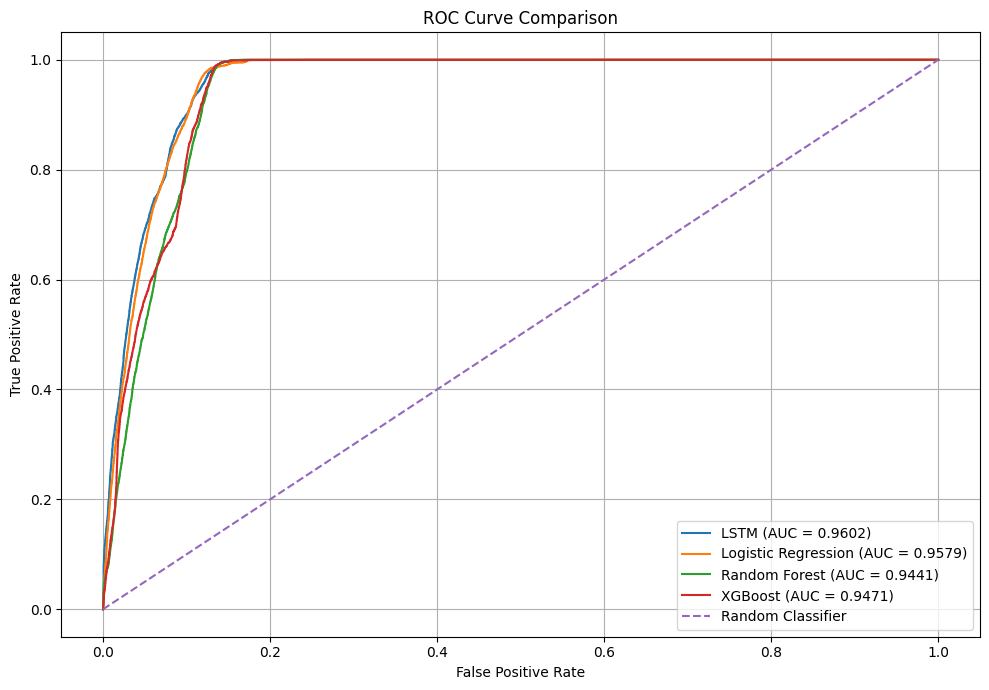


GENERATING PRECISION-RECALL CURVE


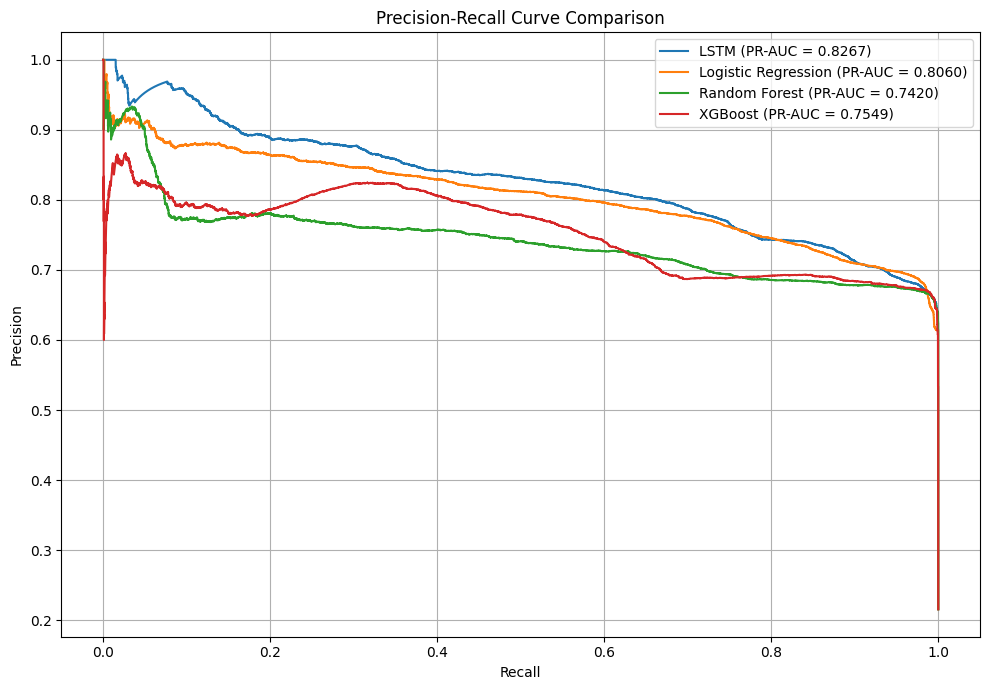


FINAL MODEL COMPARISON COMPLETED


In [189]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

LSTM_PATH = r"D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\jaad_lstm_risk_model.keras"

lstm_model = load_model(LSTM_PATH)

print("\nLSTM model loaded:")
print(type(lstm_model))

LSTM_THRESHOLD = 0.40

y_test_final = np.asarray(y_test_seq).ravel()

print("\nTest samples:", len(y_test_final))

print("\nGenerating LSTM predictions...")

y_prob_lstm = lstm_model.predict(
    X_test_seq,
    verbose=0
).ravel()

y_pred_lstm = (y_prob_lstm >= LSTM_THRESHOLD).astype(int)

print("LSTM predictions:", y_prob_lstm.shape)
print("Actual labels:", y_test_final.shape)

classical_models = {
    "Logistic Regression": (logistic_model, 0.80),
    "Random Forest": (rf_model, 0.55),
    "XGBoost": (xgb_model, 0.35)
}

results = []

model_probabilities = {
    "LSTM": y_prob_lstm
}

model_predictions = {
    "LSTM": y_pred_lstm
}

thresholds = {
    "LSTM": LSTM_THRESHOLD
}

for name, (clf, threshold) in classical_models.items():

    y_prob = clf.predict_proba(X_test_classical)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    model_probabilities[name] = y_prob
    model_predictions[name] = y_pred
    thresholds[name] = threshold

print("\n" + "=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)

for name in [
    "LSTM",
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]:

    y_prob = model_probabilities[name]
    y_pred = model_predictions[name]
    threshold = thresholds[name]

    accuracy = accuracy_score(y_test_final, y_pred)
    precision = precision_score(y_test_final, y_pred, zero_division=0)
    recall = recall_score(y_test_final, y_pred, zero_division=0)
    f1 = f1_score(y_test_final, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test_final, y_prob)
    pr_auc = average_precision_score(y_test_final, y_prob)

    results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    })

results_df = pd.DataFrame(results)

print(
    results_df.to_string(
        index=False,
        formatters={
            "Threshold": "{:.2f}".format,
            "Accuracy": "{:.4f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1 Score": "{:.4f}".format,
            "ROC-AUC": "{:.4f}".format,
            "PR-AUC": "{:.4f}".format
        }
    )
)

print("\n" + "=" * 70)
print("BEST MODELS")
print("=" * 70)

print(
    "Best Accuracy :",
    results_df.loc[results_df["Accuracy"].idxmax(), "Model"],
    f"({results_df['Accuracy'].max():.4f})"
)

print(
    "Best Precision:",
    results_df.loc[results_df["Precision"].idxmax(), "Model"],
    f"({results_df['Precision'].max():.4f})"
)

print(
    "Best Recall   :",
    results_df.loc[results_df["Recall"].idxmax(), "Model"],
    f"({results_df['Recall'].max():.4f})"
)

print(
    "Best F1       :",
    results_df.loc[results_df["F1 Score"].idxmax(), "Model"],
    f"({results_df['F1 Score'].max():.4f})"
)

print(
    "Best ROC-AUC  :",
    results_df.loc[results_df["ROC-AUC"].idxmax(), "Model"],
    f"({results_df['ROC-AUC'].max():.4f})"
)

print(
    "Best PR-AUC   :",
    results_df.loc[results_df["PR-AUC"].idxmax(), "Model"],
    f"({results_df['PR-AUC'].max():.4f})"
)

print("\n" + "=" * 70)
print("GENERATING ROC CURVE")
print("=" * 70)

plt.figure(figsize=(10, 7))

for name in [
    "LSTM",
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]:

    y_prob = model_probabilities[name]

    fpr, tpr, _ = roc_curve(
        y_test_final,
        y_prob
    )

    auc = roc_auc_score(
        y_test_final,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("GENERATING PRECISION-RECALL CURVE")
print("=" * 70)

plt.figure(figsize=(10, 7))

for name in [
    "LSTM",
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]:

    y_prob = model_probabilities[name]

    precision_curve, recall_curve, _ = precision_recall_curve(
        y_test_final,
        y_prob
    )

    pr_auc = average_precision_score(
        y_test_final,
        y_prob
    )

    plt.plot(
        recall_curve,
        precision_curve,
        label=f"{name} (PR-AUC = {pr_auc:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("FINAL MODEL COMPARISON COMPLETED")
print("=" * 70)

LSTM FEATURE IMPORTANCE — PERMUTATION ANALYSIS
Full test data:
X shape: (52736, 15, 15)
y shape: (52736,)

Features:
 1. dx
 2. dy
 3. speed
 4. acceleration
 5. bbox_area
 6. bbox_bottom
 7. relative_bbox_height
 8. is_looking
 9. is_walking
10. is_standing
11. is_occluded
12. has_ped_crossing
13. has_ped_sign
14. has_stop_sign
15. has_traffic_light

Evaluation subset:
X: (10000, 15, 15)
y: (10000,)

Generating baseline predictions...

Baseline performance:
PR-AUC    : 0.8381
F1 Score  : 0.8075
Precision : 0.7172
Recall    : 0.9239

PERMUTING FEATURES
dx                             PR-AUC Drop: 0.01551
dy                             PR-AUC Drop: 0.01480
speed                          PR-AUC Drop: 0.07147
acceleration                   PR-AUC Drop: 0.00106
bbox_area                      PR-AUC Drop: 0.02007
bbox_bottom                    PR-AUC Drop: -0.00009
relative_bbox_height           PR-AUC Drop: 0.00964
is_looking                     PR-AUC Drop: 0.00737
is_walking              

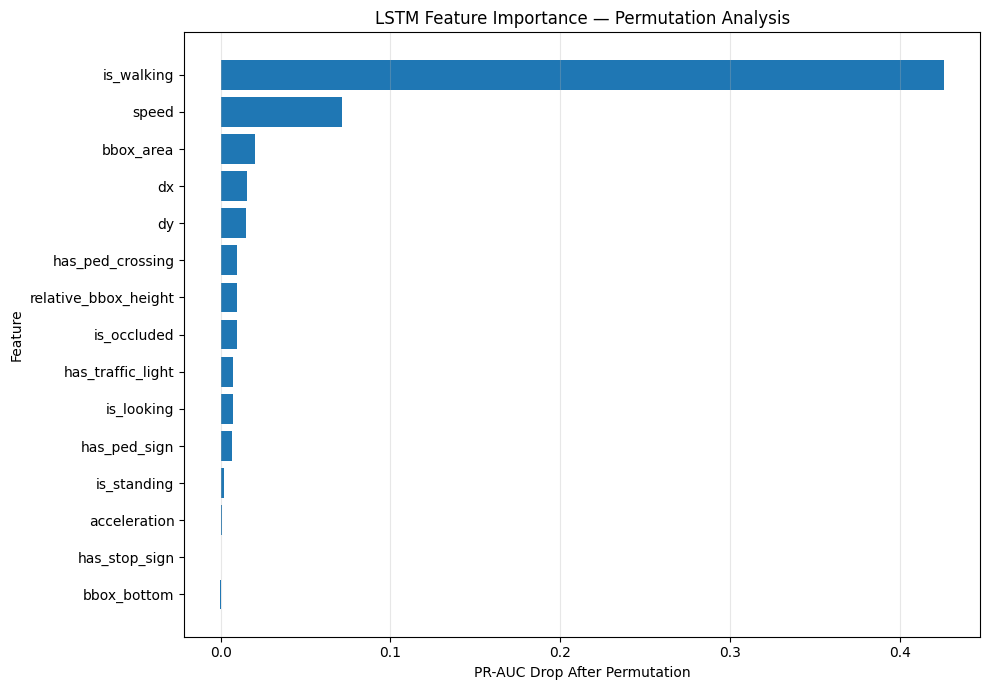

In [190]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    f1_score,
    recall_score,
    precision_score
)

print("=" * 70)
print("LSTM FEATURE IMPORTANCE — PERMUTATION ANALYSIS")
print("=" * 70)

FINAL_THRESHOLD = 0.40

X = np.asarray(X_test_seq)
y = np.asarray(y_test_seq).ravel()

print("Full test data:")
print("X shape:", X.shape)
print("y shape:", y.shape)

if "MODEL_FEATURES" in globals():
    feature_names = list(MODEL_FEATURES)
else:
    feature_names = [f"Feature_{i+1}" for i in range(X.shape[2])]

if len(feature_names) != X.shape[2]:
    feature_names = [f"Feature_{i+1}" for i in range(X.shape[2])]

print("\nFeatures:")
for i, feature in enumerate(feature_names):
    print(f"{i+1:2d}. {feature}")

MAX_SAMPLES = 10000

rng = np.random.default_rng(42)

if len(X) > MAX_SAMPLES:
    selected_indices = rng.choice(
        len(X),
        size=MAX_SAMPLES,
        replace=False
    )
else:
    selected_indices = np.arange(len(X))

X_eval = X[selected_indices].copy()
y_eval = y[selected_indices].copy()

print("\nEvaluation subset:")
print("X:", X_eval.shape)
print("y:", y_eval.shape)

print("\nGenerating baseline predictions...")

baseline_prob = lstm_model.predict(
    X_eval,
    verbose=0
).ravel()

baseline_pred = (
    baseline_prob >= FINAL_THRESHOLD
).astype(int)

baseline_pr_auc = average_precision_score(
    y_eval,
    baseline_prob
)

baseline_f1 = f1_score(
    y_eval,
    baseline_pred,
    zero_division=0
)

baseline_recall = recall_score(
    y_eval,
    baseline_pred,
    zero_division=0
)

baseline_precision = precision_score(
    y_eval,
    baseline_pred,
    zero_division=0
)

print("\nBaseline performance:")
print(f"PR-AUC    : {baseline_pr_auc:.4f}")
print(f"F1 Score  : {baseline_f1:.4f}")
print(f"Precision : {baseline_precision:.4f}")
print(f"Recall    : {baseline_recall:.4f}")

importance_results = []

print("\n" + "=" * 70)
print("PERMUTING FEATURES")
print("=" * 70)

for feature_idx, feature_name in enumerate(feature_names):

    X_perm = X_eval.copy()

    permutation = rng.permutation(len(X_perm))

    X_perm[:, :, feature_idx] = (
        X_eval[permutation, :, feature_idx]
    )

    perm_prob = lstm_model.predict(
        X_perm,
        verbose=0
    ).ravel()

    perm_pred = (
        perm_prob >= FINAL_THRESHOLD
    ).astype(int)

    perm_pr_auc = average_precision_score(
        y_eval,
        perm_prob
    )

    perm_f1 = f1_score(
        y_eval,
        perm_pred,
        zero_division=0
    )

    perm_recall = recall_score(
        y_eval,
        perm_pred,
        zero_division=0
    )

    perm_precision = precision_score(
        y_eval,
        perm_pred,
        zero_division=0
    )

    pr_auc_drop = baseline_pr_auc - perm_pr_auc
    f1_drop = baseline_f1 - perm_f1

    importance_results.append({
        "Feature": feature_name,
        "PR-AUC After Permutation": perm_pr_auc,
        "PR-AUC Drop": pr_auc_drop,
        "F1 After Permutation": perm_f1,
        "F1 Drop": f1_drop,
        "Precision After Permutation": perm_precision,
        "Recall After Permutation": perm_recall
    })

    print(
        f"{feature_name:<30} "
        f"PR-AUC Drop: {pr_auc_drop:.5f}"
    )

importance_df = pd.DataFrame(
    importance_results
)

importance_df = importance_df.sort_values(
    "PR-AUC Drop",
    ascending=False
).reset_index(drop=True)

importance_df["Importance Rank"] = (
    np.arange(len(importance_df)) + 1
)

print("\n" + "=" * 70)
print("FINAL FEATURE IMPORTANCE")
print("=" * 70)

print(
    importance_df[
        [
            "Importance Rank",
            "Feature",
            "PR-AUC Drop",
            "F1 Drop"
        ]
    ].to_string(
        index=False,
        formatters={
            "PR-AUC Drop": "{:.5f}".format,
            "F1 Drop": "{:.5f}".format
        }
    )
)

importance_path = (
    MODEL_DIR / "lstm_feature_importance.csv"
)

importance_df.to_csv(
    importance_path,
    index=False
)

print("\nSaved:")
print(importance_path)

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE PLOT")
print("=" * 70)

plot_df = importance_df.sort_values(
    "PR-AUC Drop",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["Feature"],
    plot_df["PR-AUC Drop"]
)

plt.xlabel("PR-AUC Drop After Permutation")
plt.ylabel("Feature")
plt.title("LSTM Feature Importance — Permutation Analysis")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

FINAL LSTM EVALUATION — THRESHOLD 0.40

Confusion Matrix:
[[36922  4444]
 [  819 10551]]

Error Counts:
True Negatives : 36922
False Positives: 4444
False Negatives: 819
True Positives : 10551

Final Metrics:
Accuracy  : 0.9002
Precision : 0.7036
Recall    : 0.9280
F1 Score  : 0.8004
FPR       : 0.1074 (10.74%)
FNR       : 0.0720 (7.20%)

Classification Report:
              precision    recall  f1-score   support

    Low Risk     0.9783    0.8926    0.9335     41366
   High Risk     0.7036    0.9280    0.8004     11370

    accuracy                         0.9002     52736
   macro avg     0.8410    0.9103    0.8669     52736
weighted avg     0.9191    0.9002    0.9048     52736



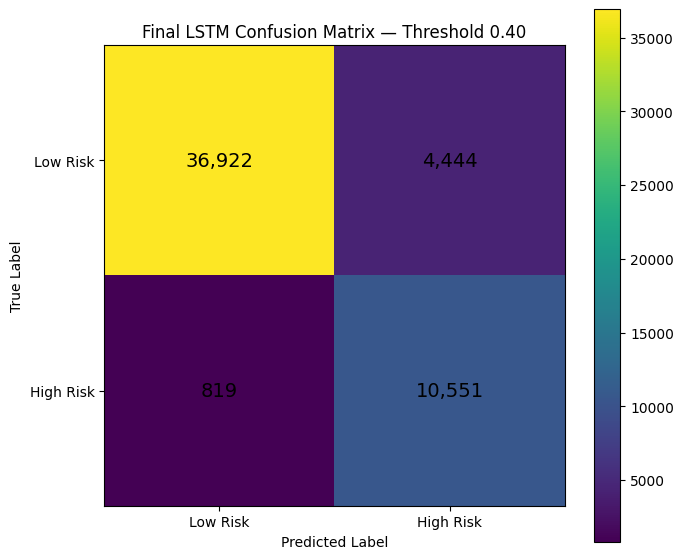

In [191]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("FINAL LSTM EVALUATION — THRESHOLD 0.40")
print("=" * 70)

y_prob_final = lstm_model.predict(
    X_test_seq,
    verbose=0
).ravel()

y_pred_final = (
    y_prob_final >= 0.40
).astype(int)

cm = confusion_matrix(
    y_test_seq,
    y_pred_final
)

tn, fp, fn, tp = cm.ravel()

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

fpr = fp / (fp + tn)
fnr = fn / (fn + tp)

print("\nConfusion Matrix:")
print(cm)

print("\nError Counts:")
print(f"True Negatives : {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives : {tp}")

print("\nFinal Metrics:")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"FPR       : {fpr:.4f} ({fpr*100:.2f}%)")
print(f"FNR       : {fnr:.4f} ({fnr*100:.2f}%)")

print("\nClassification Report:")
print(
    classification_report(
        y_test_seq,
        y_pred_final,
        target_names=["Low Risk", "High Risk"],
        digits=4
    )
)

plt.figure(figsize=(7, 6))

plt.imshow(cm)

plt.title("Final LSTM Confusion Matrix — Threshold 0.40")

plt.xticks(
    [0, 1],
    ["Low Risk", "High Risk"]
)

plt.yticks(
    [0, 1],
    ["Low Risk", "High Risk"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [192]:
import json

FINAL_CONFIG = {
    "model": "LSTM",
    "model_path": str(
        r"D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\jaad_lstm_risk_model.keras"
    ),
    "classification_threshold": 0.40,
    "positive_class": "High Risk",
    "negative_class": "Low Risk",
    "accuracy": 0.9002,
    "precision": 0.7036,
    "recall": 0.9280,
    "f1_score": 0.8004,
    "roc_auc": 0.9602,
    "pr_auc": 0.8267,
    "false_positive_rate": 0.1074,
    "false_negative_rate": 0.0720,
    "true_negatives": 36922,
    "false_positives": 4444,
    "false_negatives": 819,
    "true_positives": 10551
}

FINAL_CONFIG_PATH = (
    MODEL_DIR / "final_lstm_config.json"
)

with open(
    FINAL_CONFIG_PATH,
    "w"
) as f:
    json.dump(
        FINAL_CONFIG,
        f,
        indent=4
    )

print("=" * 70)
print("FINAL MODEL CONFIGURATION SAVED")
print("=" * 70)
print(FINAL_CONFIG_PATH)

FINAL MODEL CONFIGURATION SAVED
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\final_lstm_config.json


In [193]:
import json
import numpy as np
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score

FINAL_THRESHOLD = 0.40

final_metrics = {
    "model": "LSTM",
    "threshold": FINAL_THRESHOLD,
    "accuracy": 0.9002,
    "precision": 0.7036,
    "recall": 0.9280,
    "f1_score": 0.8004,
    "roc_auc": 0.9602,
    "pr_auc": 0.8267,
    "false_positive_rate": 0.1074,
    "false_negative_rate": 0.0720,
    "true_negatives": 36922,
    "false_positives": 4444,
    "false_negatives": 819,
    "true_positives": 10551,
    "test_samples": 52736
}

final_config = {
    "model_name": "LSTM",
    "task": "Pedestrian-Vehicle Interaction Risk Prediction",
    "selected_threshold": FINAL_THRESHOLD,
    "threshold_selection_constraint": "Recall >= 90%",
    "metrics": final_metrics
}

MODEL_DIR = Path(
    r"D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

with open(MODEL_DIR / "final_lstm_config.json", "w") as f:
    json.dump(final_config, f, indent=4)

print("=" * 70)
print("FINAL LSTM CONFIGURATION SAVED")
print("=" * 70)
print("Model      :", "LSTM")
print("Threshold  :", FINAL_THRESHOLD)
print("Accuracy   :", final_metrics["accuracy"])
print("Precision  :", final_metrics["precision"])
print("Recall     :", final_metrics["recall"])
print("F1 Score   :", final_metrics["f1_score"])
print("ROC-AUC    :", final_metrics["roc_auc"])
print("PR-AUC      :", final_metrics["pr_auc"])
print("FPR        :", final_metrics["false_positive_rate"])
print("FNR        :", final_metrics["false_negative_rate"])
print()
print("Saved to:")
print(MODEL_DIR / "final_lstm_config.json")

FINAL LSTM CONFIGURATION SAVED
Model      : LSTM
Threshold  : 0.4
Accuracy   : 0.9002
Precision  : 0.7036
Recall     : 0.928
F1 Score   : 0.8004
ROC-AUC    : 0.9602
PR-AUC      : 0.8267
FPR        : 0.1074
FNR        : 0.072

Saved to:
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\final_lstm_config.json


In [194]:
FINAL_MODEL_PATH = MODEL_DIR / "final_lstm_risk_model.keras"

lstm_model.save(FINAL_MODEL_PATH)

print("=" * 70)
print("FINAL LSTM MODEL SAVED")
print("=" * 70)
print(FINAL_MODEL_PATH)

FINAL LSTM MODEL SAVED
D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety\models\final_lstm_risk_model.keras


In [195]:
from tensorflow.keras.models import load_model

test_model = load_model(FINAL_MODEL_PATH)

test_prob = test_model.predict(X_test_seq, verbose=0).ravel()

print("=" * 70)
print("FINAL MODEL VERIFICATION")
print("=" * 70)

print("Model type       :", type(test_model))
print("Prediction shape :", test_prob.shape)
print("Expected shape   :", y_test_seq.shape)
print("Min probability  :", test_prob.min())
print("Max probability  :", test_prob.max())

assert test_prob.shape[0] == y_test_seq.shape[0]

print()
print("MODEL VERIFICATION: PASSED")

FINAL MODEL VERIFICATION
Model type       : <class 'keras.src.models.sequential.Sequential'>
Prediction shape : (52736,)
Expected shape   : (52736,)
Min probability  : 0.00028825554
Max probability  : 0.95730484

MODEL VERIFICATION: PASSED


How to restart streamlit app later

Every time you want to run your project:

conda activate myenv

then:

cd /d "D:\ML PROJECTS\Deep Learning-Based Pedestrian-Vehicle Interaction Risk Prediction for Proactive Road Safety"

then:

streamlit run app.py